# Flow 2 · Color de caras LEGO desde foto y máscara

**Primera ejecución de Flow 2.** Compara cross-attention y single-stream con supervisión limpia;
aplica después curriculum al ganador. VAE de color, Flow 1 y DINO quedan congelados.

**Inputs:** salida de color `lego_color_para_Flow2.zip`; salida de Flow 1 con `flow1_dito.pt`
y `pares_auditados.csv`; salida de geometría con `runs/dito_base/best.pt`; los datasets de fotos
PairLegoFace y SynHumanLegoFaces; LegosPartsVae y las intermedias RGBA. Se aceptan ZIP sin extraer
para los modelos. Activa Internet la primera vez para descargar DINOv2, o fija `DINO_LOCAL`.
No se reinstala PyTorch ni se fijan versiones de Hugging Face.

Los originales se preparan **sin redimensionar**, con el mismo marco de 128×128 del Flow 1.
Flow 2 entrena solo en la intersección de los train autorizados de Flow 1 y del codec de color.
El test se conserva para el final y se informa si la VAE había visto el objetivo.

**Curriculum:** A limpio; B deformaciones alineadas RGB-máscara; C predicciones cercanas con
pseudoetiquetas locales conservadoras. Si faltan ejemplos aceptados o no se cumplen las métricas,
no se fuerza la etapa C. El test generado incluye también las máscaras rechazadas para mostrar
los límites reales del sistema. Las pseudoetiquetas no equivalen a ground truth humano nuevo.

`SMOKE=True` comprueba infraestructura con pesos y datos artificiales. No valida calidad.
Al acabar se crea **UN ZIP con TODA la salida**, incluyendo best/last, estados, cachés, código y resultados.


## 1. Configuración
Resúmenes cada 100 actualizaciones. Cambia las rutas solo si hay varias versiones de un input. Para reanudar el ZIP completo, fija `REANUDAR_DE` antes de ejecutar.

In [1]:
FLOW1_MODEL_SOURCE = 'def rope_2d(dim_cabeza, lado=16):\n    d = dim_cabeza // 4\n    frec = 1.0 / (10000 ** (torch.arange(d) / d))\n    y, x = torch.meshgrid(torch.arange(lado), torch.arange(lado), indexing="ij")\n    ang = torch.cat([y.flatten()[:, None] * frec, x.flatten()[:, None] * frec], 1)   # 256 × dim/2\n    return torch.cos(ang), torch.sin(ang)\n\n\ndef aplicar_rope(x, cos, sin):                              # x: B×H×N×D\n    x1, x2 = x[..., 0::2], x[..., 1::2]\n    return torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], -1).flatten(-2)\n\n\nclass RMSNorm(nn.Module):\n    def __init__(self, d, eps=1e-6):\n        super().__init__()\n        self.peso, self.eps = nn.Parameter(torch.ones(d)), eps\n\n    def forward(self, x):\n        return x * torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps).to(x.dtype) * self.peso.to(x.dtype)\n\n\nclass Atencion(nn.Module):\n    def __init__(self, dim, cabezas, cruzada=False):\n        super().__init__()\n        self.h, self.cruzada = cabezas, cruzada\n        self.q = nn.Linear(dim, dim)\n        self.kv = nn.Linear(dim, 2 * dim)\n        self.nq, self.nk = RMSNorm(dim // cabezas), RMSNorm(dim // cabezas)\n        self.salida = nn.Sequential(nn.Linear(dim, dim), nn.Dropout(CONFIG["DROPOUT"]))\n\n    def forward(self, x, contexto=None, rope=None):\n        b, n, d = x.shape\n        c = x if contexto is None else contexto\n        q = self.q(x).view(b, n, self.h, -1).transpose(1, 2)\n        k, v = self.kv(c).view(b, c.shape[1], 2, self.h, -1).permute(2, 0, 3, 1, 4)\n        q, k = self.nq(q), self.nk(k)\n        if rope is not None:\n            q, k = aplicar_rope(q, *rope), aplicar_rope(k, *rope)\n        y = F.scaled_dot_product_attention(q, k, v)\n        return self.salida(y.transpose(1, 2).reshape(b, n, d))\n\n\ndef modular(x, shift, scale):\n    return x * (1 + scale[:, None]) + shift[:, None]\n\n\nclass Bloque(nn.Module):\n    def __init__(self, dim, cabezas, mlp):\n        super().__init__()\n        self.n1, self.n2, self.n3 = (nn.LayerNorm(dim, elementwise_affine=False, eps=1e-6) for _ in range(3))\n        self.auto = Atencion(dim, cabezas)\n        self.cruzada = Atencion(dim, cabezas, cruzada=True)\n        self.mlp = nn.Sequential(nn.Linear(dim, int(dim * mlp)), nn.GELU(approximate="tanh"),\n                                 nn.Dropout(CONFIG["DROPOUT"]), nn.Linear(int(dim * mlp), dim))\n        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(dim, 9 * dim))\n        nn.init.zeros_(self.ada[1].weight)\n        nn.init.zeros_(self.ada[1].bias)\n\n    def forward(self, x, c, foto, rope):\n        s1, e1, g1, s2, e2, g2, s3, e3, g3 = self.ada(c).chunk(9, dim=1)\n        x = x + g1[:, None] * self.auto(modular(self.n1(x), s1, e1), rope=rope)\n        x = x + g2[:, None] * self.cruzada(modular(self.n2(x), s2, e2), contexto=foto)\n        return x + g3[:, None] * self.mlp(modular(self.n3(x), s3, e3))\n\n\ndef embedding_tiempo(t, dim):\n    mitad = dim // 2\n    frec = torch.exp(-math.log(10000) * torch.arange(mitad, device=t.device) / mitad)\n    a = t[:, None] * 1000 * frec[None]\n    return torch.cat([torch.cos(a), torch.sin(a)], 1)\n\n\nclass DiT1(nn.Module):\n    def __init__(self, dim=CONFIG["DIM"], prof=CONFIG["PROFUNDIDAD"], cabezas=CONFIG["CABEZAS"],\n                 mlp=CONFIG["MLP"], dim_dino=768, n_tok=256):\n        super().__init__()\n        self.dim = dim\n        self.entrada = nn.Linear(8, dim)\n        self.pos = nn.Parameter(torch.zeros(1, n_tok, dim))\n        self.tiempo = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))\n        self.proyeccion = nn.Sequential(nn.LayerNorm(dim_dino), nn.Linear(dim_dino, dim))\n        self.sin_foto = nn.Parameter(torch.zeros(1, 1, dim))         # token "nulo" para CFG\n        self.bloques = nn.ModuleList(Bloque(dim, cabezas, mlp) for _ in range(prof))\n        self.n_final = nn.LayerNorm(dim, elementwise_affine=False, eps=1e-6)\n        self.ada_final = nn.Sequential(nn.SiLU(), nn.Linear(dim, 2 * dim))\n        self.salida = nn.Linear(dim, 8)\n        for m in [self.ada_final[1], self.salida]:\n            nn.init.zeros_(m.weight)\n            nn.init.zeros_(m.bias)\n        nn.init.normal_(self.pos, std=0.02)\n        nn.init.normal_(self.sin_foto, std=0.02)\n        self.register_buffer("rope_cos", rope_2d(dim // cabezas)[0], persistent=False)\n        self.register_buffer("rope_sin", rope_2d(dim // cabezas)[1], persistent=False)\n\n    def forward(self, x_t, t, tok_foto, sin_foto=None):\n        """x_t: B×256×8 · t: B · tok_foto: B×N×768 · sin_foto: B bool (True = omitir la foto)."""\n        foto = self.proyeccion(tok_foto)\n        if sin_foto is not None:\n            foto = torch.where(sin_foto[:, None, None], self.sin_foto.expand_as(foto), foto)\n        c = self.tiempo(embedding_tiempo(t, self.dim))\n        x = self.entrada(x_t) + self.pos\n        rope = (self.rope_cos, self.rope_sin)\n        for b in self.bloques:\n            x = b(x, c, foto, rope)\n        shift, scale = self.ada_final(c).chunk(2, dim=1)\n        return self.salida(modular(self.n_final(x), shift, scale))\n\n\n\nclass Regressor(nn.Module):\n def __init__(self):\n  super().__init__();self.head=nn.Sequential(nn.LayerNorm(DIM_DINO),nn.Linear(DIM_DINO,512),nn.SiLU(),nn.Dropout(.1),nn.Linear(512,2048))\n def forward(self,photo):return self.head(photo.mean(1)).reshape(len(photo),256,8)\ndef make_model():\n return (DiT1(dim_dino=DIM_DINO) if CONFIG[\'MODO\']==\'flow\' else Regressor()).to(DEVICE)'
MASK_CODEC_SOURCE = "class FrozenDiTo(nn.Module):\n def __init__(self):\n  super().__init__();self.kind='dito_base';self.is_vae=False\n  self.encoder=codec.Encoder(ch=32,out_ch=1,ch_mult=(1,2,4,4),num_res_blocks=1,\n   attn_resolutions=(),dropout=0.,in_channels=1,resolution=128,z_channels=8,double_z=False)\n  self.norm=nn.LayerNorm((8,16,16),elementwise_affine=False)\n  self.decoder=renderer.ConsistencyDecoderUNet(in_channels=1,z_dec_channels=8,\n   c0=32,c1=64,c2=128,pe_dim=64,t_dim=128)\n def encode(self,x):return self.norm(self.encoder(x*2-1))\n def forward(self,x,t,z_dec):return self.decoder(x,t=t,z_dec=z_dec)\n @torch.no_grad()\n def decode(self,z,seeds,steps=None):\n  # Una semilla propia por fila hace el ruido independiente del tamaño de lote.\n  noise=torch.stack([torch.randn((1,128,128),generator=torch.Generator().manual_seed(int(s))) for s in seeds]).to(z.device)\n  y=sampler.sample(self,(len(z),1,128,128),steps or CONFIG['PASOS_DITO'],net_kwargs={'z_dec':z},noise=noise)\n  return ((y+1)/2).clamp(0,1)"
FLOW1_GENERATE_SOURCE = "def generate(model,photo,seeds,w=1.,steps=None,method='euler'):\n model.eval()\n if CONFIG['MODO']=='regresor':return model(photo).float()\n steps=steps or CONFIG['PASOS_FLOW']\n x=torch.stack([torch.randn((256,8),generator=torch.Generator().manual_seed(int(s))) for s in seeds]).to(DEVICE)\n def vel(x,t):\n  times=torch.full((len(x),),float(t),device=DEVICE)\n  with amp_ctx():\n   vc=model(x,times,photo,torch.zeros(len(x),dtype=torch.bool,device=DEVICE)).float()\n   if w==1:return vc\n   vu=model(x,times,photo,torch.ones(len(x),dtype=torch.bool,device=DEVICE)).float()\n  return vu+w*(vc-vu)\n for i in range(steps):\n  t=i/steps;v=vel(x,t)\n  if method=='heun':x=x+(v+vel(x+v/steps,(i+1)/steps))/(2*steps)\n  else:x=x+v/steps\n return x"
SMOKE_VAE_SOURCE = "def mascara_a(m,lado):return F.adaptive_avg_pool2d(m,lado)\ndef celdas_activas(m):return (F.adaptive_max_pool2d(m,16)>0.5).float()\n\nclass Residual(nn.Module):\n    def __init__(self,cin,cout):\n        super().__init__()\n        self.red=nn.Sequential(nn.GroupNorm(8 if cin%8==0 else 1,cin),nn.SiLU(),nn.Conv2d(cin,cout,3,1,1),\n                               nn.GroupNorm(8,cout),nn.SiLU(),nn.Conv2d(cout,cout,3,1,1))\n        self.atajo=nn.Identity() if cin==cout else nn.Conv2d(cin,cout,1)\n    def forward(self,x):return self.atajo(x)+self.red(x)\nclass Bajar(nn.Module):\n    def __init__(self,c):\n        super().__init__();self.red=nn.Sequential(nn.GroupNorm(8,c),nn.SiLU(),nn.Conv2d(c,c,4,2,1))\n    def forward(self,x):return self.red(x)\nclass Subir(nn.Module):\n    def __init__(self,cin,cout):\n        super().__init__();self.red=nn.Sequential(nn.GroupNorm(8,cin),nn.SiLU(),nn.Conv2d(cin,4*cout,3,1,1),nn.PixelShuffle(2))\n    def forward(self,x):return self.red(x)\nclass Encoder(nn.Module):\n    def __init__(self,cz,canales,cin=4):\n        super().__init__();capas=[nn.Conv2d(cin,canales[0],3,1,1)];c=canales[0]\n        for cn in canales:capas.extend([Residual(c,cn),Bajar(cn)]);c=cn\n        self.red=nn.Sequential(*capas,Residual(c,c),nn.GroupNorm(8,c),nn.SiLU());self.cabeza=nn.Conv2d(c,2*cz,1)\n    def forward(self,x):\n        mu,lv=self.cabeza(self.red(x)).chunk(2,1);return mu,lv.clamp(-10,10)\nclass DecoderCondicionado(nn.Module):\n    def __init__(self,cz,canales,cout=3):\n        super().__init__();c=canales[-1]\n        self.entrada=nn.Sequential(nn.Conv2d(cz+1,c,1),nn.GroupNorm(8,c))\n        self.bloques=nn.ModuleList();self.subidas=nn.ModuleList()\n        for cn in reversed(canales):\n            self.bloques.append(Residual(c+1,c));self.subidas.append(Subir(c,cn));c=cn\n        self.final=Residual(c+1,c)\n        self.salida=nn.Sequential(nn.GroupNorm(8,c),nn.SiLU(),nn.Conv2d(c,cout,3,1,1))\n    def forward(self,z,m):\n        h=self.entrada(torch.cat([z,mascara_a(m,16)],1))\n        for b,u in zip(self.bloques,self.subidas):h=u(b(torch.cat([h,mascara_a(m,h.shape[-1]).to(h.dtype)],1)))\n        return self.salida(self.final(torch.cat([h,m.to(h.dtype)],1)))\nclass VAEColor(nn.Module):\n    kind='vae_control'\n    def __init__(self,cz=8,canales=(32,64,128)):\n        super().__init__();self.encoder=Encoder(cz,canales);self.decoder=DecoderCondicionado(cz,canales)\n    def encode(self,rgb,m):return self.encoder(torch.cat([rgb,m],1))[0]*celdas_activas(m)\n    def decodificar(self,z,m):return torch.sigmoid(self.decoder(z*celdas_activas(m),m))*m\n    def forward(self,rgb,m):\n        mu,lv=self.encoder(torch.cat([rgb,m],1))\n        z=mu+torch.exp(0.5*lv)*torch.randn_like(mu) if self.training else mu\n        return self.decodificar(z,m),mu,lv\n    @torch.no_grad()\n    def decode(self,z,m,seeds=None,steps=None):return self.decodificar(z,m)\n    @torch.no_grad()\n    def reconstruct(self,rgb,m,seeds=None,steps=None):return self.decode(self.encode(rgb,m),m,seeds,steps)\n\n"
CROP_SOURCE = "def crop_photo(row):\n b=Path(row.archivo).read_bytes()\n if CONFIG['CHECK_SHA_FOTOS'] and isinstance(row.get('sha256_foto'),str) and row.sha256_foto:\n  assert hashlib.sha256(b).hexdigest()==row.sha256_foto,('SHA foto distinto',row.archivo)\n with Image.open(io.BytesIO(b)) as im:im=im.convert('RGB');im.load();a=np.asarray(im)\n h,w=a.shape[:2];found=detector.detectMultiScale(cv2.cvtColor(a,cv2.COLOR_RGB2GRAY),1.1,5,minSize=(max(16,w//6),)*2)\n if len(found):\n  x,y,cw,ch=max(found,key=lambda c:c[2]*c[3]);cx,cy,s=x+cw/2,y+ch/2,max(cw,ch)*1.8\n else:cx,cy,s=w/2,h*.45,min(w,h)*.75\n x0,y0=max(0,int(cx-s/2)),max(0,int(cy-s/2));x1,y1=min(w,int(cx+s/2)),min(h,int(cy+s/2))\n return np.asarray(Image.fromarray(a[y0:y1,x0:x1]).resize((256,256),Image.Resampling.BICUBIC)),bool(len(found)),hashlib.sha256(b).hexdigest()"
MODEL_SOURCE = 'def rope_2d(dim_cabeza, lado=16):\n    d = dim_cabeza // 4\n    frec = 1.0 / (10000 ** (torch.arange(d) / d))\n    y, x = torch.meshgrid(torch.arange(lado), torch.arange(lado), indexing="ij")\n    ang = torch.cat([y.flatten()[:, None] * frec, x.flatten()[:, None] * frec], 1)   # 256 × dim/2\n    return torch.cos(ang), torch.sin(ang)\n\ndef aplicar_rope(x, cos, sin):                              # x: B×H×N×D\n    x1, x2 = x[..., 0::2], x[..., 1::2]\n    return torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], -1).flatten(-2)\n\nclass RMSNorm(nn.Module):\n    def __init__(self, d, eps=1e-6):\n        super().__init__()\n        self.peso, self.eps = nn.Parameter(torch.ones(d)), eps\n\n    def forward(self, x):\n        return x * torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps).to(x.dtype) * self.peso.to(x.dtype)\n\ndef modular(x, shift, scale):\n    return x * (1 + scale[:, None]) + shift[:, None]\n\ndef embedding_tiempo(t, dim):\n    mitad = dim // 2\n    frec = torch.exp(-math.log(10000) * torch.arange(mitad, device=t.device) / mitad)\n    a = t[:, None] * 1000 * frec[None]\n    return torch.cat([torch.cos(a), torch.sin(a)], 1)\n\nclass Attention2(nn.Module):\n def __init__(self,dim,heads,dropout):\n  super().__init__();self.heads=heads\n  self.q=nn.Linear(dim,dim);self.kv=nn.Linear(dim,2*dim)\n  self.nq=RMSNorm(dim//heads);self.nk=RMSNorm(dim//heads)\n  self.out=nn.Sequential(nn.Linear(dim,dim),nn.Dropout(dropout))\n def forward(self,x,context=None,rope=None):\n  b,n,d=x.shape;c=x if context is None else context\n  q=self.q(x).reshape(b,n,self.heads,-1).transpose(1,2)\n  k,v=self.kv(c).reshape(b,len(c[0]),2,self.heads,-1).permute(2,0,3,1,4)\n  q,k=self.nq(q),self.nk(k)\n  if rope is not None:q,k=aplicar_rope(q,*rope),aplicar_rope(k,*rope)\n  y=F.scaled_dot_product_attention(q,k,v)\n  return self.out(y.transpose(1,2).reshape(b,n,d))\nclass CrossBlock(nn.Module):\n def __init__(self,d,heads,ratio,drop):\n  super().__init__();self.norms=nn.ModuleList([nn.LayerNorm(d,elementwise_affine=False) for _ in range(3)])\n  self.selfatt=Attention2(d,heads,drop);self.cross=Attention2(d,heads,drop)\n  self.mlp=nn.Sequential(nn.Linear(d,int(d*ratio)),nn.GELU(approximate=\'tanh\'),nn.Dropout(drop),nn.Linear(int(d*ratio),d))\n  self.ada=nn.Sequential(nn.SiLU(),nn.Linear(d,9*d));nn.init.zeros_(self.ada[-1].weight);nn.init.zeros_(self.ada[-1].bias)\n def forward(self,x,time,photo,rope):\n  s1,e1,g1,s2,e2,g2,s3,e3,g3=self.ada(time).chunk(9,1)\n  x=x+g1[:,None]*self.selfatt(modular(self.norms[0](x),s1,e1),rope=rope)\n  x=x+g2[:,None]*self.cross(modular(self.norms[1](x),s2,e2),context=photo)\n  return x+g3[:,None]*self.mlp(modular(self.norms[2](x),s3,e3))\nclass SingleBlock(nn.Module):\n def __init__(self,d,heads,ratio,drop):\n  super().__init__();self.n1=nn.LayerNorm(d,elementwise_affine=False);self.n2=nn.LayerNorm(d,elementwise_affine=False)\n  self.att=Attention2(d,heads,drop)\n  self.mlp=nn.Sequential(nn.Linear(d,int(d*ratio)),nn.GELU(approximate=\'tanh\'),nn.Dropout(drop),nn.Linear(int(d*ratio),d))\n  self.ada=nn.Sequential(nn.SiLU(),nn.Linear(d,6*d));nn.init.zeros_(self.ada[-1].weight);nn.init.zeros_(self.ada[-1].bias)\n def forward(self,x,time,rope):\n  s1,e1,g1,s2,e2,g2=self.ada(time).chunk(6,1)\n  x=x+g1[:,None]*self.att(modular(self.n1(x),s1,e1),rope=rope)\n  return x+g2[:,None]*self.mlp(modular(self.n2(x),s2,e2))\nclass PhotoColor(nn.Module):\n def __init__(self,grid):\n  super().__init__();self.grid=grid\n  self.net=nn.Sequential(nn.Conv2d(3,32,5,2,2),nn.SiLU(),nn.Conv2d(32,64,3,2,1),nn.SiLU(),nn.Conv2d(64,96,3,2,1),nn.SiLU())\n def forward(self,rgb):\n  x=F.interpolate(rgb,size=(128,128),mode=\'bilinear\',align_corners=False)\n  f=F.adaptive_avg_pool2d(self.net(x),self.grid)\n  mean=F.adaptive_avg_pool2d(x,self.grid)\n  std=(F.adaptive_avg_pool2d(x*x,self.grid)-mean.square()).clamp_min(1e-6).sqrt()\n  h=torch.cat([f,mean,std],1).flatten(2).transpose(1,2)\n  return torch.cat([h.mean(1,keepdim=True),h],1)\nclass Flow2DiT(nn.Module):\n def __init__(self,arch,cfg,dino_dim):\n  super().__init__();self.arch=arch;self.cfg=dict(cfg);d=cfg[\'DIM\'];self.dim=d\n  self.mask_encoder=nn.Sequential(nn.Conv2d(1,32,3,2,1),nn.SiLU(),nn.Conv2d(32,32,3,2,1),nn.SiLU(),nn.Conv2d(32,32,3,2,1),nn.SiLU())\n  self.color=PhotoColor(cfg[\'DINO_POOL\']);self.dino_proj=nn.Sequential(nn.LayerNorm(dino_dim),nn.Linear(dino_dim,d))\n  self.rgb_proj=nn.Linear(102,d);self.null=nn.Parameter(torch.zeros(1,1,d))\n  self.time=nn.Sequential(nn.Linear(d,d),nn.SiLU(),nn.Linear(d,d))\n  self.pos=nn.Parameter(torch.randn(1,256,d)*.02);self.types=nn.Parameter(torch.randn(3,d)*.02)\n  self.input=nn.Linear(41 if arch==\'cross\' else 8,d)\n  self.mask_proj=nn.Linear(33,d)\n  if arch==\'cross\':self.blocks=nn.ModuleList([CrossBlock(d,cfg[\'CABEZAS\'],cfg[\'MLP\'],cfg[\'DROPOUT\']) for _ in range(cfg[\'PROF_CROSS\'])])\n  elif arch==\'single\':self.blocks=nn.ModuleList([SingleBlock(d,cfg[\'CABEZAS\'],cfg[\'MLP\'],cfg[\'DROPOUT\']) for _ in range(cfg[\'PROF_SINGLE\'])])\n  else:raise ValueError(arch)\n  self.final_norm=nn.LayerNorm(d,elementwise_affine=False);self.final_ada=nn.Sequential(nn.SiLU(),nn.Linear(d,2*d));self.out=nn.Linear(d,8)\n  for layer in [self.final_ada[-1],self.out]:nn.init.zeros_(layer.weight);nn.init.zeros_(layer.bias)\n  cos,sin=rope_2d(d//cfg[\'CABEZAS\']);self.register_buffer(\'cos\',cos,persistent=False);self.register_buffer(\'sin\',sin,persistent=False)\n def forward(self,xt,t,dino,rgb,mask,drop=None):\n  occ=(F.adaptive_max_pool2d(mask,16)>.5).float().flatten(2).transpose(1,2)\n  shape=self.mask_encoder(mask).flatten(2).transpose(1,2)\n  shape=torch.cat([shape,occ],-1)\n  photo=self.dino_proj(dino)+self.rgb_proj(self.color(rgb))\n  if drop is not None:photo=torch.where(drop[:,None,None],self.null.expand_as(photo),photo)\n  time=self.time(embedding_tiempo(t,self.dim))\n  if self.arch==\'cross\':\n   x=self.input(torch.cat([xt,shape],-1))+self.pos\n   for block in self.blocks:x=block(x,time,photo,(self.cos,self.sin))\n  else:\n   noisy=self.input(xt)+self.pos+self.types[0]\n   shapes=self.mask_proj(shape)+self.pos+self.types[1]\n   x=torch.cat([noisy,shapes,photo+self.types[2]],1)\n   n=photo.shape[1]\n   cos=torch.cat([self.cos,self.cos,torch.ones(n,self.cos.shape[1],device=xt.device)],0)\n   sin=torch.cat([self.sin,self.sin,torch.zeros(n,self.sin.shape[1],device=xt.device)],0)\n   for block in self.blocks:x=block(x,time,(cos,sin))\n   x=x[:,:256]\n  shift,scale=self.final_ada(time).chunk(2,1)\n  return self.out(modular(self.final_norm(x),shift,scale))*occ\n'
GENERATE2_SOURCE = "def generate2(model,h,rgb,m,seeds,w=1.,steps=None,method='euler'):\n model.eval();steps=steps or CONFIG['PASOS_FLOW'];a=to_tokens(active(m))\n x=torch.stack([torch.randn((256,8),generator=torch.Generator().manual_seed(int(s))) for s in seeds]).to(DEVICE)*a\n def vel(x,t):\n  tt=torch.full((len(x),),float(t),device=DEVICE)\n  with amp_ctx():\n   v=model(x,tt,h,rgb,m,torch.zeros(len(x),dtype=torch.bool,device=DEVICE)).float()\n   if w!=1:\n    u=model(x,tt,h,rgb,m,torch.ones(len(x),dtype=torch.bool,device=DEVICE)).float();v=u+w*(v-u)\n  return v\n for j in range(steps):\n  v=vel(x,j/steps)\n  x=x+(v+vel(x+v/steps,(j+1)/steps))/(2*steps) if method=='heun' else x+v/steps\n  x=x*a\n if not torch.isfinite(x).all():raise FloatingPointError('Latente generado no finito')\n return x"
INFERENCE_SOURCE = "\nimport sys,json,math,io,importlib.util\nfrom pathlib import Path\nfrom types import SimpleNamespace\nfrom contextlib import nullcontext\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image\nimport cv2\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\n\ndef load_module(name,path):\n spec=importlib.util.spec_from_file_location(name,path);mod=importlib.util.module_from_spec(spec);spec.loader.exec_module(mod);return mod\n\ndef cargar_pipeline(root,device=None):\n root=Path(root);device=torch.device(device or ('cuda:0' if torch.cuda.is_available() else 'cpu'))\n ck=torch.load(root/'inferencia'/'flow2_color.pt',map_location='cpu',weights_only=False)\n if ck.get('artifact_role')!='flow2_color':raise ValueError('Checkpoint de otra tarea')\n cfg=ck['config'];constants=json.loads((root/'inferencia'/'runtime_constants.json').read_text())\n mod=load_module('flow2_infer_model',root/'inferencia'/'model.py')\n net=mod.Flow2DiT(ck['arch'],cfg,ck['dino_dim']).to(device).eval().requires_grad_(False);net.load_state_dict(ck['ema'],strict=True)\n cm=load_module('flow2_infer_color',root/'assets'/'color'/'color_codec.py')\n if cfg['SMOKE']:\n  cp=torch.load(root/'assets'/'color'/'vae_control.pt',map_location='cpu',weights_only=False)\n  color=cm.VAEColor();color.load_state_dict(cp['ema']);color=color.to(device).eval().requires_grad_(False)\n  class ToyDino(nn.Module):\n   def __init__(self):super().__init__();self.conv=nn.Conv2d(3,32,14,14)\n   def forward(self,pixel_values):\n    h=self.conv(pixel_values).flatten(2).transpose(1,2)\n    return SimpleNamespace(last_hidden_state=torch.cat([h.mean(1,keepdim=True),h],1))\n  dino=ToyDino();dino.load_state_dict(torch.load(root/'assets'/'dino'/'toy_dino.pt',map_location='cpu',weights_only=False))\n  mean=torch.tensor([.485,.456,.406])[None,:,None,None];std=torch.tensor([.229,.224,.225])[None,:,None,None]\n else:\n  color,cp=cm.cargar_color(root/'assets'/'color'/'vae_control.pt',device)\n  from transformers import AutoModel,AutoImageProcessor\n  processor=AutoImageProcessor.from_pretrained(root/'assets'/'dino',local_files_only=True)\n  dino=AutoModel.from_pretrained(root/'assets'/'dino',local_files_only=True)\n  mean=torch.tensor(processor.image_mean)[None,:,None,None];std=torch.tensor(processor.image_std)[None,:,None,None]\n dino=dino.to(device).eval().requires_grad_(False);mean=mean.to(device);std=std.to(device)\n cmean=cp['stats']['media'].to(device)[None,:,None,None];cstd=cp['stats']['desv'].to(device)[None,:,None,None]\n ctx=lambda:torch.autocast('cuda',dtype=torch.float16) if device.type=='cuda' else nullcontext()\n ns=dict(torch=torch,nn=nn,F=F,math=math,CONFIG=cfg,DEVICE=device,amp_ctx=ctx)\n ns['active']=lambda m:(F.adaptive_max_pool2d(m,16)>.5).float()\n ns['to_tokens']=lambda z:z.flatten(2).transpose(1,2)\n exec(constants['generate2'],ns)\n detector=cv2.CascadeClassifier(cv2.data.haarcascades+'haarcascade_frontalface_default.xml')\n crop_ns=dict(np=np,pd=pd,Path=Path,Image=Image,io=io,hashlib=__import__('hashlib'),cv2=cv2,detector=detector,CONFIG=dict(CHECK_SHA_FOTOS=False))\n exec(constants['crop'],crop_ns)\n f1=None\n def load_flow1():\n  nonlocal f1\n  if f1 is not None:return f1\n  if cfg['SMOKE']:raise ValueError('El modelo SMOKE requiere máscara explícita; no genera caras humanas reales')\n  fc=torch.load(root/'assets'/'flow1'/'flow1_dito.pt',map_location='cpu',weights_only=False)\n  up=root/'assets'/'flow1'/'upstream';sys.path.insert(0,str(up))\n  env=dict(torch=torch,nn=nn,F=F,math=math,CONFIG=fc['config'],DEVICE=device,amp_ctx=ctx,DIM_DINO=ck['dino_dim'])\n  env['codec']=load_module('infer_mask_codec',up/'codec.py');env['renderer']=load_module('infer_mask_renderer',up/'renderer.py')\n  env['fm']=load_module('infer_mask_fm',up/'fm.py').FM(sigma_min=1e-5,timescale=1000.)\n  env['sampler']=load_module('infer_mask_sampler',up/'samplers.py').FMEulerSampler(env['fm'])\n  exec(constants['flow1_model'],env);exec(constants['mask_codec'],env);exec(constants['flow1_generate'],env)\n  flow=env['DiT1'](dim_dino=ck['dino_dim']).to(device).eval().requires_grad_(False);flow.load_state_dict(fc['ema'],strict=True)\n  token=env['FrozenDiTo']().to(device).eval().requires_grad_(False)\n  mc=torch.load(root/'assets'/'flow1'/'mask_dito.pt',map_location='cpu',weights_only=False);token.load_state_dict(mc['ema'],strict=True)\n  f1=(flow,token,fc,env);return f1\n @torch.no_grad()\n def inferir_array(foto,mascara=None,seed=42,mostrar=True,pasos=None,cfg_w=None):\n  a=np.asarray(foto,dtype=np.uint8)\n  if a.ndim!=3 or a.shape[2]!=3:raise ValueError('Foto RGB H×W×3')\n  x=torch.from_numpy(a.copy()).permute(2,0,1)[None].to(device).float()/255\n  din=F.interpolate(x,(224,224),mode='bilinear',align_corners=False,antialias=True)\n  with ctx():full=dino(pixel_values=(din-mean)/std).last_hidden_state.float()\n  side=int(math.sqrt(full.shape[1]-1));pooled=F.adaptive_avg_pool2d(full[:,1:].transpose(1,2).reshape(1,-1,side,side),cfg['DINO_POOL'])\n  h=torch.cat([full[:,:1],pooled.flatten(2).transpose(1,2)],1)\n  if mascara is None:\n   flow,token,fc,env=load_flow1();z=env['generate'](flow,full,[seed],w=float(fc.get('cfg_w',1.)),steps=fc['config']['PASOS_FLOW'])\n   raw=z.transpose(1,2).reshape(1,8,16,16)*fc['stats']['desv'].to(device)+fc['stats']['media'].to(device)\n   with ctx():mask=(token.decode(raw,[seed],fc['config'].get('PASOS_DITO_FINAL',32))>=.5).float()\n  else:\n   mm=np.asarray(mascara)\n   if mm.shape!=(128,128):raise ValueError('Máscara ya canónica de 128×128; no se redimensiona')\n   mask=torch.from_numpy((mm>(127 if mm.max()>1 else .5)).astype(np.float32))[None,None].to(device)\n  if not 0<float(mask.mean())<1:raise ValueError('Máscara vacía/completa; revisar Flow 1')\n  z=ns['generate2'](net,h,x,mask,[seed],w=float(ck['cfg_w'] if cfg_w is None else cfg_w),steps=pasos or cfg['PASOS_FLOW'])\n  zz=(z.transpose(1,2).reshape(1,8,16,16)*cstd+cmean)*ns['active'](mask)\n  with ctx():rgb=color.decodificar(zz,mask).float().cpu().numpy()[0]\n  alpha=mask.cpu().numpy()[0,0];rgba=np.concatenate([(rgb.transpose(1,2,0)*255).round().clip(0,255).astype(np.uint8),(alpha[:,:,None]*255).astype(np.uint8)],2)\n  if mostrar:\n   import matplotlib.pyplot as plt\n   background=np.array([250,200,40])[None,None,:];view=rgba[:,:,:3]*(alpha[:,:,None])+background*(1-alpha[:,:,None])\n   fig,ax=plt.subplots(1,3,figsize=(9,3));ax[0].imshow(a);ax[0].set_title('Foto recortada');ax[1].imshow(alpha,cmap='gray');ax[1].set_title('Máscara');ax[2].imshow(view.astype(np.uint8));ax[2].set_title('LEGO color')\n   for q in ax:q.axis('off')\n   plt.tight_layout();plt.show();plt.close(fig)\n  return dict(rgba=rgba,rgb=rgb,mascara=alpha,z=z.cpu())\n def inferir_foto(path,**kwargs):\n  a,_,_=crop_ns['crop_photo'](pd.Series(dict(archivo=str(path))))\n  return inferir_array(a,**kwargs)\n return SimpleNamespace(inferir_foto=inferir_foto,inferir_array=inferir_array,modelo=net,codec=color)\n"
RESEARCH_TEXT = '# Flow 2: color LEGO condicionado por la foto y la máscara\n\n## Decisión propuesta\n\nUsar un curriculum gradual, con Flow 1 y la VAE de color congelados. Comparar un DiT con atención cruzada, adaptado del Flow 1, contra un single-stream inspirado en Meshy T2. La VAE de color ganadora conserva su espacio latente de 8×16×16.\n\nEsta es una propuesta experimental para el dataset LEGO: las referencias respaldan sus componentes, pero no prueban qué combinación ganará aquí.\n\n## El problema principal: la supervisión cambia con la geometría\n\nSi el LEGO objetivo tiene una boca pequeña y Flow 1 genera una boca más grande, el RGB original no define el color de los píxeles adicionales. Cambiar la máscara y conservar automáticamente el mismo objetivo puede introducir etiquetas incorrectas. El problema existe con cualquier arquitectura de atención.\n\n| Estrategia | Ventaja | Riesgo |\n|---|---|---|\n| Máscaras reales | Supervisión alineada; permite comprobar que Flow 2 aprende color | Diferencia entre entrenamiento e inferencia |\n| Solo máscaras de Flow 1 | Condiciones parecidas a producción | Objetivos desalineados y aprendizaje de errores de Flow 1 |\n| Curriculum con mezcla | Primero aprende color, después tolera desviaciones | Hay que verificar la validez de los objetivos adaptados |\n\nLa primera estrategia será el control; la tercera, el candidato principal. No se recomienda comenzar exclusivamente con predicciones.\n\n## Qué aporta la literatura\n\n| Trabajo | Idea útil | Adaptación al proyecto |\n|---|---|---|\n| [Meshy T2, 2026](https://arxiv.org/abs/2607.28675) | Single-stream DiT con tokens de latente, imagen y vóxeles | Comparar fusión conjunta de código ruidoso, foto y máscara |\n| [TRELLIS.2](https://arxiv.org/abs/2512.14692) | Imagen por cross-attention y geometría concatenada por canales | Unir máscara y código en posiciones correspondientes de la cuadrícula |\n| [Cascaded Diffusion Models](https://arxiv.org/abs/2106.15282) | Perturbaciones de las condiciones reducen errores acumulados entre etapas | Entrenar tolerancia a condiciones imperfectas |\n| [ColorizeDiffusion XL, 2026](https://arxiv.org/abs/2603.05971) | Ramas para referencias alineadas y desalineadas | Tratar explícitamente la diferencia entre referencia y dibujo |\n| [ColorFM, ECCV 2026](https://arxiv.org/abs/2607.07119) | Transporte de colores guiado por semántica | Asociar regiones: labios con labios, cejas con cejas |\n\nLa descripción oficial de [Meshy T2](https://www.meshy.ai/blog/meshy-t2-native-3d-mesh-generation) confirma la concatenación de tokens. Su [repositorio](https://github.com/meshy-dev/meshy-t2), revisado el 15 de noviembre de 2026, anuncia todavía la publicación de la implementación. Se trata de una inspiración arquitectónica, no de reutilización de su código completo.\n\n[TRELLIS.2 sí publica entrenamiento](https://github.com/microsoft/TRELLIS.2). Su [forward](https://github.com/microsoft/TRELLIS.2/blob/main/trellis2/models/structured_latent_flow.py) concatena condiciones geométricas con las características del latente. Su [pipeline de texturizado](https://github.com/microsoft/TRELLIS.2/blob/main/trellis2/pipelines/trellis2_texturing.py) normaliza geometría, genera características de textura y las desnormaliza para el decoder.\n\n## Arquitectura inicial\n\nSe conservan bloques DiT, AdaLN-Zero, RoPE 2D y normalización de queries y keys. Se adaptan las entradas y se entrenan los pesos del Flow 2 para color.\n\nLas entradas son:\n\n- **Foto:** tokens semánticos de DINOv2 y características cromáticas de una rama RGB pequeña.\n- **Máscara:** características geométricas en una cuadrícula de 16×16.\n- **Latente ruidoso:** código de color de 8×16×16 estandarizado con estadísticas de train.\n\nPara cada posición se propone:\n\n$$\nh_i=\\operatorname{Proyección}\\left[z_{t,i},\\;g_i(m),\\;a_i(m)\\right].\n$$\n\nLa función g describe la forma local y a indica ocupación. Los tokens consultan la foto mediante cross-attention. Máscara y código comparten una posición espacial conocida; la correspondencia entre la foto y el LEGO se aprende mediante atención.\n\nEl punto de partida es dimensión 256, seis bloques y cuatro cabezas. La alternativa single-stream debe tener un presupuesto de parámetros comparable. No se debe asumir que una arquitectura con más cómputo gana por el mecanismo de fusión.\n\nLa rama RGB conserva información que podría debilitarse en los embeddings semánticos. El [entrenamiento oficial de DINOv2](https://github.com/facebookresearch/dinov2/blob/main/dinov2/data/augmentations.py) incluye ColorJitter y conversión a grises. Esto no significa que sus embeddings no tengan color; significa que no se debe presuponer fidelidad cromática exacta.\n\n## Curriculum\n\n### A. Supervisión limpia\n\nEl encoder congelado produce los códigos objetivo a partir de los LEGO coloreados y sus máscaras reales. Flow 2 aprende a generarlos condicionado por foto y máscara. El decoder permanece congelado.\n\n### B. Variaciones con objetivos alineados\n\nAplicar deformaciones pequeñas y conocidas conjuntamente al RGB LEGO y a su máscara. Volver a codificar el par transformado. Mantener ejemplos limpios durante esta fase.\n\nNo basta con voltear el latente: un encoder convolucional no es necesariamente equivarante al espejo. Debe codificarse también el par RGB-máscara reflejado.\n\n### C. Salidas de Flow 1\n\nIncorporar una proporción pequeña y creciente de predicciones congeladas de Flow 1. Necesitan objetivos compatibles con la nueva geometría. Los cambios grandes de componentes no reciben automáticamente el RGB original.\n\nComo punto de partida, conservar al menos 70 % de ejemplos limpios y reservar hasta 30 % para adaptación. Son hiperparámetros iniciales, no valores establecidos por la literatura.\n\nEl notebook acompañante usa una aproximación conservadora: admite predicciones próximas a la máscara real y extiende colores solo a píxeles nuevos cercanos con vecindarios de color uniforme. Estas son **pseudoetiquetas locales**, no ground truth humano independiente. Se registran aceptación y rechazos; si hay poca diversidad aceptada, la fase con predicciones permanece desactivada. Las máscaras distintas siguen mostrándose en la evaluación visual.\n\nFlow 1 puede producir máscaras demasiado buenas en sus propias fotos de train. Idealmente se usarían predicciones fuera de muestra; el notebook no afirma que sus predicciones de train reproduzcan toda la distribución de errores de producción.\n\n## Métricas y cambio de etapa\n\nLa pérdida de flow matching no basta. Evaluar RGB decodificado sobre un panel de validación fijo, con semillas fijas:\n\n- MSE, PSNR y ΔE de color dentro de la máscara de referencia.\n- Comparación frente a condiciones sin foto o barajadas.\n- Detalles pequeños y regiones de color.\n- Conservación de calidad en casos limpios al aumentar la adaptación.\n\nSe propone además:\n\n$$\nR=\\frac{\\operatorname{MSE}(\\text{Flow 2 decodificado})}{\\operatorname{MSE}(\\text{reconstrucción VAE})}.\n$$\n\nAmbos errores deben calcularse sobre el mismo panel. El denominador es una referencia del codec, no una cota matemática universal de la generación.\n\nLa siguiente etapa se abre cuando el modelo supera una referencia simple y su validación se estabiliza. Menos de 1 % de mejora durante tres evaluaciones es una propuesta configurable. Si la adaptación degrada la reconstrucción limpia, se reduce o se detiene su incorporación. El test no determina estas decisiones.\n\nPara máscaras generadas muy diferentes, MSE píxel a píxel con la estampa original mezcla errores de forma y color. Las medidas sobre intersección son solo aproximaciones espaciales y no certifican correspondencia semántica. Deben reportarse por separado de la evaluación con máscara real.\n\n## Gradientes y entrenamiento conjunto\n\nUsar predicciones de Flow 1 no exige actualizar Flow 1. En la primera versión solo se entrenan Flow 2 y sus adaptadores.\n\nEntrenar conjuntamente requeriría modificar el sampler con `no_grad`, la binarización y los objetivos de geometría. Es un experimento distinto: hay que impedir que la pérdida de color altere la máscara por conveniencia.\n\nSe puede añadir una pérdida pequeña de RGB decodificado que llegue a Flow 2 a través del decoder congelado. Congelar sus parámetros no implica cortar el gradiente respecto a su entrada. En nuestro codec se utiliza `decodificar`, porque `decode` lleva `no_grad`.\n\n## Datos y evaluación de la cascada\n\nAuditar los manifiestos de color y Flow 1. La VAE de color se entrenó sin el CSV auditado de Flow 1, de modo que las reservas de intermedias pueden diferir. No unir tablas y volver a sortear todas las particiones.\n\nEl notebook entrena Flow 2 en la intersección de los train autorizados, conserva la evaluación del Flow 1 y registra si el codec ya había visto cada objetivo. Distingue generalización a fotos nuevas de generalización a objetivos no vistos por el codec.\n\nHay que comprobar también la coherencia entre los colores de las personas sintéticas y los LEGO emparejados: varias fotos pueden compartir estampa. Un modelo puede aprender la etiqueta del catálogo y aun así no copiar el tono de la persona. La comparación con fotos barajadas y la inspección regional ayudan a detectar ese problema.\n\n## Entregables y ejecución\n\nEl notebook incluye comparación de arquitecturas, curriculum, métricas, ejemplos en pantalla y prueba de inferencia. Usa `tqdm`, resúmenes cada 100 pasos, pesos best/last, estados para reanudar y **un único ZIP con toda su carpeta de salida** al finalizar.\n\nLa selección de arquitectura se realiza primero en la etapa limpia. El curriculum se aplica después al ganador, evitando atribuir al curriculum una diferencia que provenga de la arquitectura.\n'
RUNTIME_SOURCES = {'config': '\nimport os,sys,json,math,time,copy,random,hashlib,zipfile,io,importlib.util,gc,shutil\nfrom pathlib import Path\nfrom contextlib import nullcontext\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\nimport matplotlib.pyplot as plt\nimport cv2\nfrom tqdm.auto import tqdm\nfrom IPython.display import display,FileLink\nif not hasattr(cv2,\'CascadeClassifier\'):\n raise ImportError("Se necesita OpenCV 4 para reproducir el recorte de Flow 1. Ejecuta %pip install \'opencv-python-headless>=4.10,<5\' --no-deps y reinicia el kernel.")\n\nCONFIG=dict(\n VERSION=\'flow2_v1\',RAIZ=\'/kaggle/input\',SALIDA=\'/kaggle/working/flow2_color\',SEMILLA=42,\n COLOR_DIR=None,CK_FLOW1=None,CK_DITO=None,PARES_AUDITADOS=None,DINO_LOCAL=None,\n ARQUITECTURAS=[\'cross\',\'single\'],DIM=256,CABEZAS=4,PROF_CROSS=6,PROF_SINGLE=8,\n MLP=4.,DROPOUT=.1,P_SIN_FOTO=.2,DINO=\'facebook/dinov2-base\',DINO_POOL=8,\n PASOS_LIMPIOS=3000,PASOS_CURRICULUM=3000,LOTE=8,ACUMULAR=4,\n LR=3e-4,LR_CURRICULUM=8e-5,WD=.01,WARMUP=200,LR_FINAL=.05,EMA=.999,CLIP=1.,\n LOG_CADA=100,EVAL_CADA=500,GUARDAR_CADA=250,REANUDAR=True,REANUDAR_DE=None,\n PASOS_FLOW=25,LOTE_EVAL=8,N_VAL=48,N_TEST=100,POR_PAGINA=8,\n CFG_GRID=[1.,1.5,2.],ESPEJO=True,AUX_RGB=.02,AUX_CADA=4,AUX_MAX=4,\n N_PRED_TRAIN=1024,LOTE_PREPARACION=16,PRED_ENABLE=True,PRED_MAX=.30,\n P_AUG=.30,MIN_PASOS_A=1000,MIN_PASOS_B=1000,RAMPA_PRED=1000,\n PLATEAU_EVALS=3,PLATEAU_MEJORA=.01,MEJORA_BASE=.02,DEGRADACION_MAX=.05,\n REQUERIR_USO_FOTO=True,MEJORA_FOTO=.005,MIN_PRED_COLORES=32,MIN_VAL_PSEUDO=8,\n PRED_DICE_MIN=.85,PRED_DIST_MAX=2.,PRED_COLOR_SPREAD=.12,\n # En prueba de infraestructura se ejecutan etapas por reloj, sin inferir calidad.\n SMOKE=os.environ.get(\'FLOW2_SMOKE\',\'0\')==\'1\',CHECK_SHA_FOTOS=True,\n)\nif CONFIG[\'SMOKE\']:\n CONFIG.update(DIM=32,CABEZAS=2,PROF_CROSS=1,PROF_SINGLE=1,PASOS_LIMPIOS=2,\n  PASOS_CURRICULUM=6,LOTE=2,ACUMULAR=1,WARMUP=1,EVAL_CADA=2,GUARDAR_CADA=2,\n  PASOS_FLOW=2,LOTE_EVAL=2,N_VAL=4,N_TEST=4,POR_PAGINA=4,DINO_POOL=8,\n  MIN_PRED_COLORES=1,MIN_VAL_PSEUDO=1,MIN_PASOS_A=1,MIN_PASOS_B=2,RAMPA_PRED=2,\n  N_PRED_TRAIN=24,LOTE_PREPARACION=4,CFG_GRID=[1.],AUX_CADA=1,AUX_MAX=2)\n CONFIG[\'SALIDA\']=os.environ.get(\'FLOW2_SMOKE_OUT\',\'/tmp/flow2_smoke\')\nassert CONFIG[\'LOG_CADA\']==100\nDEVICE=torch.device(\'cuda:0\' if torch.cuda.is_available() else \'cpu\')\nDINO_DEVICE=torch.device(\'cuda:1\' if torch.cuda.device_count()>1 else DEVICE)\nAMP=DEVICE.type==\'cuda\'\nif DEVICE.type==\'cpu\':torch.set_num_threads(min(4,os.cpu_count() or 1))\nRUN=Path(CONFIG[\'SALIDA\'])/CONFIG[\'VERSION\'];RUN.mkdir(parents=True,exist_ok=True)\nif CONFIG[\'REANUDAR_DE\']:\n previous=Path(CONFIG[\'REANUDAR_DE\'])\n if previous.is_dir():\n  if previous.resolve()!=RUN.resolve():shutil.copytree(previous,RUN,dirs_exist_ok=True)\n elif previous.is_file() and previous.suffix.lower()==\'.zip\':\n  with zipfile.ZipFile(previous) as z:\n   names=z.namelist();roots={Path(n).parts[0] for n in names if Path(n).parts}\n   prefix=next(iter(roots))+\'/\' if len(roots)==1 else \'\'\n   for name in tqdm(names,desc=\'Restaurando ZIP completo\',unit=\'archivo\'):\n    rel=Path(name[len(prefix):] if prefix else name)\n    if name.endswith(\'/\') or str(rel)==\'.\':continue\n    if rel.is_absolute() or \'..\' in rel.parts:raise ValueError(\'Ruta ZIP insegura\')\n    target=RUN/rel;target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(z.read(name))\n else:raise FileNotFoundError(previous)\ndef seed_all(seed):\n random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)\n if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)\ndef amp_ctx():return torch.autocast(\'cuda\',dtype=torch.float16) if AMP else nullcontext()\ndef sha_file(path):\n h=hashlib.sha256()\n with open(path,\'rb\') as f:\n  for b in iter(lambda:f.read(1<<20),b\'\'):h.update(b)\n return h.hexdigest()\ndef atomic_save(obj,path):\n path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)\n temp=path.with_suffix(path.suffix+\'.tmp\');torch.save(obj,temp);temp.replace(path)\ndef load_module(name,path):\n spec=importlib.util.spec_from_file_location(name,path);mod=importlib.util.module_from_spec(spec)\n spec.loader.exec_module(mod);return mod\ndef cpu_weights(model):return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}\nseed_all(CONFIG[\'SEMILLA\']);torch.backends.cudnn.benchmark=False\nprint(\'Flow 2:\',DEVICE,\'| DINO:\',DINO_DEVICE,\'| AMP:\',AMP)\nprint(\'Lote efectivo:\',CONFIG[\'LOTE\']*CONFIG[\'ACUMULAR\'],\'| resúmenes cada 100 pasos\')\nif CONFIG[\'SMOKE\']:print(\'SMOKE: datos y pesos artificiales; no evalúa calidad.\')\n\ndef bootstrap_source():\n constants=dict(FLOW1_MODEL_SOURCE=FLOW1_MODEL_SOURCE,MASK_CODEC_SOURCE=MASK_CODEC_SOURCE,\n  FLOW1_GENERATE_SOURCE=FLOW1_GENERATE_SOURCE,SMOKE_VAE_SOURCE=SMOKE_VAE_SOURCE,\n  CROP_SOURCE=CROP_SOURCE,MODEL_SOURCE=MODEL_SOURCE,GENERATE2_SOURCE=GENERATE2_SOURCE,\n  INFERENCE_SOURCE=INFERENCE_SOURCE,RESEARCH_TEXT=RESEARCH_TEXT,RUNTIME_SOURCES=RUNTIME_SOURCES)\n return \'\\n\'.join(name+\' = \'+repr(value) for name,value in constants.items())\n', 'assets': "\ndef safe_extract(z,names,dest):\n dest=Path(dest);dest.mkdir(parents=True,exist_ok=True)\n for name in names:\n  rel=Path(name)\n  if rel.is_absolute() or '..' in rel.parts:raise ValueError('Ruta ZIP insegura: '+name)\n  if name.endswith('/'):continue\n  p=dest/rel;p.parent.mkdir(parents=True,exist_ok=True);p.write_bytes(z.read(name))\n return dest\ndef choose(paths,label):\n paths=sorted(set(Path(p) for p in paths if Path(p).is_file()),key=str)\n if not paths:raise FileNotFoundError(label)\n if len(paths)>1 and len({sha_file(p) for p in paths})>1:raise ValueError(f'{label}: varias versiones; fija CONFIG: {paths}')\n return paths[0]\n\ndef prepare_assets():\n existing_color=RUN/'assets'/'color';existing_flow=RUN/'assets'/'flow1'\n if (existing_color/'color_codec.py').is_file() and (existing_flow/'flow1_dito.pt').is_file() and (RUN/'cache'/'rgba.pt').is_file():\n  return existing_color,existing_flow,[]\n root=Path(CONFIG['RAIZ']);files=[p for p in tqdm(root.rglob('*'),desc='Indexando inputs',unit='ruta') if p.is_file()]\n archives=[p for p in files if p.suffix.lower()=='.zip']\n def find_asset(name,explicit=None):\n  if explicit:return choose([explicit],name)\n  candidates=[p for p in files if p.name==name]\n  if candidates:return choose(candidates,name)\n  for archive in tqdm(archives,desc='Buscando '+name+' en ZIP',unit='zip',leave=False):\n   with zipfile.ZipFile(archive) as z:\n    members=[n for n in z.namelist() if Path(n).name==name]\n    if not members:continue\n    dest=RUN/'assets'/'imports'/sha_file(archive)[:12]\n    selected=set(members)\n    for member in members:\n     parent=Path(member).parent\n     if name=='color_codec.py':selected.update(n for n in z.namelist() if str(Path(n).parent).startswith(str(parent)))\n     if name=='flow1_dito.pt':\n      selected.update(n for n in z.namelist() if Path(n).parent==parent and Path(n).name in ['pares_auditados.csv','stats_flow.pt'])\n    safe_extract(z,sorted(selected),dest)\n    candidates.extend(dest/n for n in members)\n  return choose(candidates,'Falta '+name)\n color_script=find_asset('color_codec.py',Path(CONFIG['COLOR_DIR'])/'color_codec.py' if CONFIG['COLOR_DIR'] else None)\n color_dir=RUN/'assets'/'color'\n shutil.copytree(color_script.parent,color_dir,dirs_exist_ok=True,ignore=shutil.ignore_patterns('__pycache__'))\n ck_flow=find_asset('flow1_dito.pt',CONFIG['CK_FLOW1'])\n flow_dest=RUN/'assets'/'flow1';flow_dest.mkdir(exist_ok=True)\n shutil.copyfile(ck_flow,flow_dest/'flow1_dito.pt')\n audit=find_asset('pares_auditados.csv',CONFIG['PARES_AUDITADOS'])\n shutil.copyfile(audit,flow_dest/'pares_auditados.csv')\n cp=torch.load(flow_dest/'flow1_dito.pt',map_location='cpu',weights_only=False)\n if cp.get('config',{}).get('SMOKE'):raise ValueError('El Flow 1 adjunto es una prueba SMOKE')\n expected=cp.get('tokenizer_sha')\n if not expected:raise ValueError('Flow 1 sin tokenizer_sha; se requiere el export verificado')\n candidates=[Path(CONFIG['CK_DITO'])] if CONFIG['CK_DITO'] else [p for p in files if p.name=='best.pt' and p.parent.name=='dito_base']\n matched=[p for p in candidates if p.is_file() and sha_file(p)==expected]\n if not matched:\n  for archive in tqdm(archives,desc='Localizando el DiTo de máscaras exacto',unit='zip',leave=False):\n   with zipfile.ZipFile(archive) as z:\n    for member in z.namelist():\n     p=Path(member)\n     if p.name=='best.pt' and p.parent.name=='dito_base':\n      b=z.read(member)\n      if hashlib.sha256(b).hexdigest()==expected:\n       target=flow_dest/'mask_dito.pt';target.write_bytes(b);matched.append(target)\n if not matched:raise FileNotFoundError('Falta el best.pt de dito_base que corresponde al Flow 1. Añade el output de geometría.')\n if matched[0]!=flow_dest/'mask_dito.pt':shutil.copyfile(matched[0],flow_dest/'mask_dito.pt')\n return color_dir,flow_dest,files\n\nif CONFIG['SMOKE']:\n ASSETS=RUN/'assets';ASSETS.mkdir(exist_ok=True)\n COLOR_DIR=ASSETS/'color';COLOR_DIR.mkdir(exist_ok=True)\n (COLOR_DIR/'color_codec.py').write_text('import torch\\nfrom torch import nn\\nfrom torch.nn import functional as F\\n'+SMOKE_VAE_SOURCE)\n color_module=load_module('flow2_smoke_color',COLOR_DIR/'color_codec.py')\n COLOR=color_module.VAEColor().eval().requires_grad_(False)\n COLOR_CK=dict(kind='vae_control',stats=dict(media=torch.zeros(8),desv=torch.ones(8)),smoke=True)\n atomic_save(dict(ema=cpu_weights(COLOR),**COLOR_CK),COLOR_DIR/'vae_control.pt')\n F1_DIR=ASSETS/'flow1';F1_DIR.mkdir(exist_ok=True);INPUT_FILES=[];FLOW1_CK=None\nelse:\n COLOR_DIR,F1_DIR,INPUT_FILES=prepare_assets()\n selection=json.loads((COLOR_DIR/'seleccion.json').read_text())\n if selection.get('smoke'):raise ValueError('El paquete de color adjunto es SMOKE')\n color_module=load_module('flow2_color_codec',COLOR_DIR/'color_codec.py')\n COLOR,COLOR_CK=color_module.cargar_color(COLOR_DIR/selection['checkpoint'],DEVICE)\n if COLOR_CK['kind']!='vae_control':raise ValueError('Esta versión integra la VAE de color ganadora; se esperaba vae_control')\n FLOW1_CK=torch.load(F1_DIR/'flow1_dito.pt',map_location='cpu',weights_only=False)\n COLOR_STATS=COLOR_CK['stats']\n COLOR.requires_grad_(False).eval()\nCOLOR=COLOR.to(DEVICE).eval().requires_grad_(False)\nCOLOR_STATS=COLOR_CK['stats']\nC_MEAN=COLOR_STATS['media'].to(DEVICE)[None,:,None,None]\nC_STD=COLOR_STATS['desv'].to(DEVICE)[None,:,None,None].clamp_min(1e-6)\ndef active(m):return (F.adaptive_max_pool2d(m,16)>.5).float()\ndef to_tokens(z):return z.flatten(2).transpose(1,2)\ndef from_tokens(z):return z.transpose(1,2).reshape(len(z),8,16,16)\ndef standardize(z,m):return ((z-C_MEAN)/C_STD)*active(m)\ndef unstandardize(z,m):return (z*C_STD+C_MEAN)*active(m)\ndef color_decode(z,m):\n # Mantiene gradiente respecto a z; los parámetros del decoder están congelados.\n return COLOR.decodificar(unstandardize(from_tokens(z),m),m)\nprint('Codec de color congelado:',COLOR_CK['kind'])\n", 'data': "\ndef canonical_rgba(path):\n with Image.open(path) as im:\n  if 'A' not in im.getbands() and 'transparency' not in im.info:raise ValueError('Estampa sin alfa: '+str(path))\n  a=np.asarray(im.convert('RGBA')).copy()\n h,w=a.shape[:2]\n if h>128 or w>128:raise ValueError(f'Tamaño inesperado {w}x{h}: {path}; no redimensionar')\n out=np.zeros((4,128,128),np.uint8);y=(128-h)//2;x=(128-w)//2;m=a[:,:,3]>=128\n out[:3,y:y+h,x:x+w]=(a[:,:,:3]*m[:,:,None]).transpose(2,0,1);out[3,y:y+h,x:x+w]=m*255\n if not 0<out[3].mean()<255:raise ValueError('Máscara vacía/completa: '+str(path))\n return out\n\ndef fixture_data():\n root=RUN/'fixture';root.mkdir(exist_ok=True);aliases=[];rows=[];arrays=[]\n for i in range(18):\n  rgba=np.zeros((128,128,4),np.uint8);rgba[25:34,25:36,3]=255;rgba[25:34,85:96,3]=255\n  rgba[65:70+i%3,45:80,3]=255;rgba[88+i%6,20+i,3]=255\n  rgba[:,:,:3]=(rgba[:,:,3,None]>0)*np.array([25+i*5,15+i*2,30],np.uint8)\n  p=root/f's{i:02d}.png';Image.fromarray(rgba).save(p);c=canonical_rgba(p);arrays.append(c)\n  split='entrenamiento' if i<12 else ('validacion' if i<15 else 'prueba')\n  cid=('real:' if i<9 else 'int:')+f's{i:02d}'\n  aliases.append(dict(id=cid,color_i=i,particion=split,sha_color=hashlib.sha256(c.tobytes()).hexdigest(),ruta=str(p),tipo='real' if i<9 else 'intermedia'))\n  for k in range(2):\n   photo=root/f'photo_{i}_{k}.jpg';bg=np.array([220,200,175],np.uint8)\n   a=(c[:3].transpose(1,2,0)*(c[3,:, :,None]>0)+bg*(c[3,:,:,None]==0)).astype(np.uint8)\n   Image.fromarray(a).resize((256,256)).save(photo)\n   rows.append(dict(id=f's{i:02d}_{k:02d}',pieza=f's{i:02d}',k=k,version='g1' if i<9 else 'gi',\n      split_flow=split,archivo=str(photo),color_i=i,color_id=cid,sha_foto_efectivo=sha_file(photo)))\n return pd.DataFrame(rows),pd.DataFrame(aliases),torch.from_numpy(np.stack(arrays))\n\nif (RUN/'cache'/'rgba.pt').is_file() and (RUN/'pares_flow2.csv').is_file() and (RUN/'manifest_color.csv').is_file():\n pairs=pd.read_csv(RUN/'pares_flow2.csv',keep_default_na=False,dtype={'id':str,'pieza':str,'version':str})\n aliases=pd.read_csv(RUN/'alias_color.csv',keep_default_na=False,dtype={'id':str})\n color_table=pd.read_csv(RUN/'manifest_color.csv',keep_default_na=False,dtype={'id':str})\n RGBA=torch.load(RUN/'cache'/'rgba.pt',map_location='cpu',weights_only=False)\nelif CONFIG['SMOKE']:\n pairs,aliases,RGBA=fixture_data();color_table=aliases.copy()\nelse:\n aliases=pd.read_csv(COLOR_DIR/'manifest_color_aliases.csv',keep_default_na=False,dtype={'id':str})\n color_table=pd.read_csv(COLOR_DIR/'manifest_color.csv',keep_default_na=False,dtype={'id':str})\n assert aliases.id.is_unique and color_table.color_i.is_unique\n pairs=pd.read_csv(F1_DIR/'pares_auditados.csv',keep_default_na=False,dtype={'id':str,'pieza':str,'version':str})\n assert {'id','pieza','version','split_flow'}<=set(pairs.columns)\n pairs['color_id']=np.where(pairs.version.eq('gi'),'int:','real:')+pairs.pieza\n mapping=aliases.set_index('id').color_i.to_dict()\n missing=set(pairs.color_id)-set(mapping)\n if missing:raise ValueError(f'Estampas emparejadas ausentes del paquete de color: {sorted(missing)[:15]}')\n pairs['color_i']=pairs.color_id.map(mapping).astype(int)\n image_index={}\n for p in INPUT_FILES:\n  if p.suffix.lower() in ['.png','.jpg','.jpeg']:image_index.setdefault(p.name,[]).append(p)\n def resolve_image(raw,expected_sha=None,is_rgba=False,expected_color=None):\n  raw=Path(str(raw));cand=[raw] if raw.is_file() else []\n  suffix='/'.join(raw.parts[-3:])\n  if not cand:cand=[p for p in image_index.get(raw.name,[]) if str(p).endswith(suffix)]\n  if not cand:cand=image_index.get(raw.name,[])\n  if expected_sha:cand=[p for p in cand if sha_file(p)==expected_sha]\n  if is_rgba and expected_color:\n   cand=[p for p in cand if hashlib.sha256(canonical_rgba(p).tobytes()).hexdigest()==expected_color]\n  return choose(cand,f'Imagen ausente/ambigua: {raw}')\n paths=[];arrays=[]\n for r in tqdm(color_table.itertuples(),total=len(color_table),desc='Verificando RGB LEGO',unit='estampa'):\n  p=resolve_image(r.ruta,is_rgba=True,expected_color=r.sha_color);c=canonical_rgba(p)\n  assert hashlib.sha256(c.tobytes()).hexdigest()==r.sha_color\n  arrays.append(c);paths.append(str(p))\n assert np.array_equal(color_table.color_i.to_numpy(),np.arange(len(color_table)))\n RGBA=torch.from_numpy(np.stack(arrays));del arrays\n color_table['ruta_actual']=paths\n resolved=[]\n for r in tqdm(pairs.to_dict('records'),desc='Verificando pares y fotos',unit='foto'):\n  expected=r.get('sha_foto_efectivo') or r.get('sha256_foto') or None\n  raw=r.get('archivo') or r.get('ruta')\n  if not raw:raise ValueError('Fila sin ruta de foto: '+r['id'])\n  p=resolve_image(raw,expected_sha=expected)\n  assert p.stem==r['id'],(p,r['id'])\n  resolved.append(str(p))\n pairs['archivo']=resolved\n\ncolor_split=color_table.set_index('color_i').particion.to_dict()\npairs['particion_color']=pairs.color_i.map(color_split)\npairs['split_flow2']=pairs.split_flow\n# No usar para train del Flow 2 objetivos que el protocolo del codec reservó.\nreserved=pairs.split_flow.eq('entrenamiento') & pairs.particion_color.ne('entrenamiento')\npairs.loc[reserved,'split_flow2']='reserva_codec'\npairs['codec_color_vio_objetivo']=pairs.particion_color.eq('entrenamiento')\nTRAIN=np.flatnonzero(pairs.split_flow2.eq('entrenamiento'))\nVAL=np.flatnonzero(pairs.split_flow2.eq('validacion'))\nTEST=np.flatnonzero(pairs.split_flow2.eq('prueba'))\nPERSON=np.flatnonzero(pairs.split_flow2.eq('val_personas'))\nassert min(len(TRAIN),len(VAL),len(TEST))>0,'Train/val/test vacíos; revisar manifiestos'\nassert not set(pairs.iloc[TRAIN].color_i)&set(pairs.iloc[np.r_[VAL,TEST]].color_i),'Una estampa cruza train y val/test del Flow 2'\ndef fixed_panel(indices,n):\n rng=np.random.default_rng(CONFIG['SEMILLA']);groups={int(k):list(g.index) for k,g in pairs.iloc[indices].groupby('color_i')}\n for g in groups.values():rng.shuffle(g)\n keys=list(groups);rng.shuffle(keys);result=[]\n while len(result)<min(n,len(indices)) and any(groups.values()):\n  for k in keys:\n   if groups[k] and len(result)<n:result.append(groups[k].pop())\n return np.array(result,dtype=int)\nVAL_FIXED=fixed_panel(VAL,CONFIG['N_VAL']);TEST_FIXED=fixed_panel(TEST,CONFIG['N_TEST'])\nTRAIN_COLORS=np.array(sorted(pairs.iloc[TRAIN].color_i.unique()))\nROWS_BY_COLOR={int(k):g.index.to_numpy() for k,g in pairs.iloc[TRAIN].groupby('color_i')}\ndisplay(pairs.groupby(['version','split_flow2']).size().rename('fotos').to_frame())\nprint('Objetivos train:',len(TRAIN_COLORS),'| val:',len(VAL_FIXED),'| test:',len(TEST_FIXED))\npairs.to_csv(RUN/'pares_flow2.csv',index=False);aliases.to_csv(RUN/'alias_color.csv',index=False)\ncolor_table.to_csv(RUN/'manifest_color.csv',index=False)\ndef rgba_batch(ci):return RGBA[torch.as_tensor(ci,dtype=torch.long)].to(DEVICE).float()/255.\n", 'features': "\ndetector=cv2.CascadeClassifier(cv2.data.haarcascades+'haarcascade_frontalface_default.xml')\nassert not detector.empty()\ndef crop_photo(row):\n b=Path(row.archivo).read_bytes()\n if CONFIG['CHECK_SHA_FOTOS'] and isinstance(row.get('sha256_foto'),str) and row.sha256_foto:\n  assert hashlib.sha256(b).hexdigest()==row.sha256_foto,('SHA foto distinto',row.archivo)\n with Image.open(io.BytesIO(b)) as im:im=im.convert('RGB');im.load();a=np.asarray(im)\n h,w=a.shape[:2];found=detector.detectMultiScale(cv2.cvtColor(a,cv2.COLOR_RGB2GRAY),1.1,5,minSize=(max(16,w//6),)*2)\n if len(found):\n  x,y,cw,ch=max(found,key=lambda c:c[2]*c[3]);cx,cy,s=x+cw/2,y+ch/2,max(cw,ch)*1.8\n else:cx,cy,s=w/2,h*.45,min(w,h)*.75\n x0,y0=max(0,int(cx-s/2)),max(0,int(cy-s/2));x1,y1=min(w,int(cx+s/2)),min(h,int(cy+s/2))\n return np.asarray(Image.fromarray(a[y0:y1,x0:x1]).resize((256,256),Image.Resampling.BICUBIC)),bool(len(found)),hashlib.sha256(b).hexdigest()\n\nPHOTO_SIGNATURE=hashlib.sha256((pairs[['id','version','color_i','archivo']].to_csv(index=False)+str(CONFIG['DINO'])).encode()).hexdigest()\ncache=RUN/'cache';cache.mkdir(exist_ok=True)\nif CONFIG['SMOKE']:\n class ToyDino(nn.Module):\n  def __init__(self):super().__init__();self.conv=nn.Conv2d(3,32,14,14)\n  def forward(self,pixel_values):\n   h=self.conv(pixel_values).flatten(2).transpose(1,2)\n   return type('Output',(),{'last_hidden_state':torch.cat([h.mean(1,keepdim=True),h],1)})()\n DINO=ToyDino();DINO_DIM=32\n IMNET_M=torch.tensor([.485,.456,.406])[None,:,None,None];IMNET_S=torch.tensor([.229,.224,.225])[None,:,None,None]\n (RUN/'assets'/'dino').mkdir(exist_ok=True)\n atomic_save(DINO.state_dict(),RUN/'assets'/'dino'/'toy_dino.pt')\nelse:\n from transformers import AutoModel,AutoImageProcessor\n local=RUN/'assets'/'dino'\n dino_source=CONFIG['DINO_LOCAL'] or (str(local) if (local/'config.json').is_file() else FLOW1_CK.get('dino',CONFIG['DINO']))\n processor=AutoImageProcessor.from_pretrained(dino_source)\n DINO=AutoModel.from_pretrained(dino_source)\n DINO_DIM=DINO.config.hidden_size\n IMNET_M=torch.tensor(processor.image_mean)[None,:,None,None];IMNET_S=torch.tensor(processor.image_std)[None,:,None,None]\n DINO.save_pretrained(RUN/'assets'/'dino');processor.save_pretrained(RUN/'assets'/'dino')\nDINO=DINO.to(DINO_DEVICE).eval().requires_grad_(False)\nIMNET_M,IMNET_S=IMNET_M.to(DINO_DEVICE),IMNET_S.to(DINO_DEVICE)\n\n# Restaurar Flow 1 exactamente desde su export y el checkpoint DiTo verificado.\nif not CONFIG['SMOKE']:\n f1_up=F1_DIR/'upstream';f1_up.mkdir(exist_ok=True)\n for name,content in FLOW1_CK['upstream'].items():(f1_up/name).write_text(content)\n (f1_up/'upstream_registry.py').write_text('def register(name):\\n    return lambda cls: cls\\n')\n sys.path.insert(0,str(f1_up))\n f1cfg=FLOW1_CK['config'];assert f1cfg['DINO']==FLOW1_CK['dino']\n if str(CONFIG['DINO'])!=str(FLOW1_CK['dino']):raise ValueError('DINO distinto al del Flow 1')\n f1ns=dict(torch=torch,nn=nn,F=F,math=math,CONFIG=f1cfg,DEVICE=DEVICE,amp_ctx=amp_ctx,DIM_DINO=DINO_DIM)\n f1ns['codec']=load_module('f2_mask_codec',f1_up/'codec.py')\n f1ns['renderer']=load_module('f2_mask_renderer',f1_up/'renderer.py')\n f1ns['fm']=load_module('f2_mask_fm',f1_up/'fm.py').FM(sigma_min=1e-5,timescale=1000.)\n f1ns['sampler']=load_module('f2_mask_sampler',f1_up/'samplers.py').FMEulerSampler(f1ns['fm'])\n exec(FLOW1_MODEL_SOURCE,f1ns);exec(MASK_CODEC_SOURCE,f1ns);exec(FLOW1_GENERATE_SOURCE,f1ns)\n F1=f1ns['DiT1'](dim_dino=DINO_DIM).to(DEVICE).eval().requires_grad_(False)\n F1.load_state_dict(FLOW1_CK['ema'],strict=True)\n MASK_CODEC=f1ns['FrozenDiTo']().to(DEVICE).eval().requires_grad_(False)\n ck=torch.load(F1_DIR/'mask_dito.pt',map_location='cpu',weights_only=False)\n assert ck.get('kind')=='dito_base';MASK_CODEC.load_state_dict(ck['ema'],strict=True)\n F1_MEAN=FLOW1_CK['stats']['media'].to(DEVICE);F1_STD=FLOW1_CK['stats']['desv'].to(DEVICE)\n del ck\n\n@torch.no_grad()\ndef dino_features(rgb):\n x=F.interpolate(rgb.to(DINO_DEVICE),size=(224,224),mode='bilinear',align_corners=False,antialias=True)\n with amp_ctx():h=DINO(pixel_values=(x-IMNET_M)/IMNET_S).last_hidden_state\n return h.float().to(DEVICE)\ndef pool_dino(h):\n b,n,d=h.shape;s=int(math.sqrt(n-1));assert s*s==n-1\n p=F.adaptive_avg_pool2d(h[:,1:].transpose(1,2).reshape(b,d,s,s),CONFIG['DINO_POOL'])\n return torch.cat([h[:,:1],p.flatten(2).transpose(1,2)],1)\n@torch.no_grad()\ndef predict_mask(h,seeds,rows=None):\n if CONFIG['SMOKE']:\n  if rows is None:raise ValueError('Inferencia libre no disponible con modelos SMOKE')\n  out=RGBA[torch.as_tensor(pairs.iloc[rows].color_i.to_numpy()),3:4].float().to(DEVICE)/255\n  # Cambio local controlado para ejercitar pseudoetiquetas; no es una predicción real.\n  out=out.clone();out[:,:,65,44]=1\n  return out\n z=f1ns['generate'](F1,h,seeds,w=float(FLOW1_CK.get('cfg_w',1.)),steps=FLOW1_CK['config']['PASOS_FLOW'])\n raw=from_tokens(z)*F1_STD+F1_MEAN\n with amp_ctx():m=MASK_CODEC.decode(raw,seeds,steps=FLOW1_CK['config'].get('PASOS_DITO_FINAL',32))\n return (m>=.5).float()\n\nif (cache/'photos.pt').is_file():\n cp=torch.load(cache/'photos.pt',map_location='cpu',weights_only=False)\n assert cp['signature']==PHOTO_SIGNATURE,'Cambiaron los pares/fotos; usar otra VERSION'\n FOTOS=cp['photos'];TOK=cp['tokens'];TOK_M=cp['tokens_mirror'];pairs['sha_foto_verificado']=cp['hashes'];del cp\nelse:\n photos=[];hashes=[]\n for _,r in tqdm(pairs.iterrows(),total=len(pairs),desc='Recortando y verificando fotos',unit='foto'):\n  a,_,h=crop_photo(r);photos.append(a);hashes.append(h)\n FOTOS=torch.from_numpy(np.stack(photos)).permute(0,3,1,2).contiguous();del photos\n pairs['sha_foto_verificado']=hashes\n TOK=[];TOK_M=[]\n for j in tqdm(range(0,len(pairs),CONFIG['LOTE_PREPARACION']),desc='Cache DINO y espejos',unit='lote'):\n  x=FOTOS[j:j+CONFIG['LOTE_PREPARACION']].to(DEVICE).float()/255\n  TOK.append(pool_dino(dino_features(x)).half().cpu());TOK_M.append(pool_dino(dino_features(x.flip(-1))).half().cpu())\n TOK=torch.cat(TOK);TOK_M=torch.cat(TOK_M)\n atomic_save(dict(signature=PHOTO_SIGNATURE,photos=FOTOS,tokens=TOK,tokens_mirror=TOK_M,hashes=hashes),cache/'photos.pt')\nassert not pairs.groupby('sha_foto_verificado').split_flow2.nunique().gt(1).any(),'Foto idéntica cruza splits'\n\n@torch.no_grad()\ndef encode_color_arrays(c):\n with amp_ctx():z=COLOR.encode(c[:,:3],c[:,3:4]).float()\n return standardize(z,c[:,3:4])\nif (cache/'color_bank.pt').is_file():\n bank=torch.load(cache/'color_bank.pt',map_location='cpu',weights_only=False)\n assert bank['rgba_sha']==hashlib.sha256(RGBA.numpy().tobytes()).hexdigest()\n Z=bank['z'];ZM=bank['z_mirror']\nelse:\n zs=[];zms=[]\n for j in tqdm(range(0,len(RGBA),CONFIG['LOTE_PREPARACION']),desc='Códigos de color y espejos',unit='lote'):\n  c=rgba_batch(np.arange(j,min(j+CONFIG['LOTE_PREPARACION'],len(RGBA))))\n  zs.append(encode_color_arrays(c).cpu());zms.append(encode_color_arrays(c.flip(-1)).cpu())\n Z=torch.cat(zs);ZM=torch.cat(zms)\n atomic_save(dict(z=Z,z_mirror=ZM,rgba_sha=hashlib.sha256(RGBA.numpy().tobytes()).hexdigest()),cache/'color_bank.pt')\nassert Z.shape[1:]==(8,16,16) and torch.isfinite(Z).all()\natomic_save(RGBA,cache/'rgba.pt');pairs.to_csv(RUN/'pares_flow2.csv',index=False)\nprint('Fotos:',tuple(FOTOS.shape),'| tokens:',tuple(TOK.shape),'| códigos:',tuple(Z.shape))\n", 'predictions': "\ndef pseudo_color(c,mhat):\n # Solo extensiones locales de color uniforme. No se afirma correspondencia semántica global.\n rgb=c[:3].transpose(1,2,0).astype(np.float32)/255;gt=c[3]>127;mh=mhat.astype(bool)\n dice=2*(gt&mh).sum()/max(1,gt.sum()+mh.sum())\n if dice<CONFIG['PRED_DICE_MIN']:return None,dict(aceptado=False,motivo='dice',dice=float(dice))\n if not .85<=mh.sum()/max(1,gt.sum())<=1.15:return None,dict(aceptado=False,motivo='ocupacion',dice=float(dice))\n ng,labels_gt=cv2.connectedComponents(gt.astype(np.uint8),connectivity=8)\n npred,_=cv2.connectedComponents(mh.astype(np.uint8),connectivity=8)\n if ng!=npred:return None,dict(aceptado=False,motivo='componentes',dice=float(dice))\n for lab in range(1,ng):\n  region=labels_gt==lab\n  if (region&mh).sum()<.5*region.sum():return None,dict(aceptado=False,motivo='componente_perdido',dice=float(dice))\n dist,near=cv2.distanceTransformWithLabels((~gt).astype(np.uint8),cv2.DIST_L2,5,labelType=cv2.DIST_LABEL_PIXEL)\n added=mh&~gt\n if added.any() and dist[added].max()>CONFIG['PRED_DIST_MAX']:\n  return None,dict(aceptado=False,motivo='extension_lejana',dice=float(dice))\n lookup=np.zeros((int(near.max())+1,3),np.float32);lookup[near[gt]]=rgb[gt]\n out=rgb.copy()\n for y,x in np.argwhere(added):\n  ys=slice(max(0,y-2),min(128,y+3));xs=slice(max(0,x-2),min(128,x+3))\n  colors=rgb[ys,xs][gt[ys,xs]]\n  if not len(colors) or np.max(colors.max(0)-colors.min(0))>CONFIG['PRED_COLOR_SPREAD']:\n   return None,dict(aceptado=False,motivo='color_ambiguo',dice=float(dice))\n  out[y,x]=lookup[near[y,x]]\n result=np.zeros((4,128,128),np.uint8)\n result[:3]=(np.clip(out,0,1)*255).round().astype(np.uint8).transpose(2,0,1)*mh\n result[3]=mh.astype(np.uint8)*255\n return result,dict(aceptado=True,motivo='pseudo_extension_local',dice=float(dice),nuevos=int(added.sum()))\n\ntrain_pred_rows=fixed_panel(TRAIN,CONFIG['N_PRED_TRAIN']) if CONFIG['PRED_ENABLE'] else np.array([],dtype=int)\nPRED_ROWS=np.unique(np.r_[train_pred_rows,VAL_FIXED,TEST_FIXED]).astype(int)\npred_signature=hashlib.sha256((PHOTO_SIGNATURE+'|'+str(sha_file(F1_DIR/'flow1_dito.pt') if not CONFIG['SMOKE'] else 'smoke')+\n   '|'+','.join(map(str,PRED_ROWS))+'|'+json.dumps({k:v for k,v in CONFIG.items() if k.startswith('PRED_')},sort_keys=True)).encode()).hexdigest()\nif (cache/'predictions.pt').is_file():\n pred_cache=torch.load(cache/'predictions.pt',map_location='cpu',weights_only=False)\n assert pred_cache['signature']==pred_signature,'Cache de predicciones incompatible; usar otra VERSION'\n PRED_MASKS=pred_cache['masks'];PSEUDO=pred_cache['pseudo'];PRED_AUDIT=pd.DataFrame(pred_cache['audit'])\nelse:\n PRED_MASKS={};PSEUDO={};audit=[]\n for j in tqdm(range(0,len(PRED_ROWS),CONFIG['LOTE_PREPARACION']),desc='Flow 1 congelado · cache de máscaras',unit='lote'):\n  rows=PRED_ROWS[j:j+CONFIG['LOTE_PREPARACION']]\n  x=FOTOS[torch.as_tensor(rows)].to(DEVICE).float()/255\n  h=dino_features(x);seeds=[CONFIG['SEMILLA']+int(i) for i in rows]\n  m=predict_mask(h,seeds,rows).byte().cpu().numpy()\n  for k,i in enumerate(rows):\n   mh=m[k,0];PRED_MASKS[int(i)]=torch.from_numpy(mh[None].copy())\n   c=RGBA[int(pairs.iloc[i].color_i)].numpy();pseudo,info=pseudo_color(c,mh)\n   info.update(row=int(i),color_i=int(pairs.iloc[i].color_i),split=str(pairs.iloc[i].split_flow2))\n   audit.append(info)\n   if pseudo is not None:PSEUDO[int(i)]=torch.from_numpy(pseudo)\n PRED_AUDIT=pd.DataFrame(audit)\n atomic_save(dict(signature=pred_signature,masks=PRED_MASKS,pseudo=PSEUDO,audit=audit),cache/'predictions.pt')\nPRED_AUDIT.to_csv(RUN/'auditoria_pseudoetiquetas.csv',index=False)\nPRED_TRAIN=np.array([i for i in train_pred_rows if int(i) in PSEUDO],dtype=int)\nPRED_VAL=np.array([i for i in VAL_FIXED if int(i) in PSEUDO],dtype=int)\naccepted_colors=pairs.iloc[PRED_TRAIN].color_i.nunique() if len(PRED_TRAIN) else 0\nCAN_PRED=accepted_colors>=CONFIG['MIN_PRED_COLORES']\ndisplay(PRED_AUDIT.groupby(['split','aceptado']).size().rename('mascaras').to_frame())\nprint('Colores train con pseudoetiqueta aceptada:',accepted_colors,'| adaptación con predicciones:',CAN_PRED)\nif not CAN_PRED:print('Se conservarán las deformaciones alineadas; no se fuerzan etiquetas para máscaras diferentes.')\nPZ={};PZM={}\nfor j in tqdm(range(0,len(PSEUDO),CONFIG['LOTE_PREPARACION']),desc='Codificando pseudoetiquetas aceptadas',unit='lote'):\n keys=list(PSEUDO)[j:j+CONFIG['LOTE_PREPARACION']]\n c=torch.stack([PSEUDO[i] for i in keys]).to(DEVICE).float()/255\n z=encode_color_arrays(c).cpu();zm=encode_color_arrays(c.flip(-1)).cpu()\n for k,i in enumerate(keys):PZ[i]=z[k];PZM[i]=zm[k]\natomic_save(dict(z=PZ,z_mirror=PZM),cache/'pseudo_bank.pt')\n# La preparación no deja modelos generativos extra en la memoria de entrenamiento.\nif not CONFIG['SMOKE']:\n F1.cpu();MASK_CODEC.cpu()\nDINO.cpu()\nif AMP:torch.cuda.empty_cache()\n", 'models': 'def rope_2d(dim_cabeza, lado=16):\n    d = dim_cabeza // 4\n    frec = 1.0 / (10000 ** (torch.arange(d) / d))\n    y, x = torch.meshgrid(torch.arange(lado), torch.arange(lado), indexing="ij")\n    ang = torch.cat([y.flatten()[:, None] * frec, x.flatten()[:, None] * frec], 1)   # 256 × dim/2\n    return torch.cos(ang), torch.sin(ang)\n\ndef aplicar_rope(x, cos, sin):                              # x: B×H×N×D\n    x1, x2 = x[..., 0::2], x[..., 1::2]\n    return torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], -1).flatten(-2)\n\nclass RMSNorm(nn.Module):\n    def __init__(self, d, eps=1e-6):\n        super().__init__()\n        self.peso, self.eps = nn.Parameter(torch.ones(d)), eps\n\n    def forward(self, x):\n        return x * torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps).to(x.dtype) * self.peso.to(x.dtype)\n\ndef modular(x, shift, scale):\n    return x * (1 + scale[:, None]) + shift[:, None]\n\ndef embedding_tiempo(t, dim):\n    mitad = dim // 2\n    frec = torch.exp(-math.log(10000) * torch.arange(mitad, device=t.device) / mitad)\n    a = t[:, None] * 1000 * frec[None]\n    return torch.cat([torch.cos(a), torch.sin(a)], 1)\n\nclass Attention2(nn.Module):\n def __init__(self,dim,heads,dropout):\n  super().__init__();self.heads=heads\n  self.q=nn.Linear(dim,dim);self.kv=nn.Linear(dim,2*dim)\n  self.nq=RMSNorm(dim//heads);self.nk=RMSNorm(dim//heads)\n  self.out=nn.Sequential(nn.Linear(dim,dim),nn.Dropout(dropout))\n def forward(self,x,context=None,rope=None):\n  b,n,d=x.shape;c=x if context is None else context\n  q=self.q(x).reshape(b,n,self.heads,-1).transpose(1,2)\n  k,v=self.kv(c).reshape(b,len(c[0]),2,self.heads,-1).permute(2,0,3,1,4)\n  q,k=self.nq(q),self.nk(k)\n  if rope is not None:q,k=aplicar_rope(q,*rope),aplicar_rope(k,*rope)\n  y=F.scaled_dot_product_attention(q,k,v)\n  return self.out(y.transpose(1,2).reshape(b,n,d))\nclass CrossBlock(nn.Module):\n def __init__(self,d,heads,ratio,drop):\n  super().__init__();self.norms=nn.ModuleList([nn.LayerNorm(d,elementwise_affine=False) for _ in range(3)])\n  self.selfatt=Attention2(d,heads,drop);self.cross=Attention2(d,heads,drop)\n  self.mlp=nn.Sequential(nn.Linear(d,int(d*ratio)),nn.GELU(approximate=\'tanh\'),nn.Dropout(drop),nn.Linear(int(d*ratio),d))\n  self.ada=nn.Sequential(nn.SiLU(),nn.Linear(d,9*d));nn.init.zeros_(self.ada[-1].weight);nn.init.zeros_(self.ada[-1].bias)\n def forward(self,x,time,photo,rope):\n  s1,e1,g1,s2,e2,g2,s3,e3,g3=self.ada(time).chunk(9,1)\n  x=x+g1[:,None]*self.selfatt(modular(self.norms[0](x),s1,e1),rope=rope)\n  x=x+g2[:,None]*self.cross(modular(self.norms[1](x),s2,e2),context=photo)\n  return x+g3[:,None]*self.mlp(modular(self.norms[2](x),s3,e3))\nclass SingleBlock(nn.Module):\n def __init__(self,d,heads,ratio,drop):\n  super().__init__();self.n1=nn.LayerNorm(d,elementwise_affine=False);self.n2=nn.LayerNorm(d,elementwise_affine=False)\n  self.att=Attention2(d,heads,drop)\n  self.mlp=nn.Sequential(nn.Linear(d,int(d*ratio)),nn.GELU(approximate=\'tanh\'),nn.Dropout(drop),nn.Linear(int(d*ratio),d))\n  self.ada=nn.Sequential(nn.SiLU(),nn.Linear(d,6*d));nn.init.zeros_(self.ada[-1].weight);nn.init.zeros_(self.ada[-1].bias)\n def forward(self,x,time,rope):\n  s1,e1,g1,s2,e2,g2=self.ada(time).chunk(6,1)\n  x=x+g1[:,None]*self.att(modular(self.n1(x),s1,e1),rope=rope)\n  return x+g2[:,None]*self.mlp(modular(self.n2(x),s2,e2))\nclass PhotoColor(nn.Module):\n def __init__(self,grid):\n  super().__init__();self.grid=grid\n  self.net=nn.Sequential(nn.Conv2d(3,32,5,2,2),nn.SiLU(),nn.Conv2d(32,64,3,2,1),nn.SiLU(),nn.Conv2d(64,96,3,2,1),nn.SiLU())\n def forward(self,rgb):\n  x=F.interpolate(rgb,size=(128,128),mode=\'bilinear\',align_corners=False)\n  f=F.adaptive_avg_pool2d(self.net(x),self.grid)\n  mean=F.adaptive_avg_pool2d(x,self.grid)\n  std=(F.adaptive_avg_pool2d(x*x,self.grid)-mean.square()).clamp_min(1e-6).sqrt()\n  h=torch.cat([f,mean,std],1).flatten(2).transpose(1,2)\n  return torch.cat([h.mean(1,keepdim=True),h],1)\nclass Flow2DiT(nn.Module):\n def __init__(self,arch,cfg,dino_dim):\n  super().__init__();self.arch=arch;self.cfg=dict(cfg);d=cfg[\'DIM\'];self.dim=d\n  self.mask_encoder=nn.Sequential(nn.Conv2d(1,32,3,2,1),nn.SiLU(),nn.Conv2d(32,32,3,2,1),nn.SiLU(),nn.Conv2d(32,32,3,2,1),nn.SiLU())\n  self.color=PhotoColor(cfg[\'DINO_POOL\']);self.dino_proj=nn.Sequential(nn.LayerNorm(dino_dim),nn.Linear(dino_dim,d))\n  self.rgb_proj=nn.Linear(102,d);self.null=nn.Parameter(torch.zeros(1,1,d))\n  self.time=nn.Sequential(nn.Linear(d,d),nn.SiLU(),nn.Linear(d,d))\n  self.pos=nn.Parameter(torch.randn(1,256,d)*.02);self.types=nn.Parameter(torch.randn(3,d)*.02)\n  self.input=nn.Linear(41 if arch==\'cross\' else 8,d)\n  self.mask_proj=nn.Linear(33,d)\n  if arch==\'cross\':self.blocks=nn.ModuleList([CrossBlock(d,cfg[\'CABEZAS\'],cfg[\'MLP\'],cfg[\'DROPOUT\']) for _ in range(cfg[\'PROF_CROSS\'])])\n  elif arch==\'single\':self.blocks=nn.ModuleList([SingleBlock(d,cfg[\'CABEZAS\'],cfg[\'MLP\'],cfg[\'DROPOUT\']) for _ in range(cfg[\'PROF_SINGLE\'])])\n  else:raise ValueError(arch)\n  self.final_norm=nn.LayerNorm(d,elementwise_affine=False);self.final_ada=nn.Sequential(nn.SiLU(),nn.Linear(d,2*d));self.out=nn.Linear(d,8)\n  for layer in [self.final_ada[-1],self.out]:nn.init.zeros_(layer.weight);nn.init.zeros_(layer.bias)\n  cos,sin=rope_2d(d//cfg[\'CABEZAS\']);self.register_buffer(\'cos\',cos,persistent=False);self.register_buffer(\'sin\',sin,persistent=False)\n def forward(self,xt,t,dino,rgb,mask,drop=None):\n  occ=(F.adaptive_max_pool2d(mask,16)>.5).float().flatten(2).transpose(1,2)\n  shape=self.mask_encoder(mask).flatten(2).transpose(1,2)\n  shape=torch.cat([shape,occ],-1)\n  photo=self.dino_proj(dino)+self.rgb_proj(self.color(rgb))\n  if drop is not None:photo=torch.where(drop[:,None,None],self.null.expand_as(photo),photo)\n  time=self.time(embedding_tiempo(t,self.dim))\n  if self.arch==\'cross\':\n   x=self.input(torch.cat([xt,shape],-1))+self.pos\n   for block in self.blocks:x=block(x,time,photo,(self.cos,self.sin))\n  else:\n   noisy=self.input(xt)+self.pos+self.types[0]\n   shapes=self.mask_proj(shape)+self.pos+self.types[1]\n   x=torch.cat([noisy,shapes,photo+self.types[2]],1)\n   n=photo.shape[1]\n   cos=torch.cat([self.cos,self.cos,torch.ones(n,self.cos.shape[1],device=xt.device)],0)\n   sin=torch.cat([self.sin,self.sin,torch.zeros(n,self.sin.shape[1],device=xt.device)],0)\n   for block in self.blocks:x=block(x,time,(cos,sin))\n   x=x[:,:256]\n  shift,scale=self.final_ada(time).chunk(2,1)\n  return self.out(modular(self.final_norm(x),shift,scale))*occ\n', 'sampling': "def masked_mean(x,m):return (x*m).sum((1,2,3))/(x.shape[1]*m.sum((1,2,3)).clamp_min(1))\ndef mse_mask(x,y,m):return masked_mean((x-y).square(),m)\ndef rgb_to_lab(rgb):\n    rgb=rgb.clamp(0,1)\n    lin=torch.where(rgb<=0.04045,rgb/12.92,((rgb+0.055)/1.055).pow(2.4))\n    mat=rgb.new_tensor([[.4124564,.3575761,.1804375],[.2126729,.7151522,.0721750],[.0193339,.1191920,.9503041]])\n    xyz=torch.einsum('ij,bjhw->bihw',mat,lin)/rgb.new_tensor([.95047,1.,1.08883])[None,:,None,None]\n    delta=6/29\n    f=torch.where(xyz>delta**3,xyz.clamp_min(1e-12).pow(1/3),xyz/(3*delta**2)+4/29)\n    return torch.stack([116*f[:,1]-16,500*(f[:,0]-f[:,1]),200*(f[:,1]-f[:,2])],1)\ndef ssim_common_background(x,y,m):\n    # La ventana de SSIM ve EL MISMO fondo en objetivo y reconstrucción.\n    x=x*m+0.5*(1-m);y=y*m+0.5*(1-m)\n    g=torch.exp(-(torch.arange(11,device=x.device,dtype=x.dtype)-5).square()/(2*1.5**2));g=g/g.sum()\n    w=(g[:,None]*g[None,:]).expand(3,1,11,11).contiguous()\n    conv=lambda a:F.conv2d(a,w,padding=5,groups=3)\n    mx,my=conv(x),conv(y);sx=(conv(x*x)-mx*mx).clamp_min(0);sy=(conv(y*y)-my*my).clamp_min(0)\n    sxy=conv(x*y)-mx*my\n    ss=((2*mx*my+.01**2)*(2*sxy+.03**2))/((mx*mx+my*my+.01**2)*(sx+sy+.03**2))\n    return masked_mean(ss,m)\ndef metricas(x,y,m):\n    x=x.float();y=y.float();m=m.float();mse=mse_mask(x,y,m)\n    de=(rgb_to_lab(x)-rgb_to_lab(y)).square().sum(1,keepdim=True).sqrt()\n    return dict(mse=mse,mae=masked_mean((x-y).abs(),m),\n                psnr=-10*torch.log10(mse.clamp_min(1e-10)),\n                ssim=ssim_common_background(x,y,m),deltaE76=masked_mean(de,m))\n\n\n\ndef conditions(rows,mirror=None,photo_override=None):\n source=rows if photo_override is None else photo_override\n source=np.asarray(source,dtype=int)\n if mirror is None:mirror=torch.zeros(len(rows),dtype=torch.bool,device=DEVICE)\n a=TOK[torch.as_tensor(source)].to(DEVICE).float();b=TOK_M[torch.as_tensor(source)].to(DEVICE).float()\n h=torch.where(mirror[:,None,None],b,a)\n rgb=FOTOS[torch.as_tensor(source)].to(DEVICE).float()/255\n rgb=torch.where(mirror[:,None,None,None],rgb.flip(-1),rgb)\n return h,rgb\n@torch.no_grad()\ndef generate2(model,h,rgb,m,seeds,w=1.,steps=None,method='euler'):\n model.eval();steps=steps or CONFIG['PASOS_FLOW'];a=to_tokens(active(m))\n x=torch.stack([torch.randn((256,8),generator=torch.Generator().manual_seed(int(s))) for s in seeds]).to(DEVICE)*a\n def vel(x,t):\n  tt=torch.full((len(x),),float(t),device=DEVICE)\n  with amp_ctx():\n   v=model(x,tt,h,rgb,m,torch.zeros(len(x),dtype=torch.bool,device=DEVICE)).float()\n   if w!=1:\n    u=model(x,tt,h,rgb,m,torch.ones(len(x),dtype=torch.bool,device=DEVICE)).float();v=u+w*(v-u)\n  return v\n for j in range(steps):\n  v=vel(x,j/steps)\n  x=x+(v+vel(x+v/steps,(j+1)/steps))/(2*steps) if method=='heun' else x+v/steps\n  x=x*a\n if not torch.isfinite(x).all():raise FloatingPointError('Latente generado no finito')\n return x\n\ndef macro(df,metric='mse'):\n return float(df.groupby('color_i')[metric].mean().mean())\n@torch.no_grad()\ndef evaluate2(model,indices,mode='real',w=1.,shuffle=False,keep=False,progress=False):\n model.eval();rows=[];images=[]\n indices=np.asarray(indices,dtype=int)\n if mode=='pseudo':indices=np.array([i for i in indices if int(i) in PSEUDO],dtype=int)\n shuffled=np.roll(indices,1) if shuffle else indices\n for j in tqdm(range(0,len(indices),CONFIG['LOTE_EVAL']),desc=f'Evaluando {mode}',unit='lote',leave=False,disable=not progress):\n  ii=indices[j:j+CONFIG['LOTE_EVAL']];ci=pairs.iloc[ii].color_i.to_numpy()\n  c=rgba_batch(ci)\n  if mode=='pseudo':c=torch.stack([PSEUDO[int(i)] for i in ii]).to(DEVICE).float()/255\n  if mode=='generada':m=torch.stack([PRED_MASKS[int(i)] for i in ii]).to(DEVICE).float()\n  else:m=c[:,3:4]\n  h,photo=conditions(ii,photo_override=shuffled[j:j+len(ii)])\n  seeds=[CONFIG['SEMILLA']+int(i) for i in ii]\n  z=generate2(model,h,photo,m,seeds,w)\n  with amp_ctx():y=color_decode(z,m).float()\n  if mode!='generada':scores=metricas(c[:,:3],y,m)\n  else:\n   # Intersección espacial: NO representa una correspondencia semántica certificada.\n   intersection=m*c[:,3:4]\n   proxy=mse_mask(c[:,:3],y,intersection)\n   proxy=torch.where(intersection.sum((1,2,3))>0,proxy,torch.full_like(proxy,float('nan')))\n   scores={'mse_interseccion_proxy':proxy,\n           'pixeles_interseccion':intersection.sum((1,2,3)),\n           'mascara_vacia':(m.sum((1,2,3))==0).float(),\n           'dice_mascara':2*(m*c[:,3:4]).sum((1,2,3))/(m.sum((1,2,3))+c[:,3:4].sum((1,2,3))).clamp_min(1)}\n  for k,i in enumerate(ii):\n   rows.append(dict(row=int(i),id=pairs.iloc[i].id,color_i=int(ci[k]),version=pairs.iloc[i].version,\n    codec_color_vio_objetivo=bool(pairs.iloc[i].codec_color_vio_objetivo),\n    **{name:float(v[k].cpu()) for name,v in scores.items()}))\n  if keep:images.append(y.cpu())\n return pd.DataFrame(rows),torch.cat(images) if images else None\n\n@torch.no_grad()\ndef reference_scores(indices):\n out=[]\n for j in range(0,len(indices),CONFIG['LOTE_EVAL']):\n  ii=indices[j:j+CONFIG['LOTE_EVAL']];ci=pairs.iloc[ii].color_i.to_numpy();c=rgba_batch(ci);m=c[:,3:4]\n  z=to_tokens(Z[torch.as_tensor(ci)].to(DEVICE));base=torch.zeros_like(z)\n  with amp_ctx():oracle=color_decode(z,m).float();mean_color=color_decode(base,m).float()\n  a=mse_mask(c[:,:3],oracle,m);b=mse_mask(c[:,:3],mean_color,m)\n  for k,i in enumerate(ii):out.append(dict(row=int(i),color_i=int(ci[k]),codec_mse=float(a[k].cpu()),base_mse=float(b[k].cpu())))\n return pd.DataFrame(out)\nREF_VAL=reference_scores(VAL_FIXED)\nCODEC_MSE=macro(REF_VAL,'codec_mse');BASE_MSE=macro(REF_VAL,'base_mse')\nprint('Referencias en el mismo panel · codec:',CODEC_MSE,'| código medio:',BASE_MSE)\n", 'training': '\ndef warp_rgba(c):\n n=len(c);ang=(torch.rand(n,device=DEVICE)*2-1)*math.radians(3)\n scale=1+(torch.rand(n,device=DEVICE)*2-1)*.03\n xy=(torch.rand(n,2,device=DEVICE)*2-1)*(2/64)\n co,si=torch.cos(ang)/scale,torch.sin(ang)/scale\n theta=torch.stack([torch.stack([co,-si,xy[:,0]],1),torch.stack([si,co,xy[:,1]],1)],1)\n q=F.grid_sample(c,F.affine_grid(theta,c.shape,align_corners=False),align_corners=False,padding_mode=\'zeros\')\n alpha=q[:,3:4];m=(alpha>.5).float()\n return torch.cat([(q[:,:3]/alpha.clamp_min(1e-3)).clamp(0,1)*m,m],1)\n\nclass RowSampler:\n def __init__(self):self.rng=np.random.default_rng(CONFIG[\'SEMILLA\']+123)\n def get(self,n,p_pred=0.,p_aug=0.):\n  rows=[];modes=[]\n  for _ in range(n):\n   if CAN_PRED and self.rng.random()<p_pred:\n    rows.append(int(self.rng.choice(PRED_TRAIN)));modes.append(\'pred\')\n   else:\n    ci=int(self.rng.choice(TRAIN_COLORS));rows.append(int(self.rng.choice(ROWS_BY_COLOR[ci])))\n    modes.append(\'aug\' if self.rng.random()<p_aug else \'clean\')\n  return np.array(rows,dtype=int),np.array(modes)\n def state_dict(self):return self.rng.bit_generator.state\n def load_state_dict(self,s):self.rng.bit_generator.state=s\n\ndef training_batch(sampler,p_pred,p_aug):\n rows,modes=sampler.get(CONFIG[\'LOTE\'],p_pred,p_aug);ci=pairs.iloc[rows].color_i.to_numpy()\n c=rgba_batch(ci);flip=(torch.rand(len(rows),device=DEVICE)<.5) if CONFIG[\'ESPEJO\'] else torch.zeros(len(rows),dtype=torch.bool,device=DEVICE)\n z=Z[torch.as_tensor(ci)].to(DEVICE);zm=ZM[torch.as_tensor(ci)].to(DEVICE)\n for j,i in enumerate(rows):\n  if modes[j]==\'pred\':\n   c[j]=PSEUDO[int(i)].to(DEVICE).float()/255\n   z[j]=PZ[int(i)].to(DEVICE);zm[j]=PZM[int(i)].to(DEVICE)\n c=torch.where(flip[:,None,None,None],c.flip(-1),c)\n target=torch.where(flip[:,None,None,None],zm,z)\n aug=np.flatnonzero(modes==\'aug\')\n if len(aug):\n  jj=torch.as_tensor(aug,device=DEVICE);cc=warp_rgba(c[jj]);c[jj]=cc\n  target[jj]=encode_color_arrays(cc)\n h,photo=conditions(rows,flip)\n return rows,modes,c,h,photo,to_tokens(target)\n\ndef capture_rng():\n return dict(py=random.getstate(),np=np.random.get_state(),torch=torch.get_rng_state(),\n             cuda=torch.cuda.get_rng_state_all() if AMP else None)\ndef restore_rng(s):\n random.setstate(s[\'py\']);np.random.set_state(s[\'np\']);torch.set_rng_state(s[\'torch\'])\n if AMP and s[\'cuda\'] is not None:\n  for i,rng in enumerate(s[\'cuda\'][:torch.cuda.device_count()]):torch.cuda.set_rng_state(rng,i)\n@torch.no_grad()\ndef ema_update(ema,model,step):\n decay=min(CONFIG[\'EMA\'],(1+step)/(10+step))\n for a,b in zip(ema.parameters(),model.parameters()):a.lerp_(b.detach(),1-decay)\n for a,b in zip(ema.buffers(),model.buffers()):a.copy_(b)\ndef lr_factor(step,total):\n if step<CONFIG[\'WARMUP\']:return (step+1)/max(1,CONFIG[\'WARMUP\'])\n t=(step-CONFIG[\'WARMUP\'])/max(1,total-CONFIG[\'WARMUP\'])\n return CONFIG[\'LR_FINAL\']+(1-CONFIG[\'LR_FINAL\'])*.5*(1+math.cos(math.pi*min(1.,t)))\n\n@torch.no_grad()\ndef validation(model,curriculum=False):\n clean,_=evaluate2(model,VAL_FIXED)\n shuffle,_=evaluate2(model,VAL_FIXED,shuffle=True)\n mse=macro(clean);shuf=macro(shuffle)\n info=dict(mse=mse,psnr=macro(clean,\'psnr\'),deltaE76=macro(clean,\'deltaE76\'),\n           mse_foto_barajada=shuf,ratio_codec=mse/max(1e-10,CODEC_MSE))\n if curriculum and len(PRED_VAL)>=CONFIG[\'MIN_VAL_PSEUDO\']:\n  pseudo,_=evaluate2(model,PRED_VAL,mode=\'pseudo\');info[\'mse_pseudo\']=macro(pseudo)\n  info[\'score\']=.7*mse+.3*info[\'mse_pseudo\']\n else:info[\'mse_pseudo\']=None;info[\'score\']=mse\n return info\n\nclass Curriculum:\n def __init__(self,clean_hist=None):\n  self.stage=\'A\';self.entered=0;self.history=list(clean_hist or []);self.pred_disabled=False\n def ratios(self,step):\n  if self.stage==\'A\':return 0.,0.\n  if self.stage==\'B\':return 0.,CONFIG[\'P_AUG\']\n  p=CONFIG[\'PRED_MAX\']*min(1.,(step-self.entered)/max(1,CONFIG[\'RAMPA_PRED\']))\n  # Se mantiene >=70% limpio; la corrupción alineada ocupa el resto del presupuesto.\n  return p,max(0.,(CONFIG[\'P_AUG\']-p)/max(1e-6,1-p))\n def update(self,step,info):\n  self.history.append(info[\'mse\'])\n  if CONFIG[\'SMOKE\']:\n   if self.stage==\'A\' and step>=2:self.stage=\'B\';self.entered=step\n   elif self.stage==\'B\' and step>=4 and CAN_PRED:self.stage=\'C\';self.entered=step\n   return\n  count=CONFIG[\'PLATEAU_EVALS\']\n  plateau=len(self.history)>=count and (max(self.history[-count:])-min(self.history[-count:]))/max(1e-9,min(self.history[-count:]))<CONFIG[\'PLATEAU_MEJORA\']\n  useful=info[\'mse\']<(1-CONFIG[\'MEJORA_BASE\'])*BASE_MSE\n  photo=info[\'mse\']<(1-CONFIG[\'MEJORA_FOTO\'])*info[\'mse_foto_barajada\']\n  if self.stage==\'A\' and CONFIG[\'PASOS_LIMPIOS\']+step>=CONFIG[\'MIN_PASOS_A\'] and plateau and useful and (photo or not CONFIG[\'REQUERIR_USO_FOTO\']):\n   self.stage=\'B\';self.entered=step\n  elif self.stage==\'B\' and step-self.entered>=CONFIG[\'MIN_PASOS_B\'] and CAN_PRED and not self.pred_disabled:\n   self.stage=\'C\';self.entered=step\n  elif self.stage==\'C\' and info[\'mse\']>min(self.history)*(1+CONFIG[\'DEGRADACION_MAX\']):\n   self.stage=\'B\';self.entered=step;self.pred_disabled=True\n def state_dict(self):return dict(stage=self.stage,entered=self.entered,history=self.history,pred_disabled=self.pred_disabled)\n def load_state_dict(self,s):self.__dict__.update(s)\n\nDATA_SHA=hashlib.sha256((pairs[[\'id\',\'version\',\'color_i\',\'split_flow2\',\'sha_foto_verificado\']].to_csv(index=False)+\n      hashlib.sha256(RGBA.numpy().tobytes()).hexdigest()).encode()).hexdigest()\nCODE_SHA=hashlib.sha256(json.dumps(dict(sources=RUNTIME_SOURCES,flow1=FLOW1_MODEL_SOURCE,mask=MASK_CODEC_SOURCE),sort_keys=True).encode()).hexdigest()\ndef run_signature(arch,phase):\n # Ubicaciones físicas no forman parte de la firma: el ZIP completo puede moverse.\n skip={\'RAIZ\',\'SALIDA\',\'REANUDAR_DE\',\'COLOR_DIR\',\'CK_FLOW1\',\'CK_DITO\',\'PARES_AUDITADOS\',\'DINO_LOCAL\',\'REANUDAR\'}\n cfg={k:v for k,v in CONFIG.items() if k not in skip}\n return hashlib.sha256(json.dumps(dict(config=cfg,arch=arch,phase=phase,data=DATA_SHA,code=CODE_SHA),sort_keys=True).encode()).hexdigest()\n\ndef train_run(arch,phase,initial=None,clean_hist=None):\n total=CONFIG[\'PASOS_LIMPIOS\'] if phase==\'clean\' else CONFIG[\'PASOS_CURRICULUM\']\n folder=RUN/\'runs\'/f\'{arch}_{phase}\';folder.mkdir(parents=True,exist_ok=True)\n signature=run_signature(arch,phase);seed_all(CONFIG[\'SEMILLA\'])\n model=Flow2DiT(arch,CONFIG,DINO_DIM).to(DEVICE)\n if initial is not None:model.load_state_dict(initial,strict=True)\n ema=copy.deepcopy(model).eval().requires_grad_(False)\n opt=torch.optim.AdamW(model.parameters(),lr=CONFIG[\'LR\'] if phase==\'clean\' else CONFIG[\'LR_CURRICULUM\'],weight_decay=CONFIG[\'WD\'])\n scaler=torch.amp.GradScaler(\'cuda\',enabled=AMP);sampler=RowSampler();controller=Curriculum(clean_hist)\n step=0;best=float(\'inf\');history=[];vals=[];previous=0.;skipped=0\n def state():\n  return dict(arch=arch,phase=phase,step=step,best=best,ema=cpu_weights(ema),model=cpu_weights(model),\n   opt=opt.state_dict(),scaler=scaler.state_dict(),rng=capture_rng(),sampler=sampler.state_dict(),\n   controller=controller.state_dict(),history=history,validations=vals,seconds=previous+time.monotonic()-start,\n   signature=signature,config=CONFIG,data_sha=DATA_SHA,code_sha=CODE_SHA,skipped=skipped,dino_dim=DINO_DIM,\n   artifact_role=\'flow2_training\',smoke=CONFIG[\'SMOKE\'])\n last=folder/\'last.pt\'\n if CONFIG[\'REANUDAR\'] and last.is_file():\n  ck=torch.load(last,map_location=\'cpu\',weights_only=False)\n  assert ck[\'signature\']==signature,\'Código, datos o plan de entrenamiento distintos. Usar otra VERSION.\'\n  model.load_state_dict(ck[\'model\']);ema.load_state_dict(ck[\'ema\']);opt.load_state_dict(ck[\'opt\']);scaler.load_state_dict(ck[\'scaler\'])\n  sampler.load_state_dict(ck[\'sampler\']);controller.load_state_dict(ck[\'controller\']);restore_rng(ck[\'rng\'])\n  step=ck[\'step\'];best=ck[\'best\'];history=ck[\'history\'];vals=ck[\'validations\'];previous=ck[\'seconds\'];skipped=ck[\'skipped\'];del ck\n  assert (folder/\'best.pt\').is_file(),\'Falta best asociado al last\'\n  print(arch,phase,\': reanudando\',step,\'de\',total)\n start=time.monotonic()\n # La fase de adaptación también compite contra el modelo de entrada sin modificar.\n if initial is not None and not (folder/\'best.pt\').is_file():\n  info=validation(ema,curriculum=True);best=info[\'score\'];vals.append(dict(step=0,stage=\'A\',**info))\n  atomic_save(state(),folder/\'best.pt\');atomic_save(state(),last)\n params=sum(p.numel() for p in model.parameters());print(arch,phase,\':\',round(params/1e6,2),\'M parámetros\')\n bar=tqdm(total=total,initial=step,desc=f\'Flow 2 · {arch} · {phase}\',unit=\'step\',mininterval=1.)\n sums={};window=0;overflows=0\n try:\n  while step<total:\n   model.train();opt.zero_grad(set_to_none=True)\n   lr=(CONFIG[\'LR\'] if phase==\'clean\' else CONFIG[\'LR_CURRICULUM\'])*lr_factor(step,total)\n   for g in opt.param_groups:g[\'lr\']=lr\n   pp,pa=(0.,0.) if phase==\'clean\' else controller.ratios(step)\n   stats={}\n   for micro in range(CONFIG[\'ACUMULAR\']):\n    rows,modes,c,h,photo,target=training_batch(sampler,pp,pa);m=c[:,3:4];a=to_tokens(active(m))\n    noise=torch.randn_like(target)*a;t=torch.randn(len(rows),device=DEVICE).sigmoid()\n    xt=(1-t[:,None,None])*noise+t[:,None,None]*target\n    drop=torch.rand(len(rows),device=DEVICE)<CONFIG[\'P_SIN_FOTO\']\n    with amp_ctx():pred=model(xt,t,h,photo,m,drop)\n    diff=(pred.float()-(target-noise)).square()*a\n    fm=(diff.sum((1,2))/(8*a.sum((1,2))).clamp_min(1)).mean()\n    aux=torch.zeros((),device=DEVICE)\n    selected=torch.nonzero((t>=.5)&~drop).flatten()[:CONFIG[\'AUX_MAX\']]\n    if CONFIG[\'AUX_RGB\'] and step%CONFIG[\'AUX_CADA\']==0 and len(selected):\n     estimate=xt[selected]+(1-t[selected,None,None])*pred[selected].float()\n     with amp_ctx():out=color_decode(estimate,m[selected]).float()\n     aux=mse_mask(c[selected,:3],out,m[selected]).mean()\n    loss=fm+CONFIG[\'AUX_RGB\']*aux\n    if not torch.isfinite(loss):raise FloatingPointError(\'Pérdida no finita; last conserva el estado anterior\')\n    scaler.scale(loss/CONFIG[\'ACUMULAR\']).backward()\n    for k,v in dict(loss=loss.detach(),fm=fm.detach(),rgb=aux.detach(),pred_fraction=float(np.mean(modes==\'pred\'))).items():\n     stats[k]=stats.get(k,0)+float(v)/CONFIG[\'ACUMULAR\']\n   scaler.unscale_(opt);gnorm=torch.nn.utils.clip_grad_norm_(model.parameters(),CONFIG[\'CLIP\'])\n   if not torch.isfinite(gnorm):\n    if not AMP:raise FloatingPointError(\'Gradiente no finito\')\n    scaler.step(opt);scaler.update();skipped+=1;overflows+=1\n    if overflows>=50:raise FloatingPointError(\'50 overflows AMP consecutivos\')\n    continue\n   overflows=0;scaler.step(opt);scaler.update();ema_update(ema,model,step);step+=1;bar.update(1);window+=1\n   for k,v in stats.items():sums[k]=sums.get(k,0)+v\n   if step%CONFIG[\'LOG_CADA\']==0 or step==total:\n    row=dict(step=step,stage=\'A\' if phase==\'clean\' else controller.stage,**{k:v/window for k,v in sums.items()},\n      lr=lr,grad_norm=float(gnorm.cpu()),amp_skips=skipped)\n    history.append(row);bar.set_postfix(loss=f\'{row["loss"]:.4f}\',etapa=row[\'stage\'],pred=f\'{row["pred_fraction"]:.0%}\')\n    if step%CONFIG[\'LOG_CADA\']==0:\n     tqdm.write(f\'{arch} {phase} · step {step}: loss={row["loss"]:.5f} · FM={row["fm"]:.5f} · RGB={row["rgb"]:.5f} · etapa={row["stage"]} · pred={row["pred_fraction"]:.1%}\')\n    sums={};window=0\n   if step%CONFIG[\'EVAL_CADA\']==0 or step==total:\n    info=validation(ema,curriculum=phase!=\'clean\');oldstage=controller.stage\n    if phase!=\'clean\':controller.update(step,info)\n    vals.append(dict(step=step,stage=controller.stage,**info));improved=info[\'score\']<best\n    if improved:best=info[\'score\']\n    ck=state()\n    if improved:atomic_save(ck,folder/\'best.pt\')\n    atomic_save(ck,last)\n    pd.DataFrame(history).to_csv(folder/\'history.csv\',index=False);pd.DataFrame(vals).to_csv(folder/\'validation.csv\',index=False)\n    tqdm.write(f\'{arch} {phase} · {step}: MSE={info["mse"]:.5f} · R codec={info["ratio_codec"]:.2f} · etapa={controller.stage}\')\n    if oldstage!=controller.stage:tqdm.write(f\'Curriculum: {oldstage} → {controller.stage}\')\n   elif step%CONFIG[\'GUARDAR_CADA\']==0:atomic_save(state(),last)\n finally:bar.close()\n ck=torch.load(folder/\'best.pt\',map_location=\'cpu\',weights_only=False)\n ema.load_state_dict(ck[\'ema\']);ema.cpu();del model,opt,scaler,ck;gc.collect()\n if AMP:torch.cuda.empty_cache()\n return ema,pd.DataFrame(history),pd.DataFrame(vals),dict(arch=arch,phase=phase,best_score=best,params=params)\n', 'preflight': "\nseed_all(CONFIG['SEMILLA'])\nchecks={}\nfor arch in CONFIG['ARQUITECTURAS']:\n model=Flow2DiT(arch,CONFIG,DINO_DIM).to(DEVICE).train()\n sampler=RowSampler();rows,modes,c,h,photo,target=training_batch(sampler,0.,.5)\n a=to_tokens(active(c[:,3:4]));t=torch.full((len(rows),),.6,device=DEVICE);noise=torch.randn_like(target)*a\n xt=(1-t[:,None,None])*noise+t[:,None,None]*target\n with amp_ctx():v=model(xt,t,h,photo,c[:,3:4])\n assert v.shape==target.shape and torch.isfinite(v).all()\n loss=((v.float()-(target-noise)).square()*a).mean();loss.backward()\n assert any(p.grad is not None and p.grad.abs().sum()>0 for p in model.parameters())\n assert all(p.grad is None for p in COLOR.parameters()),'El codec debe permanecer congelado'\n # El decoder congelado conserva gradiente respecto al latente.\n zz=target[:1].detach().requires_grad_(True)\n with amp_ctx():yy=color_decode(zz,c[:1,3:4])\n yy.float().mean().backward();assert zz.grad is not None and torch.isfinite(zz.grad).all()\n # Signo de Flow 2: ruido -> dato, t=0 -> t=1.\n oracle=xt+(1-t[:,None,None])*(target-noise)\n assert torch.allclose(oracle,target,atol=2e-5)\n checks[arch]=sum(p.numel() for p in model.parameters())\n del model,zz,yy,loss,v;gc.collect()\nprint('Preflight correcto:',checks)\nif AMP:torch.cuda.empty_cache()\n", 'runs': "\nMODELS={};HIST={};VAL_HISTORY={};SUMMARY=[]\nfor arch in CONFIG['ARQUITECTURAS']:\n model,h,v,info=train_run(arch,'clean');MODELS[arch]=model;HIST[arch]=h;VAL_HISTORY[arch]=v;SUMMARY.append(info)\nclean_comparison=pd.DataFrame(SUMMARY).sort_values('best_score')\ndisplay(clean_comparison);clean_comparison.to_csv(RUN/'comparacion_arquitecturas_validacion.csv',index=False)\nWINNER=clean_comparison.iloc[0].arch\nprint('Arquitectura elegida con validación limpia:',WINNER)\nbest_clean=cpu_weights(MODELS[WINNER]);clean_hist=VAL_HISTORY[WINNER].mse.to_list()\nADAPTED,hc,vc,adapt_info=train_run(WINNER,'curriculum',initial=best_clean,clean_hist=clean_hist)\nHIST['curriculum']=hc;VAL_HISTORY['curriculum']=vc\n# El best de curriculum incluye también el punto de partida sin modificar, evaluado con el mismo criterio.\nFINAL=ADAPTED\nprint('Referencia limpia y adaptación conservadas; el test no elige pesos.')\n\ncfg_scores=[];FINAL.to(DEVICE)\nfor w in tqdm(CONFIG['CFG_GRID'],desc='Seleccionando CFG · validación',unit='valor'):\n d,_=evaluate2(FINAL,VAL_FIXED,w=w);cfg_scores.append(dict(w=w,mse=macro(d)))\nCFG_BEST=float(min(cfg_scores,key=lambda q:q['mse'])['w']);FINAL.cpu()\npd.DataFrame(cfg_scores).to_csv(RUN/'cfg_validacion.csv',index=False)\nprint('CFG elegido antes del test:',CFG_BEST)\nfig,axes=plt.subplots(2,2,figsize=(12,7))\nfor key,h in HIST.items():\n if len(h):axes[0,0].plot(h.step,h.loss,label=key);axes[0,1].plot(h.step,h.pred_fraction,label=key)\nfor key,v in VAL_HISTORY.items():\n axes[1,0].plot(v.step,v.mse,label=key);axes[1,1].plot(v.step,v.ratio_codec,label=key)\nfor ax,title in zip(axes.flat,['Objetivo de entrenamiento','Fracción real de pseudoetiquetas','MSE RGB · validación','Error relativo al codec']):\n ax.set_title(title);ax.set_xlabel('Paso de la fase');ax.grid(alpha=.2);ax.legend()\nfig.tight_layout();fig.savefig(RUN/'curvas.png',dpi=140);plt.show();plt.close(fig)\n", 'test': "\nTEST_SCORES={};TEST_IMAGES={}\nfor name,model in list(MODELS.items())+[('curriculum',FINAL)]:\n model.to(DEVICE)\n w=CFG_BEST if name=='curriculum' else 1.\n scores,images=evaluate2(model,TEST_FIXED,w=w,keep=True,progress=True)\n TEST_SCORES[name]=scores;TEST_IMAGES[name]=images\n scores.to_csv(RUN/f'test_mascara_real_{name}.csv',index=False);model.cpu()\nFINAL.to(DEVICE)\ngenerated,GENERATED_IMAGES=evaluate2(FINAL,TEST_FIXED,mode='generada',w=CFG_BEST,keep=True,progress=True)\ngenerated.to_csv(RUN/'test_mascara_generada_proxies.csv',index=False);FINAL.cpu()\ncomparison=pd.DataFrame([dict(modelo=name,mse=macro(df),psnr=macro(df,'psnr'),deltaE76=macro(df,'deltaE76')) for name,df in TEST_SCORES.items()])\ndisplay(comparison);comparison.to_csv(RUN/'comparacion_test.csv',index=False)\nfor name,df in TEST_SCORES.items():\n by_codec=df.groupby(['codec_color_vio_objetivo','color_i'])[['mse','deltaE76']].mean().groupby('codec_color_vio_objetivo').mean()\n by_codec.to_csv(RUN/f'test_codec_visto_{name}.csv')\nprint('Panel:',len(TEST_FIXED),'fotos. Proxies sobre máscara generada no equivalen a color con GT alineado.')\n\ndef composite(rgb,m):\n rgb=np.asarray(rgb);m=np.asarray(m)\n return np.clip((rgb*m+np.array([.98,.79,.16])[:,None,None]*(1-m)).transpose(1,2,0),0,1)\nfigdir=RUN/'test_imagenes';figdir.mkdir(exist_ok=True)\nfor start in tqdm(range(0,len(TEST_FIXED),CONFIG['POR_PAGINA']),desc='Mostrando ejemplos en pantalla',unit='página'):\n end=min(len(TEST_FIXED),start+CONFIG['POR_PAGINA']);ii=TEST_FIXED[start:end];ci=pairs.iloc[ii].color_i.to_numpy()\n c=rgba_batch(ci);m=c[:,3:4]\n with torch.no_grad(),amp_ctx():oracle=color_decode(to_tokens(Z[torch.as_tensor(ci)].to(DEVICE)),m).cpu()\n c=c.cpu();columns=6+len(MODELS)\n fig,axes=plt.subplots(len(ii),columns,figsize=(2.3*columns,2.5*len(ii)),squeeze=False,facecolor='#f4f6fb')\n titles=['Foto','LEGO objetivo','VAE referencia']+list(MODELS)+['Curriculum · GT','Flow 1 · máscara','Curriculum · generada']\n for row,idx in enumerate(ii):\n  j=start+row;mask=c[row,3:4].numpy()\n  panels=[FOTOS[idx].permute(1,2,0).numpy(),composite(c[row,:3],mask),composite(oracle[row],mask)]\n  panels += [composite(TEST_IMAGES[name][j],mask) for name in MODELS]\n  panels += [composite(TEST_IMAGES['curriculum'][j],mask),PRED_MASKS[int(idx)][0].numpy(),\n             composite(GENERATED_IMAGES[j],PRED_MASKS[int(idx)].numpy())]\n  for col,panel in enumerate(panels):\n   axes[row,col].imshow(panel,cmap='gray' if panel.ndim==2 else None,vmin=0,vmax=1 if panel.ndim==2 else None)\n   axes[row,col].axis('off')\n   if row==0:axes[row,col].set_title(titles[col],fontsize=9)\n  axes[row,0].set_ylabel(pairs.iloc[idx].id,fontsize=7)\n fig.suptitle(f'Flow 2 · {start+1}–{end} de {len(TEST_FIXED)} · CFG {CFG_BEST:g}',fontsize=15,fontweight='bold')\n fig.tight_layout(rect=[0,0,1,.97]);fig.savefig(figdir/f'test_{start+1:03d}_{end:03d}.png',dpi=120)\n plt.show();plt.close(fig)\n", 'export': "\nEXPORT=RUN/'inferencia';EXPORT.mkdir(exist_ok=True)\natomic_save(dict(ema=cpu_weights(FINAL),arch=WINNER,config=CONFIG,dino_dim=DINO_DIM,cfg_w=CFG_BEST,\n data_sha=DATA_SHA,code_sha=CODE_SHA,artifact_role='flow2_color',smoke=CONFIG['SMOKE']),EXPORT/'flow2_color.pt')\n(EXPORT/'model.py').write_text('import math\\nimport torch\\nfrom torch import nn\\nfrom torch.nn import functional as F\\n'+MODEL_SOURCE)\n(EXPORT/'runtime_constants.json').write_text(json.dumps(dict(flow1_model=FLOW1_MODEL_SOURCE,mask_codec=MASK_CODEC_SOURCE,\n flow1_generate=FLOW1_GENERATE_SOURCE,smoke_vae=SMOKE_VAE_SOURCE,crop=CROP_SOURCE,generate2=GENERATE2_SOURCE)))\n(EXPORT/'pipeline.py').write_text(INFERENCE_SOURCE)\nmanifest=dict(ganador_arquitectura=WINNER,cfg_w=CFG_BEST,smoke=CONFIG['SMOKE'],data_sha=DATA_SHA,\n n_train=len(TRAIN),n_val=len(VAL_FIXED),n_test=len(TEST_FIXED),\n pred_train_aceptadas=len(PRED_TRAIN),colores_pred_aceptados=int(accepted_colors),\n curriculum_llego_a_C=bool((VAL_HISTORY['curriculum'].stage=='C').any()),\n pseudobjetivo='extension_local_uniforme_no_GT_independiente',\n metricas_generadas='proxies_interseccion_sin_correspondencia_semantica',\n eleccion='validacion; test no usado para elegir pesos')\n(RUN/'resumen.json').write_text(json.dumps(manifest,indent=2))\n(RUN/'config.json').write_text(json.dumps(CONFIG,indent=2))\n(RUN/'Flow2_Color_LEGO_Arquitectura_y_Curriculum.md').write_text(RESEARCH_TEXT)\n\n# Script y notebook reproducibles, con las mismas fuentes ejecutadas.\nbootstrap=bootstrap_source()\n(RUN/'entrenar_flow2.py').write_text(bootstrap+'\\n\\n'+'\\n\\n'.join(RUNTIME_SOURCES.values()))\nnotebook=dict(nbformat=4,nbformat_minor=5,metadata=dict(kernelspec=dict(name='python3',display_name='Python 3',language='python')),\n cells=[dict(cell_type='code',id='bootstrap',metadata={},execution_count=None,outputs=[],source=bootstrap)]+\n [dict(cell_type='code',id=name,metadata={},execution_count=None,outputs=[],source=source) for name,source in RUNTIME_SOURCES.items()])\n(RUN/'flow2_completo.ipynb').write_text(json.dumps(notebook,ensure_ascii=False,indent=1))\n(RUN/'LEEME.txt').write_text('Flow 2 LEGO color. Entrenamiento solo del flow y adaptadores; VAE y Flow 1 congelados.\\n'\n 'Reanudar: añade este ZIP y fija CONFIG[REANUDAR_DE] a su ruta, conservando VERSION y el plan.\\n'\n 'Inferencia: importar inferencia/pipeline.py y usar cargar_pipeline(RAIZ_DE_LA_CARPETA).\\n'\n 'Incluye modelos best/last, optimizador, RNG, cachés, fotos recortadas, RGBA, métricas y fuentes.\\n'\n 'Las pseudoetiquetas de máscaras generadas son aproximaciones locales conservadoras.\\n')\n\n# Recarga independiente: no depende de los objetos del notebook ni de TOK/FOTOS globales.\npipeline_mod=load_module('flow2_exported_pipeline',EXPORT/'pipeline.py')\npipeline=pipeline_mod.cargar_pipeline(RUN,device=str(DEVICE))\nidx=int(TEST_FIXED[0]);mh=PRED_MASKS[idx].numpy()[0]\nanswer=pipeline.inferir_array(FOTOS[idx].permute(1,2,0).numpy(),mascara=mh,seed=CONFIG['SEMILLA']+idx,mostrar=False)\nassert answer['rgba'].shape==(128,128,4) and np.array_equal(answer['rgba'][:,:,3],mh.astype(np.uint8)*255)\nassert np.isfinite(answer['rgb']).all()\ndel pipeline\nprint('Export independiente comprobado.')\n\n# UN SOLO ZIP: absolutamente todos los archivos de RUN. Se guarda fuera de RUN para evitar incluirse.\nfull=RUN.parent/(RUN.name+'_TODO.zip')\nfiles=sorted(p for p in RUN.rglob('*') if p.is_file())\nwith zipfile.ZipFile(full,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=4,allowZip64=True) as z:\n for p in tqdm(files,desc='UN ZIP · toda la salida',unit='archivo'):z.write(p,Path(RUN.name)/p.relative_to(RUN))\nwith zipfile.ZipFile(full) as z:\n for member in tqdm(z.infolist(),desc='Verificando CRC del ZIP completo',unit='archivo'):\n  if member.is_dir():continue\n  with z.open(member) as stream:\n   for _ in iter(lambda:stream.read(2**20),b''):pass\nprint('Descargar este único ZIP:',full,'| MiB:',round(full.stat().st_size/2**20,1))\ndisplay(FileLink(str(full)))\n"}


import os,sys,json,math,time,copy,random,hashlib,zipfile,io,importlib.util,gc,shutil
from pathlib import Path
from contextlib import nullcontext
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import cv2
from tqdm.auto import tqdm
from IPython.display import display,FileLink
if not hasattr(cv2,'CascadeClassifier'):
 raise ImportError("Se necesita OpenCV 4 para reproducir el recorte de Flow 1. Ejecuta %pip install 'opencv-python-headless>=4.10,<5' --no-deps y reinicia el kernel.")

CONFIG=dict(
 VERSION='flow2_v1',RAIZ='/kaggle/input',SALIDA='/kaggle/working/flow2_color',SEMILLA=42,
 COLOR_DIR=None,CK_FLOW1=None,CK_DITO=None,PARES_AUDITADOS=None,DINO_LOCAL=None,
 ARQUITECTURAS=['cross','single'],DIM=256,CABEZAS=4,PROF_CROSS=6,PROF_SINGLE=8,
 MLP=4.,DROPOUT=.1,P_SIN_FOTO=.2,DINO='facebook/dinov2-base',DINO_POOL=8,
 PASOS_LIMPIOS=3000,PASOS_CURRICULUM=3000,LOTE=8,ACUMULAR=4,
 LR=3e-4,LR_CURRICULUM=8e-5,WD=.01,WARMUP=200,LR_FINAL=.05,EMA=.999,CLIP=1.,
 LOG_CADA=100,EVAL_CADA=500,GUARDAR_CADA=250,REANUDAR=True,REANUDAR_DE=None,
 PASOS_FLOW=25,LOTE_EVAL=8,N_VAL=48,N_TEST=100,POR_PAGINA=8,
 CFG_GRID=[1.,1.5,2.],ESPEJO=True,AUX_RGB=.02,AUX_CADA=4,AUX_MAX=4,
 N_PRED_TRAIN=1024,LOTE_PREPARACION=16,PRED_ENABLE=True,PRED_MAX=.30,
 P_AUG=.30,MIN_PASOS_A=1000,MIN_PASOS_B=1000,RAMPA_PRED=1000,
 PLATEAU_EVALS=3,PLATEAU_MEJORA=.01,MEJORA_BASE=.02,DEGRADACION_MAX=.05,
 REQUERIR_USO_FOTO=True,MEJORA_FOTO=.005,MIN_PRED_COLORES=32,MIN_VAL_PSEUDO=8,
 PRED_DICE_MIN=.85,PRED_DIST_MAX=2.,PRED_COLOR_SPREAD=.12,
 # En prueba de infraestructura se ejecutan etapas por reloj, sin inferir calidad.
 SMOKE=os.environ.get('FLOW2_SMOKE','0')=='1',CHECK_SHA_FOTOS=True,
)
if CONFIG['SMOKE']:
 CONFIG.update(DIM=32,CABEZAS=2,PROF_CROSS=1,PROF_SINGLE=1,PASOS_LIMPIOS=2,
  PASOS_CURRICULUM=6,LOTE=2,ACUMULAR=1,WARMUP=1,EVAL_CADA=2,GUARDAR_CADA=2,
  PASOS_FLOW=2,LOTE_EVAL=2,N_VAL=4,N_TEST=4,POR_PAGINA=4,DINO_POOL=8,
  MIN_PRED_COLORES=1,MIN_VAL_PSEUDO=1,MIN_PASOS_A=1,MIN_PASOS_B=2,RAMPA_PRED=2,
  N_PRED_TRAIN=24,LOTE_PREPARACION=4,CFG_GRID=[1.],AUX_CADA=1,AUX_MAX=2)
 CONFIG['SALIDA']=os.environ.get('FLOW2_SMOKE_OUT','/tmp/flow2_smoke')
assert CONFIG['LOG_CADA']==100
DEVICE=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
DINO_DEVICE=torch.device('cuda:1' if torch.cuda.device_count()>1 else DEVICE)
AMP=DEVICE.type=='cuda'
if DEVICE.type=='cpu':torch.set_num_threads(min(4,os.cpu_count() or 1))
RUN=Path(CONFIG['SALIDA'])/CONFIG['VERSION'];RUN.mkdir(parents=True,exist_ok=True)
if CONFIG['REANUDAR_DE']:
 previous=Path(CONFIG['REANUDAR_DE'])
 if previous.is_dir():
  if previous.resolve()!=RUN.resolve():shutil.copytree(previous,RUN,dirs_exist_ok=True)
 elif previous.is_file() and previous.suffix.lower()=='.zip':
  with zipfile.ZipFile(previous) as z:
   names=z.namelist();roots={Path(n).parts[0] for n in names if Path(n).parts}
   prefix=next(iter(roots))+'/' if len(roots)==1 else ''
   for name in tqdm(names,desc='Restaurando ZIP completo',unit='archivo'):
    rel=Path(name[len(prefix):] if prefix else name)
    if name.endswith('/') or str(rel)=='.':continue
    if rel.is_absolute() or '..' in rel.parts:raise ValueError('Ruta ZIP insegura')
    target=RUN/rel;target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(z.read(name))
 else:raise FileNotFoundError(previous)
def seed_all(seed):
 random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
 if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
def amp_ctx():return torch.autocast('cuda',dtype=torch.float16) if AMP else nullcontext()
def sha_file(path):
 h=hashlib.sha256()
 with open(path,'rb') as f:
  for b in iter(lambda:f.read(1<<20),b''):h.update(b)
 return h.hexdigest()
def atomic_save(obj,path):
 path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
 temp=path.with_suffix(path.suffix+'.tmp');torch.save(obj,temp);temp.replace(path)
def load_module(name,path):
 spec=importlib.util.spec_from_file_location(name,path);mod=importlib.util.module_from_spec(spec)
 spec.loader.exec_module(mod);return mod
def cpu_weights(model):return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
seed_all(CONFIG['SEMILLA']);torch.backends.cudnn.benchmark=False
print('Flow 2:',DEVICE,'| DINO:',DINO_DEVICE,'| AMP:',AMP)
print('Lote efectivo:',CONFIG['LOTE']*CONFIG['ACUMULAR'],'| resúmenes cada 100 pasos')
if CONFIG['SMOKE']:print('SMOKE: datos y pesos artificiales; no evalúa calidad.')

def bootstrap_source():
 constants=dict(FLOW1_MODEL_SOURCE=FLOW1_MODEL_SOURCE,MASK_CODEC_SOURCE=MASK_CODEC_SOURCE,
  FLOW1_GENERATE_SOURCE=FLOW1_GENERATE_SOURCE,SMOKE_VAE_SOURCE=SMOKE_VAE_SOURCE,
  CROP_SOURCE=CROP_SOURCE,MODEL_SOURCE=MODEL_SOURCE,GENERATE2_SOURCE=GENERATE2_SOURCE,
  INFERENCE_SOURCE=INFERENCE_SOURCE,RESEARCH_TEXT=RESEARCH_TEXT,RUNTIME_SOURCES=RUNTIME_SOURCES)
 return '\n'.join(name+' = '+repr(value) for name,value in constants.items())

Flow 2: cuda:0 | DINO: cuda:1 | AMP: True
Lote efectivo: 32 | resúmenes cada 100 pasos


## 2. Restaurar codecs y Flow 1
Se valida el SHA exacto del DiTo de máscaras que usa el Flow 1. Nunca se inicia Flow 1 aleatoriamente.

In [2]:
def safe_extract(z,names,dest):
 dest=Path(dest);dest.mkdir(parents=True,exist_ok=True)
 for name in names:
  rel=Path(name)
  if rel.is_absolute() or '..' in rel.parts:raise ValueError('Ruta ZIP insegura: '+name)
  if name.endswith('/'):continue
  p=dest/rel;p.parent.mkdir(parents=True,exist_ok=True);p.write_bytes(z.read(name))
 return dest
def choose(paths,label):
 paths=sorted(set(Path(p) for p in paths if Path(p).is_file()),key=str)
 if not paths:raise FileNotFoundError(label)
 if len(paths)>1 and len({sha_file(p) for p in paths})>1:raise ValueError(f'{label}: varias versiones; fija CONFIG: {paths}')
 return paths[0]

def prepare_assets():
 existing_color=RUN/'assets'/'color';existing_flow=RUN/'assets'/'flow1'
 if (existing_color/'color_codec.py').is_file() and (existing_flow/'flow1_dito.pt').is_file() and (RUN/'cache'/'rgba.pt').is_file():
  return existing_color,existing_flow,[]
 root=Path(CONFIG['RAIZ']);files=[p for p in tqdm(root.rglob('*'),desc='Indexando inputs',unit='ruta') if p.is_file()]
 archives=[p for p in files if p.suffix.lower()=='.zip']
 def find_asset(name,explicit=None):
  if explicit:return choose([explicit],name)
  candidates=[p for p in files if p.name==name]
  if candidates:return choose(candidates,name)
  for archive in tqdm(archives,desc='Buscando '+name+' en ZIP',unit='zip',leave=False):
   with zipfile.ZipFile(archive) as z:
    members=[n for n in z.namelist() if Path(n).name==name]
    if not members:continue
    dest=RUN/'assets'/'imports'/sha_file(archive)[:12]
    selected=set(members)
    for member in members:
     parent=Path(member).parent
     if name=='color_codec.py':selected.update(n for n in z.namelist() if str(Path(n).parent).startswith(str(parent)))
     if name=='flow1_dito.pt':
      selected.update(n for n in z.namelist() if Path(n).parent==parent and Path(n).name in ['pares_auditados.csv','stats_flow.pt'])
    safe_extract(z,sorted(selected),dest)
    candidates.extend(dest/n for n in members)
  return choose(candidates,'Falta '+name)
 color_script=find_asset('color_codec.py',Path(CONFIG['COLOR_DIR'])/'color_codec.py' if CONFIG['COLOR_DIR'] else None)
 color_dir=RUN/'assets'/'color'
 shutil.copytree(color_script.parent,color_dir,dirs_exist_ok=True,ignore=shutil.ignore_patterns('__pycache__'))
 ck_flow=find_asset('flow1_dito.pt',CONFIG['CK_FLOW1'])
 flow_dest=RUN/'assets'/'flow1';flow_dest.mkdir(exist_ok=True)
 shutil.copyfile(ck_flow,flow_dest/'flow1_dito.pt')
 audit=find_asset('pares_auditados.csv',CONFIG['PARES_AUDITADOS'])
 shutil.copyfile(audit,flow_dest/'pares_auditados.csv')
 cp=torch.load(flow_dest/'flow1_dito.pt',map_location='cpu',weights_only=False)
 if cp.get('config',{}).get('SMOKE'):raise ValueError('El Flow 1 adjunto es una prueba SMOKE')
 expected=cp.get('tokenizer_sha')
 if not expected:raise ValueError('Flow 1 sin tokenizer_sha; se requiere el export verificado')
 candidates=[Path(CONFIG['CK_DITO'])] if CONFIG['CK_DITO'] else [p for p in files if p.name=='best.pt' and p.parent.name=='dito_base']
 matched=[p for p in candidates if p.is_file() and sha_file(p)==expected]
 if not matched:
  for archive in tqdm(archives,desc='Localizando el DiTo de máscaras exacto',unit='zip',leave=False):
   with zipfile.ZipFile(archive) as z:
    for member in z.namelist():
     p=Path(member)
     if p.name=='best.pt' and p.parent.name=='dito_base':
      b=z.read(member)
      if hashlib.sha256(b).hexdigest()==expected:
       target=flow_dest/'mask_dito.pt';target.write_bytes(b);matched.append(target)
 if not matched:raise FileNotFoundError('Falta el best.pt de dito_base que corresponde al Flow 1. Añade el output de geometría.')
 if matched[0]!=flow_dest/'mask_dito.pt':shutil.copyfile(matched[0],flow_dest/'mask_dito.pt')
 return color_dir,flow_dest,files

if CONFIG['SMOKE']:
 ASSETS=RUN/'assets';ASSETS.mkdir(exist_ok=True)
 COLOR_DIR=ASSETS/'color';COLOR_DIR.mkdir(exist_ok=True)
 (COLOR_DIR/'color_codec.py').write_text('import torch\nfrom torch import nn\nfrom torch.nn import functional as F\n'+SMOKE_VAE_SOURCE)
 color_module=load_module('flow2_smoke_color',COLOR_DIR/'color_codec.py')
 COLOR=color_module.VAEColor().eval().requires_grad_(False)
 COLOR_CK=dict(kind='vae_control',stats=dict(media=torch.zeros(8),desv=torch.ones(8)),smoke=True)
 atomic_save(dict(ema=cpu_weights(COLOR),**COLOR_CK),COLOR_DIR/'vae_control.pt')
 F1_DIR=ASSETS/'flow1';F1_DIR.mkdir(exist_ok=True);INPUT_FILES=[];FLOW1_CK=None
else:
 COLOR_DIR,F1_DIR,INPUT_FILES=prepare_assets()
 selection=json.loads((COLOR_DIR/'seleccion.json').read_text())
 if selection.get('smoke'):raise ValueError('El paquete de color adjunto es SMOKE')
 color_module=load_module('flow2_color_codec',COLOR_DIR/'color_codec.py')
 COLOR,COLOR_CK=color_module.cargar_color(COLOR_DIR/selection['checkpoint'],DEVICE)
 if COLOR_CK['kind']!='vae_control':raise ValueError('Esta versión integra la VAE de color ganadora; se esperaba vae_control')
 FLOW1_CK=torch.load(F1_DIR/'flow1_dito.pt',map_location='cpu',weights_only=False)
 COLOR_STATS=COLOR_CK['stats']
 COLOR.requires_grad_(False).eval()
COLOR=COLOR.to(DEVICE).eval().requires_grad_(False)
COLOR_STATS=COLOR_CK['stats']
C_MEAN=COLOR_STATS['media'].to(DEVICE)[None,:,None,None]
C_STD=COLOR_STATS['desv'].to(DEVICE)[None,:,None,None].clamp_min(1e-6)
def active(m):return (F.adaptive_max_pool2d(m,16)>.5).float()
def to_tokens(z):return z.flatten(2).transpose(1,2)
def from_tokens(z):return z.transpose(1,2).reshape(len(z),8,16,16)
def standardize(z,m):return ((z-C_MEAN)/C_STD)*active(m)
def unstandardize(z,m):return (z*C_STD+C_MEAN)*active(m)
def color_decode(z,m):
 # Mantiene gradiente respecto a z; los parámetros del decoder están congelados.
 return COLOR.decodificar(unstandardize(from_tokens(z),m),m)
print('Codec de color congelado:',COLOR_CK['kind'])

Indexando inputs: 0ruta [00:00, ?ruta/s]

Codec de color congelado: vae_control


## 3. Auditar pares y particiones
Mantiene colores distintos con igual alfa. La VAE vio algunos objetivos del test del Flow 1: se reporta esa condición, sin confundirla con generalización del codec.

In [3]:
def canonical_rgba(path):
 with Image.open(path) as im:
  if 'A' not in im.getbands() and 'transparency' not in im.info:raise ValueError('Estampa sin alfa: '+str(path))
  a=np.asarray(im.convert('RGBA')).copy()
 h,w=a.shape[:2]
 if h>128 or w>128:raise ValueError(f'Tamaño inesperado {w}x{h}: {path}; no redimensionar')
 out=np.zeros((4,128,128),np.uint8);y=(128-h)//2;x=(128-w)//2;m=a[:,:,3]>=128
 out[:3,y:y+h,x:x+w]=(a[:,:,:3]*m[:,:,None]).transpose(2,0,1);out[3,y:y+h,x:x+w]=m*255
 if not 0<out[3].mean()<255:raise ValueError('Máscara vacía/completa: '+str(path))
 return out

def fixture_data():
 root=RUN/'fixture';root.mkdir(exist_ok=True);aliases=[];rows=[];arrays=[]
 for i in range(18):
  rgba=np.zeros((128,128,4),np.uint8);rgba[25:34,25:36,3]=255;rgba[25:34,85:96,3]=255
  rgba[65:70+i%3,45:80,3]=255;rgba[88+i%6,20+i,3]=255
  rgba[:,:,:3]=(rgba[:,:,3,None]>0)*np.array([25+i*5,15+i*2,30],np.uint8)
  p=root/f's{i:02d}.png';Image.fromarray(rgba).save(p);c=canonical_rgba(p);arrays.append(c)
  split='entrenamiento' if i<12 else ('validacion' if i<15 else 'prueba')
  cid=('real:' if i<9 else 'int:')+f's{i:02d}'
  aliases.append(dict(id=cid,color_i=i,particion=split,sha_color=hashlib.sha256(c.tobytes()).hexdigest(),ruta=str(p),tipo='real' if i<9 else 'intermedia'))
  for k in range(2):
   photo=root/f'photo_{i}_{k}.jpg';bg=np.array([220,200,175],np.uint8)
   a=(c[:3].transpose(1,2,0)*(c[3,:, :,None]>0)+bg*(c[3,:,:,None]==0)).astype(np.uint8)
   Image.fromarray(a).resize((256,256)).save(photo)
   rows.append(dict(id=f's{i:02d}_{k:02d}',pieza=f's{i:02d}',k=k,version='g1' if i<9 else 'gi',
      split_flow=split,archivo=str(photo),color_i=i,color_id=cid,sha_foto_efectivo=sha_file(photo)))
 return pd.DataFrame(rows),pd.DataFrame(aliases),torch.from_numpy(np.stack(arrays))

if (RUN/'cache'/'rgba.pt').is_file() and (RUN/'pares_flow2.csv').is_file() and (RUN/'manifest_color.csv').is_file():
 pairs=pd.read_csv(RUN/'pares_flow2.csv',keep_default_na=False,dtype={'id':str,'pieza':str,'version':str})
 aliases=pd.read_csv(RUN/'alias_color.csv',keep_default_na=False,dtype={'id':str})
 color_table=pd.read_csv(RUN/'manifest_color.csv',keep_default_na=False,dtype={'id':str})
 RGBA=torch.load(RUN/'cache'/'rgba.pt',map_location='cpu',weights_only=False)
elif CONFIG['SMOKE']:
 pairs,aliases,RGBA=fixture_data();color_table=aliases.copy()
else:
 aliases=pd.read_csv(COLOR_DIR/'manifest_color_aliases.csv',keep_default_na=False,dtype={'id':str})
 color_table=pd.read_csv(COLOR_DIR/'manifest_color.csv',keep_default_na=False,dtype={'id':str})
 assert aliases.id.is_unique and color_table.color_i.is_unique
 pairs=pd.read_csv(F1_DIR/'pares_auditados.csv',keep_default_na=False,dtype={'id':str,'pieza':str,'version':str})
 assert {'id','pieza','version','split_flow'}<=set(pairs.columns)
 pairs['color_id']=np.where(pairs.version.eq('gi'),'int:','real:')+pairs.pieza
 mapping=aliases.set_index('id').color_i.to_dict()
 missing=set(pairs.color_id)-set(mapping)
 if missing:raise ValueError(f'Estampas emparejadas ausentes del paquete de color: {sorted(missing)[:15]}')
 pairs['color_i']=pairs.color_id.map(mapping).astype(int)
 image_index={}
 for p in INPUT_FILES:
  if p.suffix.lower() in ['.png','.jpg','.jpeg']:image_index.setdefault(p.name,[]).append(p)
 def resolve_image(raw,expected_sha=None,is_rgba=False,expected_color=None):
  raw=Path(str(raw));cand=[raw] if raw.is_file() else []
  suffix='/'.join(raw.parts[-3:])
  if not cand:cand=[p for p in image_index.get(raw.name,[]) if str(p).endswith(suffix)]
  if not cand:cand=image_index.get(raw.name,[])
  if expected_sha:cand=[p for p in cand if sha_file(p)==expected_sha]
  if is_rgba and expected_color:
   cand=[p for p in cand if hashlib.sha256(canonical_rgba(p).tobytes()).hexdigest()==expected_color]
  return choose(cand,f'Imagen ausente/ambigua: {raw}')
 paths=[];arrays=[]
 for r in tqdm(color_table.itertuples(),total=len(color_table),desc='Verificando RGB LEGO',unit='estampa'):
  p=resolve_image(r.ruta,is_rgba=True,expected_color=r.sha_color);c=canonical_rgba(p)
  assert hashlib.sha256(c.tobytes()).hexdigest()==r.sha_color
  arrays.append(c);paths.append(str(p))
 assert np.array_equal(color_table.color_i.to_numpy(),np.arange(len(color_table)))
 RGBA=torch.from_numpy(np.stack(arrays));del arrays
 color_table['ruta_actual']=paths
 resolved=[]
 for r in tqdm(pairs.to_dict('records'),desc='Verificando pares y fotos',unit='foto'):
  expected=r.get('sha_foto_efectivo') or r.get('sha256_foto') or None
  raw=r.get('archivo') or r.get('ruta')
  if not raw:raise ValueError('Fila sin ruta de foto: '+r['id'])
  p=resolve_image(raw,expected_sha=expected)
  assert p.stem==r['id'],(p,r['id'])
  resolved.append(str(p))
 pairs['archivo']=resolved

color_split=color_table.set_index('color_i').particion.to_dict()
pairs['particion_color']=pairs.color_i.map(color_split)
pairs['split_flow2']=pairs.split_flow
# No usar para train del Flow 2 objetivos que el protocolo del codec reservó.
reserved=pairs.split_flow.eq('entrenamiento') & pairs.particion_color.ne('entrenamiento')
pairs.loc[reserved,'split_flow2']='reserva_codec'
pairs['codec_color_vio_objetivo']=pairs.particion_color.eq('entrenamiento')
TRAIN=np.flatnonzero(pairs.split_flow2.eq('entrenamiento'))
VAL=np.flatnonzero(pairs.split_flow2.eq('validacion'))
TEST=np.flatnonzero(pairs.split_flow2.eq('prueba'))
PERSON=np.flatnonzero(pairs.split_flow2.eq('val_personas'))
assert min(len(TRAIN),len(VAL),len(TEST))>0,'Train/val/test vacíos; revisar manifiestos'
assert not set(pairs.iloc[TRAIN].color_i)&set(pairs.iloc[np.r_[VAL,TEST]].color_i),'Una estampa cruza train y val/test del Flow 2'
def fixed_panel(indices,n):
 rng=np.random.default_rng(CONFIG['SEMILLA']);groups={int(k):list(g.index) for k,g in pairs.iloc[indices].groupby('color_i')}
 for g in groups.values():rng.shuffle(g)
 keys=list(groups);rng.shuffle(keys);result=[]
 while len(result)<min(n,len(indices)) and any(groups.values()):
  for k in keys:
   if groups[k] and len(result)<n:result.append(groups[k].pop())
 return np.array(result,dtype=int)
VAL_FIXED=fixed_panel(VAL,CONFIG['N_VAL']);TEST_FIXED=fixed_panel(TEST,CONFIG['N_TEST'])
TRAIN_COLORS=np.array(sorted(pairs.iloc[TRAIN].color_i.unique()))
ROWS_BY_COLOR={int(k):g.index.to_numpy() for k,g in pairs.iloc[TRAIN].groupby('color_i')}
display(pairs.groupby(['version','split_flow2']).size().rename('fotos').to_frame())
print('Objetivos train:',len(TRAIN_COLORS),'| val:',len(VAL_FIXED),'| test:',len(TEST_FIXED))
pairs.to_csv(RUN/'pares_flow2.csv',index=False);aliases.to_csv(RUN/'alias_color.csv',index=False)
color_table.to_csv(RUN/'manifest_color.csv',index=False)
def rgba_batch(ci):return RGBA[torch.as_tensor(ci,dtype=torch.long)].to(DEVICE).float()/255.

Verificando RGB LEGO:   0%|          | 0/2645 [00:00<?, ?estampa/s]

Verificando pares y fotos:   0%|          | 0/7582 [00:00<?, ?foto/s]

fotos
version split_flow2         
g1      entrenamiento   1971
        prueba           290
        val_personas     219
        validacion       210
g2      entrenamiento    603
        prueba            70
        val_personas      67
        validacion        80
gi      entrenamiento   2339
        prueba           428
        reserva_codec    559
        val_personas     330
        validacion       416

Objetivos train: 1581 | val: 48 | test: 100


## 4. Recortes, DINO y códigos de color
Usa el mismo recorte del Flow 1. La rama RGB de Flow 2 conserva los tonos y no recibe cambios fotométricos arbitrarios. Se codifica también el espejo; no se voltea z directamente.

In [4]:
detector=cv2.CascadeClassifier(cv2.data.haarcascades+'haarcascade_frontalface_default.xml')
assert not detector.empty()
def crop_photo(row):
 b=Path(row.archivo).read_bytes()
 if CONFIG['CHECK_SHA_FOTOS'] and isinstance(row.get('sha256_foto'),str) and row.sha256_foto:
  assert hashlib.sha256(b).hexdigest()==row.sha256_foto,('SHA foto distinto',row.archivo)
 with Image.open(io.BytesIO(b)) as im:im=im.convert('RGB');im.load();a=np.asarray(im)
 h,w=a.shape[:2];found=detector.detectMultiScale(cv2.cvtColor(a,cv2.COLOR_RGB2GRAY),1.1,5,minSize=(max(16,w//6),)*2)
 if len(found):
  x,y,cw,ch=max(found,key=lambda c:c[2]*c[3]);cx,cy,s=x+cw/2,y+ch/2,max(cw,ch)*1.8
 else:cx,cy,s=w/2,h*.45,min(w,h)*.75
 x0,y0=max(0,int(cx-s/2)),max(0,int(cy-s/2));x1,y1=min(w,int(cx+s/2)),min(h,int(cy+s/2))
 return np.asarray(Image.fromarray(a[y0:y1,x0:x1]).resize((256,256),Image.Resampling.BICUBIC)),bool(len(found)),hashlib.sha256(b).hexdigest()

PHOTO_SIGNATURE=hashlib.sha256((pairs[['id','version','color_i','archivo']].to_csv(index=False)+str(CONFIG['DINO'])).encode()).hexdigest()
cache=RUN/'cache';cache.mkdir(exist_ok=True)
if CONFIG['SMOKE']:
 class ToyDino(nn.Module):
  def __init__(self):super().__init__();self.conv=nn.Conv2d(3,32,14,14)
  def forward(self,pixel_values):
   h=self.conv(pixel_values).flatten(2).transpose(1,2)
   return type('Output',(),{'last_hidden_state':torch.cat([h.mean(1,keepdim=True),h],1)})()
 DINO=ToyDino();DINO_DIM=32
 IMNET_M=torch.tensor([.485,.456,.406])[None,:,None,None];IMNET_S=torch.tensor([.229,.224,.225])[None,:,None,None]
 (RUN/'assets'/'dino').mkdir(exist_ok=True)
 atomic_save(DINO.state_dict(),RUN/'assets'/'dino'/'toy_dino.pt')
else:
 from transformers import AutoModel,AutoImageProcessor
 local=RUN/'assets'/'dino'
 dino_source=CONFIG['DINO_LOCAL'] or (str(local) if (local/'config.json').is_file() else FLOW1_CK.get('dino',CONFIG['DINO']))
 processor=AutoImageProcessor.from_pretrained(dino_source)
 DINO=AutoModel.from_pretrained(dino_source)
 DINO_DIM=DINO.config.hidden_size
 IMNET_M=torch.tensor(processor.image_mean)[None,:,None,None];IMNET_S=torch.tensor(processor.image_std)[None,:,None,None]
 DINO.save_pretrained(RUN/'assets'/'dino');processor.save_pretrained(RUN/'assets'/'dino')
DINO=DINO.to(DINO_DEVICE).eval().requires_grad_(False)
IMNET_M,IMNET_S=IMNET_M.to(DINO_DEVICE),IMNET_S.to(DINO_DEVICE)

# Restaurar Flow 1 exactamente desde su export y el checkpoint DiTo verificado.
if not CONFIG['SMOKE']:
 f1_up=F1_DIR/'upstream';f1_up.mkdir(exist_ok=True)
 for name,content in FLOW1_CK['upstream'].items():(f1_up/name).write_text(content)
 (f1_up/'upstream_registry.py').write_text('def register(name):\n    return lambda cls: cls\n')
 sys.path.insert(0,str(f1_up))
 f1cfg=FLOW1_CK['config'];assert f1cfg['DINO']==FLOW1_CK['dino']
 if str(CONFIG['DINO'])!=str(FLOW1_CK['dino']):raise ValueError('DINO distinto al del Flow 1')
 f1ns=dict(torch=torch,nn=nn,F=F,math=math,CONFIG=f1cfg,DEVICE=DEVICE,amp_ctx=amp_ctx,DIM_DINO=DINO_DIM)
 f1ns['codec']=load_module('f2_mask_codec',f1_up/'codec.py')
 f1ns['renderer']=load_module('f2_mask_renderer',f1_up/'renderer.py')
 f1ns['fm']=load_module('f2_mask_fm',f1_up/'fm.py').FM(sigma_min=1e-5,timescale=1000.)
 f1ns['sampler']=load_module('f2_mask_sampler',f1_up/'samplers.py').FMEulerSampler(f1ns['fm'])
 exec(FLOW1_MODEL_SOURCE,f1ns);exec(MASK_CODEC_SOURCE,f1ns);exec(FLOW1_GENERATE_SOURCE,f1ns)
 F1=f1ns['DiT1'](dim_dino=DINO_DIM).to(DEVICE).eval().requires_grad_(False)
 F1.load_state_dict(FLOW1_CK['ema'],strict=True)
 MASK_CODEC=f1ns['FrozenDiTo']().to(DEVICE).eval().requires_grad_(False)
 ck=torch.load(F1_DIR/'mask_dito.pt',map_location='cpu',weights_only=False)
 assert ck.get('kind')=='dito_base';MASK_CODEC.load_state_dict(ck['ema'],strict=True)
 F1_MEAN=FLOW1_CK['stats']['media'].to(DEVICE);F1_STD=FLOW1_CK['stats']['desv'].to(DEVICE)
 del ck

@torch.no_grad()
def dino_features(rgb):
 x=F.interpolate(rgb.to(DINO_DEVICE),size=(224,224),mode='bilinear',align_corners=False,antialias=True)
 with amp_ctx():h=DINO(pixel_values=(x-IMNET_M)/IMNET_S).last_hidden_state
 return h.float().to(DEVICE)
def pool_dino(h):
 b,n,d=h.shape;s=int(math.sqrt(n-1));assert s*s==n-1
 p=F.adaptive_avg_pool2d(h[:,1:].transpose(1,2).reshape(b,d,s,s),CONFIG['DINO_POOL'])
 return torch.cat([h[:,:1],p.flatten(2).transpose(1,2)],1)
@torch.no_grad()
def predict_mask(h,seeds,rows=None):
 if CONFIG['SMOKE']:
  if rows is None:raise ValueError('Inferencia libre no disponible con modelos SMOKE')
  out=RGBA[torch.as_tensor(pairs.iloc[rows].color_i.to_numpy()),3:4].float().to(DEVICE)/255
  # Cambio local controlado para ejercitar pseudoetiquetas; no es una predicción real.
  out=out.clone();out[:,:,65,44]=1
  return out
 z=f1ns['generate'](F1,h,seeds,w=float(FLOW1_CK.get('cfg_w',1.)),steps=FLOW1_CK['config']['PASOS_FLOW'])
 raw=from_tokens(z)*F1_STD+F1_MEAN
 with amp_ctx():m=MASK_CODEC.decode(raw,seeds,steps=FLOW1_CK['config'].get('PASOS_DITO_FINAL',32))
 return (m>=.5).float()

if (cache/'photos.pt').is_file():
 cp=torch.load(cache/'photos.pt',map_location='cpu',weights_only=False)
 assert cp['signature']==PHOTO_SIGNATURE,'Cambiaron los pares/fotos; usar otra VERSION'
 FOTOS=cp['photos'];TOK=cp['tokens'];TOK_M=cp['tokens_mirror'];pairs['sha_foto_verificado']=cp['hashes'];del cp
else:
 photos=[];hashes=[]
 for _,r in tqdm(pairs.iterrows(),total=len(pairs),desc='Recortando y verificando fotos',unit='foto'):
  a,_,h=crop_photo(r);photos.append(a);hashes.append(h)
 FOTOS=torch.from_numpy(np.stack(photos)).permute(0,3,1,2).contiguous();del photos
 pairs['sha_foto_verificado']=hashes
 TOK=[];TOK_M=[]
 for j in tqdm(range(0,len(pairs),CONFIG['LOTE_PREPARACION']),desc='Cache DINO y espejos',unit='lote'):
  x=FOTOS[j:j+CONFIG['LOTE_PREPARACION']].to(DEVICE).float()/255
  TOK.append(pool_dino(dino_features(x)).half().cpu());TOK_M.append(pool_dino(dino_features(x.flip(-1))).half().cpu())
 TOK=torch.cat(TOK);TOK_M=torch.cat(TOK_M)
 atomic_save(dict(signature=PHOTO_SIGNATURE,photos=FOTOS,tokens=TOK,tokens_mirror=TOK_M,hashes=hashes),cache/'photos.pt')
assert not pairs.groupby('sha_foto_verificado').split_flow2.nunique().gt(1).any(),'Foto idéntica cruza splits'

@torch.no_grad()
def encode_color_arrays(c):
 with amp_ctx():z=COLOR.encode(c[:,:3],c[:,3:4]).float()
 return standardize(z,c[:,3:4])
if (cache/'color_bank.pt').is_file():
 bank=torch.load(cache/'color_bank.pt',map_location='cpu',weights_only=False)
 assert bank['rgba_sha']==hashlib.sha256(RGBA.numpy().tobytes()).hexdigest()
 Z=bank['z'];ZM=bank['z_mirror']
else:
 zs=[];zms=[]
 for j in tqdm(range(0,len(RGBA),CONFIG['LOTE_PREPARACION']),desc='Códigos de color y espejos',unit='lote'):
  c=rgba_batch(np.arange(j,min(j+CONFIG['LOTE_PREPARACION'],len(RGBA))))
  zs.append(encode_color_arrays(c).cpu());zms.append(encode_color_arrays(c.flip(-1)).cpu())
 Z=torch.cat(zs);ZM=torch.cat(zms)
 atomic_save(dict(z=Z,z_mirror=ZM,rgba_sha=hashlib.sha256(RGBA.numpy().tobytes()).hexdigest()),cache/'color_bank.pt')
assert Z.shape[1:]==(8,16,16) and torch.isfinite(Z).all()
atomic_save(RGBA,cache/'rgba.pt');pairs.to_csv(RUN/'pares_flow2.csv',index=False)
print('Fotos:',tuple(FOTOS.shape),'| tokens:',tuple(TOK.shape),'| códigos:',tuple(Z.shape))

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Recortando y verificando fotos:   0%|          | 0/7582 [00:00<?, ?foto/s]

Cache DINO y espejos:   0%|          | 0/474 [00:00<?, ?lote/s]

Códigos de color y espejos:   0%|          | 0/166 [00:00<?, ?lote/s]

Fotos: (7582, 3, 256, 256) | tokens: (7582, 65, 768) | códigos: (2645, 8, 16, 16)


## 5. Predicciones congeladas y pseudoetiquetas
Se comprueban Dice, ocupación, componentes, distancia y uniformidad del color local. Los umbrales son configurables y no constituyen una garantía semántica. Las predicciones de train pueden ser optimistas por haber sido vistas por Flow 1.

In [5]:
def pseudo_color(c,mhat):
 # Solo extensiones locales de color uniforme. No se afirma correspondencia semántica global.
 rgb=c[:3].transpose(1,2,0).astype(np.float32)/255;gt=c[3]>127;mh=mhat.astype(bool)
 dice=2*(gt&mh).sum()/max(1,gt.sum()+mh.sum())
 if dice<CONFIG['PRED_DICE_MIN']:return None,dict(aceptado=False,motivo='dice',dice=float(dice))
 if not .85<=mh.sum()/max(1,gt.sum())<=1.15:return None,dict(aceptado=False,motivo='ocupacion',dice=float(dice))
 ng,labels_gt=cv2.connectedComponents(gt.astype(np.uint8),connectivity=8)
 npred,_=cv2.connectedComponents(mh.astype(np.uint8),connectivity=8)
 if ng!=npred:return None,dict(aceptado=False,motivo='componentes',dice=float(dice))
 for lab in range(1,ng):
  region=labels_gt==lab
  if (region&mh).sum()<.5*region.sum():return None,dict(aceptado=False,motivo='componente_perdido',dice=float(dice))
 dist,near=cv2.distanceTransformWithLabels((~gt).astype(np.uint8),cv2.DIST_L2,5,labelType=cv2.DIST_LABEL_PIXEL)
 added=mh&~gt
 if added.any() and dist[added].max()>CONFIG['PRED_DIST_MAX']:
  return None,dict(aceptado=False,motivo='extension_lejana',dice=float(dice))
 lookup=np.zeros((int(near.max())+1,3),np.float32);lookup[near[gt]]=rgb[gt]
 out=rgb.copy()
 for y,x in np.argwhere(added):
  ys=slice(max(0,y-2),min(128,y+3));xs=slice(max(0,x-2),min(128,x+3))
  colors=rgb[ys,xs][gt[ys,xs]]
  if not len(colors) or np.max(colors.max(0)-colors.min(0))>CONFIG['PRED_COLOR_SPREAD']:
   return None,dict(aceptado=False,motivo='color_ambiguo',dice=float(dice))
  out[y,x]=lookup[near[y,x]]
 result=np.zeros((4,128,128),np.uint8)
 result[:3]=(np.clip(out,0,1)*255).round().astype(np.uint8).transpose(2,0,1)*mh
 result[3]=mh.astype(np.uint8)*255
 return result,dict(aceptado=True,motivo='pseudo_extension_local',dice=float(dice),nuevos=int(added.sum()))

train_pred_rows=fixed_panel(TRAIN,CONFIG['N_PRED_TRAIN']) if CONFIG['PRED_ENABLE'] else np.array([],dtype=int)
PRED_ROWS=np.unique(np.r_[train_pred_rows,VAL_FIXED,TEST_FIXED]).astype(int)
pred_signature=hashlib.sha256((PHOTO_SIGNATURE+'|'+str(sha_file(F1_DIR/'flow1_dito.pt') if not CONFIG['SMOKE'] else 'smoke')+
   '|'+','.join(map(str,PRED_ROWS))+'|'+json.dumps({k:v for k,v in CONFIG.items() if k.startswith('PRED_')},sort_keys=True)).encode()).hexdigest()
if (cache/'predictions.pt').is_file():
 pred_cache=torch.load(cache/'predictions.pt',map_location='cpu',weights_only=False)
 assert pred_cache['signature']==pred_signature,'Cache de predicciones incompatible; usar otra VERSION'
 PRED_MASKS=pred_cache['masks'];PSEUDO=pred_cache['pseudo'];PRED_AUDIT=pd.DataFrame(pred_cache['audit'])
else:
 PRED_MASKS={};PSEUDO={};audit=[]
 for j in tqdm(range(0,len(PRED_ROWS),CONFIG['LOTE_PREPARACION']),desc='Flow 1 congelado · cache de máscaras',unit='lote'):
  rows=PRED_ROWS[j:j+CONFIG['LOTE_PREPARACION']]
  x=FOTOS[torch.as_tensor(rows)].to(DEVICE).float()/255
  h=dino_features(x);seeds=[CONFIG['SEMILLA']+int(i) for i in rows]
  m=predict_mask(h,seeds,rows).byte().cpu().numpy()
  for k,i in enumerate(rows):
   mh=m[k,0];PRED_MASKS[int(i)]=torch.from_numpy(mh[None].copy())
   c=RGBA[int(pairs.iloc[i].color_i)].numpy();pseudo,info=pseudo_color(c,mh)
   info.update(row=int(i),color_i=int(pairs.iloc[i].color_i),split=str(pairs.iloc[i].split_flow2))
   audit.append(info)
   if pseudo is not None:PSEUDO[int(i)]=torch.from_numpy(pseudo)
 PRED_AUDIT=pd.DataFrame(audit)
 atomic_save(dict(signature=pred_signature,masks=PRED_MASKS,pseudo=PSEUDO,audit=audit),cache/'predictions.pt')
PRED_AUDIT.to_csv(RUN/'auditoria_pseudoetiquetas.csv',index=False)
PRED_TRAIN=np.array([i for i in train_pred_rows if int(i) in PSEUDO],dtype=int)
PRED_VAL=np.array([i for i in VAL_FIXED if int(i) in PSEUDO],dtype=int)
accepted_colors=pairs.iloc[PRED_TRAIN].color_i.nunique() if len(PRED_TRAIN) else 0
CAN_PRED=accepted_colors>=CONFIG['MIN_PRED_COLORES']
display(PRED_AUDIT.groupby(['split','aceptado']).size().rename('mascaras').to_frame())
print('Colores train con pseudoetiqueta aceptada:',accepted_colors,'| adaptación con predicciones:',CAN_PRED)
if not CAN_PRED:print('Se conservarán las deformaciones alineadas; no se fuerzan etiquetas para máscaras diferentes.')
PZ={};PZM={}
for j in tqdm(range(0,len(PSEUDO),CONFIG['LOTE_PREPARACION']),desc='Codificando pseudoetiquetas aceptadas',unit='lote'):
 keys=list(PSEUDO)[j:j+CONFIG['LOTE_PREPARACION']]
 c=torch.stack([PSEUDO[i] for i in keys]).to(DEVICE).float()/255
 z=encode_color_arrays(c).cpu();zm=encode_color_arrays(c.flip(-1)).cpu()
 for k,i in enumerate(keys):PZ[i]=z[k];PZM[i]=zm[k]
atomic_save(dict(z=PZ,z_mirror=PZM),cache/'pseudo_bank.pt')
# La preparación no deja modelos generativos extra en la memoria de entrenamiento.
if not CONFIG['SMOKE']:
 F1.cpu();MASK_CODEC.cpu()
DINO.cpu()
if AMP:torch.cuda.empty_cache()

Flow 1 congelado · cache de máscaras:   0%|          | 0/74 [00:00<?, ?lote/s]

,,mascaras
split,aceptado,
entrenamiento,False,1024
prueba,False,100
validacion,False,48


Colores train con pseudoetiqueta aceptada: 0 | adaptación con predicciones: False
Se conservarán las deformaciones alineadas; no se fuerzan etiquetas para máscaras diferentes.


Codificando pseudoetiquetas aceptadas: 0lote [00:00, ?lote/s]

## 6. Arquitecturas
Cross: máscara y latente concatenados por canales, foto por cross-attention. Single: tokens de latente, máscara y foto en atención conjunta. Solo se predice velocidad de los 256 tokens de color; las posiciones inactivas quedan en cero.

In [6]:
def rope_2d(dim_cabeza, lado=16):
    d = dim_cabeza // 4
    frec = 1.0 / (10000 ** (torch.arange(d) / d))
    y, x = torch.meshgrid(torch.arange(lado), torch.arange(lado), indexing="ij")
    ang = torch.cat([y.flatten()[:, None] * frec, x.flatten()[:, None] * frec], 1)   # 256 × dim/2
    return torch.cos(ang), torch.sin(ang)

def aplicar_rope(x, cos, sin):                              # x: B×H×N×D
    x1, x2 = x[..., 0::2], x[..., 1::2]
    return torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], -1).flatten(-2)

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.peso, self.eps = nn.Parameter(torch.ones(d)), eps

    def forward(self, x):
        return x * torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps).to(x.dtype) * self.peso.to(x.dtype)

def modular(x, shift, scale):
    return x * (1 + scale[:, None]) + shift[:, None]

def embedding_tiempo(t, dim):
    mitad = dim // 2
    frec = torch.exp(-math.log(10000) * torch.arange(mitad, device=t.device) / mitad)
    a = t[:, None] * 1000 * frec[None]
    return torch.cat([torch.cos(a), torch.sin(a)], 1)

class Attention2(nn.Module):
 def __init__(self,dim,heads,dropout):
  super().__init__();self.heads=heads
  self.q=nn.Linear(dim,dim);self.kv=nn.Linear(dim,2*dim)
  self.nq=RMSNorm(dim//heads);self.nk=RMSNorm(dim//heads)
  self.out=nn.Sequential(nn.Linear(dim,dim),nn.Dropout(dropout))
 def forward(self,x,context=None,rope=None):
  b,n,d=x.shape;c=x if context is None else context
  q=self.q(x).reshape(b,n,self.heads,-1).transpose(1,2)
  k,v=self.kv(c).reshape(b,len(c[0]),2,self.heads,-1).permute(2,0,3,1,4)
  q,k=self.nq(q),self.nk(k)
  if rope is not None:q,k=aplicar_rope(q,*rope),aplicar_rope(k,*rope)
  y=F.scaled_dot_product_attention(q,k,v)
  return self.out(y.transpose(1,2).reshape(b,n,d))
class CrossBlock(nn.Module):
 def __init__(self,d,heads,ratio,drop):
  super().__init__();self.norms=nn.ModuleList([nn.LayerNorm(d,elementwise_affine=False) for _ in range(3)])
  self.selfatt=Attention2(d,heads,drop);self.cross=Attention2(d,heads,drop)
  self.mlp=nn.Sequential(nn.Linear(d,int(d*ratio)),nn.GELU(approximate='tanh'),nn.Dropout(drop),nn.Linear(int(d*ratio),d))
  self.ada=nn.Sequential(nn.SiLU(),nn.Linear(d,9*d));nn.init.zeros_(self.ada[-1].weight);nn.init.zeros_(self.ada[-1].bias)
 def forward(self,x,time,photo,rope):
  s1,e1,g1,s2,e2,g2,s3,e3,g3=self.ada(time).chunk(9,1)
  x=x+g1[:,None]*self.selfatt(modular(self.norms[0](x),s1,e1),rope=rope)
  x=x+g2[:,None]*self.cross(modular(self.norms[1](x),s2,e2),context=photo)
  return x+g3[:,None]*self.mlp(modular(self.norms[2](x),s3,e3))
class SingleBlock(nn.Module):
 def __init__(self,d,heads,ratio,drop):
  super().__init__();self.n1=nn.LayerNorm(d,elementwise_affine=False);self.n2=nn.LayerNorm(d,elementwise_affine=False)
  self.att=Attention2(d,heads,drop)
  self.mlp=nn.Sequential(nn.Linear(d,int(d*ratio)),nn.GELU(approximate='tanh'),nn.Dropout(drop),nn.Linear(int(d*ratio),d))
  self.ada=nn.Sequential(nn.SiLU(),nn.Linear(d,6*d));nn.init.zeros_(self.ada[-1].weight);nn.init.zeros_(self.ada[-1].bias)
 def forward(self,x,time,rope):
  s1,e1,g1,s2,e2,g2=self.ada(time).chunk(6,1)
  x=x+g1[:,None]*self.att(modular(self.n1(x),s1,e1),rope=rope)
  return x+g2[:,None]*self.mlp(modular(self.n2(x),s2,e2))
class PhotoColor(nn.Module):
 def __init__(self,grid):
  super().__init__();self.grid=grid
  self.net=nn.Sequential(nn.Conv2d(3,32,5,2,2),nn.SiLU(),nn.Conv2d(32,64,3,2,1),nn.SiLU(),nn.Conv2d(64,96,3,2,1),nn.SiLU())
 def forward(self,rgb):
  x=F.interpolate(rgb,size=(128,128),mode='bilinear',align_corners=False)
  f=F.adaptive_avg_pool2d(self.net(x),self.grid)
  mean=F.adaptive_avg_pool2d(x,self.grid)
  std=(F.adaptive_avg_pool2d(x*x,self.grid)-mean.square()).clamp_min(1e-6).sqrt()
  h=torch.cat([f,mean,std],1).flatten(2).transpose(1,2)
  return torch.cat([h.mean(1,keepdim=True),h],1)
class Flow2DiT(nn.Module):
 def __init__(self,arch,cfg,dino_dim):
  super().__init__();self.arch=arch;self.cfg=dict(cfg);d=cfg['DIM'];self.dim=d
  self.mask_encoder=nn.Sequential(nn.Conv2d(1,32,3,2,1),nn.SiLU(),nn.Conv2d(32,32,3,2,1),nn.SiLU(),nn.Conv2d(32,32,3,2,1),nn.SiLU())
  self.color=PhotoColor(cfg['DINO_POOL']);self.dino_proj=nn.Sequential(nn.LayerNorm(dino_dim),nn.Linear(dino_dim,d))
  self.rgb_proj=nn.Linear(102,d);self.null=nn.Parameter(torch.zeros(1,1,d))
  self.time=nn.Sequential(nn.Linear(d,d),nn.SiLU(),nn.Linear(d,d))
  self.pos=nn.Parameter(torch.randn(1,256,d)*.02);self.types=nn.Parameter(torch.randn(3,d)*.02)
  self.input=nn.Linear(41 if arch=='cross' else 8,d)
  self.mask_proj=nn.Linear(33,d)
  if arch=='cross':self.blocks=nn.ModuleList([CrossBlock(d,cfg['CABEZAS'],cfg['MLP'],cfg['DROPOUT']) for _ in range(cfg['PROF_CROSS'])])
  elif arch=='single':self.blocks=nn.ModuleList([SingleBlock(d,cfg['CABEZAS'],cfg['MLP'],cfg['DROPOUT']) for _ in range(cfg['PROF_SINGLE'])])
  else:raise ValueError(arch)
  self.final_norm=nn.LayerNorm(d,elementwise_affine=False);self.final_ada=nn.Sequential(nn.SiLU(),nn.Linear(d,2*d));self.out=nn.Linear(d,8)
  for layer in [self.final_ada[-1],self.out]:nn.init.zeros_(layer.weight);nn.init.zeros_(layer.bias)
  cos,sin=rope_2d(d//cfg['CABEZAS']);self.register_buffer('cos',cos,persistent=False);self.register_buffer('sin',sin,persistent=False)
 def forward(self,xt,t,dino,rgb,mask,drop=None):
  occ=(F.adaptive_max_pool2d(mask,16)>.5).float().flatten(2).transpose(1,2)
  shape=self.mask_encoder(mask).flatten(2).transpose(1,2)
  shape=torch.cat([shape,occ],-1)
  photo=self.dino_proj(dino)+self.rgb_proj(self.color(rgb))
  if drop is not None:photo=torch.where(drop[:,None,None],self.null.expand_as(photo),photo)
  time=self.time(embedding_tiempo(t,self.dim))
  if self.arch=='cross':
   x=self.input(torch.cat([xt,shape],-1))+self.pos
   for block in self.blocks:x=block(x,time,photo,(self.cos,self.sin))
  else:
   noisy=self.input(xt)+self.pos+self.types[0]
   shapes=self.mask_proj(shape)+self.pos+self.types[1]
   x=torch.cat([noisy,shapes,photo+self.types[2]],1)
   n=photo.shape[1]
   cos=torch.cat([self.cos,self.cos,torch.ones(n,self.cos.shape[1],device=xt.device)],0)
   sin=torch.cat([self.sin,self.sin,torch.zeros(n,self.sin.shape[1],device=xt.device)],0)
   for block in self.blocks:x=block(x,time,(cos,sin))
   x=x[:,:256]
  shift,scale=self.final_ada(time).chunk(2,1)
  return self.out(modular(self.final_norm(x),shift,scale))*occ

## 7. Muestreo y métricas
Flow 2 usa t=0 ruido y t=1 código; predice z−ε. Es la convención del Flow 1. La del DiTo de máscaras es distinta y se conserva por separado.

In [7]:
def masked_mean(x,m):return (x*m).sum((1,2,3))/(x.shape[1]*m.sum((1,2,3)).clamp_min(1))
def mse_mask(x,y,m):return masked_mean((x-y).square(),m)
def rgb_to_lab(rgb):
    rgb=rgb.clamp(0,1)
    lin=torch.where(rgb<=0.04045,rgb/12.92,((rgb+0.055)/1.055).pow(2.4))
    mat=rgb.new_tensor([[.4124564,.3575761,.1804375],[.2126729,.7151522,.0721750],[.0193339,.1191920,.9503041]])
    xyz=torch.einsum('ij,bjhw->bihw',mat,lin)/rgb.new_tensor([.95047,1.,1.08883])[None,:,None,None]
    delta=6/29
    f=torch.where(xyz>delta**3,xyz.clamp_min(1e-12).pow(1/3),xyz/(3*delta**2)+4/29)
    return torch.stack([116*f[:,1]-16,500*(f[:,0]-f[:,1]),200*(f[:,1]-f[:,2])],1)
def ssim_common_background(x,y,m):
    # La ventana de SSIM ve EL MISMO fondo en objetivo y reconstrucción.
    x=x*m+0.5*(1-m);y=y*m+0.5*(1-m)
    g=torch.exp(-(torch.arange(11,device=x.device,dtype=x.dtype)-5).square()/(2*1.5**2));g=g/g.sum()
    w=(g[:,None]*g[None,:]).expand(3,1,11,11).contiguous()
    conv=lambda a:F.conv2d(a,w,padding=5,groups=3)
    mx,my=conv(x),conv(y);sx=(conv(x*x)-mx*mx).clamp_min(0);sy=(conv(y*y)-my*my).clamp_min(0)
    sxy=conv(x*y)-mx*my
    ss=((2*mx*my+.01**2)*(2*sxy+.03**2))/((mx*mx+my*my+.01**2)*(sx+sy+.03**2))
    return masked_mean(ss,m)
def metricas(x,y,m):
    x=x.float();y=y.float();m=m.float();mse=mse_mask(x,y,m)
    de=(rgb_to_lab(x)-rgb_to_lab(y)).square().sum(1,keepdim=True).sqrt()
    return dict(mse=mse,mae=masked_mean((x-y).abs(),m),
                psnr=-10*torch.log10(mse.clamp_min(1e-10)),
                ssim=ssim_common_background(x,y,m),deltaE76=masked_mean(de,m))



def conditions(rows,mirror=None,photo_override=None):
 source=rows if photo_override is None else photo_override
 source=np.asarray(source,dtype=int)
 if mirror is None:mirror=torch.zeros(len(rows),dtype=torch.bool,device=DEVICE)
 a=TOK[torch.as_tensor(source)].to(DEVICE).float();b=TOK_M[torch.as_tensor(source)].to(DEVICE).float()
 h=torch.where(mirror[:,None,None],b,a)
 rgb=FOTOS[torch.as_tensor(source)].to(DEVICE).float()/255
 rgb=torch.where(mirror[:,None,None,None],rgb.flip(-1),rgb)
 return h,rgb
@torch.no_grad()
def generate2(model,h,rgb,m,seeds,w=1.,steps=None,method='euler'):
 model.eval();steps=steps or CONFIG['PASOS_FLOW'];a=to_tokens(active(m))
 x=torch.stack([torch.randn((256,8),generator=torch.Generator().manual_seed(int(s))) for s in seeds]).to(DEVICE)*a
 def vel(x,t):
  tt=torch.full((len(x),),float(t),device=DEVICE)
  with amp_ctx():
   v=model(x,tt,h,rgb,m,torch.zeros(len(x),dtype=torch.bool,device=DEVICE)).float()
   if w!=1:
    u=model(x,tt,h,rgb,m,torch.ones(len(x),dtype=torch.bool,device=DEVICE)).float();v=u+w*(v-u)
  return v
 for j in range(steps):
  v=vel(x,j/steps)
  x=x+(v+vel(x+v/steps,(j+1)/steps))/(2*steps) if method=='heun' else x+v/steps
  x=x*a
 if not torch.isfinite(x).all():raise FloatingPointError('Latente generado no finito')
 return x

def macro(df,metric='mse'):
 return float(df.groupby('color_i')[metric].mean().mean())
@torch.no_grad()
def evaluate2(model,indices,mode='real',w=1.,shuffle=False,keep=False,progress=False):
 model.eval();rows=[];images=[]
 indices=np.asarray(indices,dtype=int)
 if mode=='pseudo':indices=np.array([i for i in indices if int(i) in PSEUDO],dtype=int)
 shuffled=np.roll(indices,1) if shuffle else indices
 for j in tqdm(range(0,len(indices),CONFIG['LOTE_EVAL']),desc=f'Evaluando {mode}',unit='lote',leave=False,disable=not progress):
  ii=indices[j:j+CONFIG['LOTE_EVAL']];ci=pairs.iloc[ii].color_i.to_numpy()
  c=rgba_batch(ci)
  if mode=='pseudo':c=torch.stack([PSEUDO[int(i)] for i in ii]).to(DEVICE).float()/255
  if mode=='generada':m=torch.stack([PRED_MASKS[int(i)] for i in ii]).to(DEVICE).float()
  else:m=c[:,3:4]
  h,photo=conditions(ii,photo_override=shuffled[j:j+len(ii)])
  seeds=[CONFIG['SEMILLA']+int(i) for i in ii]
  z=generate2(model,h,photo,m,seeds,w)
  with amp_ctx():y=color_decode(z,m).float()
  if mode!='generada':scores=metricas(c[:,:3],y,m)
  else:
   # Intersección espacial: NO representa una correspondencia semántica certificada.
   intersection=m*c[:,3:4]
   proxy=mse_mask(c[:,:3],y,intersection)
   proxy=torch.where(intersection.sum((1,2,3))>0,proxy,torch.full_like(proxy,float('nan')))
   scores={'mse_interseccion_proxy':proxy,
           'pixeles_interseccion':intersection.sum((1,2,3)),
           'mascara_vacia':(m.sum((1,2,3))==0).float(),
           'dice_mascara':2*(m*c[:,3:4]).sum((1,2,3))/(m.sum((1,2,3))+c[:,3:4].sum((1,2,3))).clamp_min(1)}
  for k,i in enumerate(ii):
   rows.append(dict(row=int(i),id=pairs.iloc[i].id,color_i=int(ci[k]),version=pairs.iloc[i].version,
    codec_color_vio_objetivo=bool(pairs.iloc[i].codec_color_vio_objetivo),
    **{name:float(v[k].cpu()) for name,v in scores.items()}))
  if keep:images.append(y.cpu())
 return pd.DataFrame(rows),torch.cat(images) if images else None

@torch.no_grad()
def reference_scores(indices):
 out=[]
 for j in range(0,len(indices),CONFIG['LOTE_EVAL']):
  ii=indices[j:j+CONFIG['LOTE_EVAL']];ci=pairs.iloc[ii].color_i.to_numpy();c=rgba_batch(ci);m=c[:,3:4]
  z=to_tokens(Z[torch.as_tensor(ci)].to(DEVICE));base=torch.zeros_like(z)
  with amp_ctx():oracle=color_decode(z,m).float();mean_color=color_decode(base,m).float()
  a=mse_mask(c[:,:3],oracle,m);b=mse_mask(c[:,:3],mean_color,m)
  for k,i in enumerate(ii):out.append(dict(row=int(i),color_i=int(ci[k]),codec_mse=float(a[k].cpu()),base_mse=float(b[k].cpu())))
 return pd.DataFrame(out)
REF_VAL=reference_scores(VAL_FIXED)
CODEC_MSE=macro(REF_VAL,'codec_mse');BASE_MSE=macro(REF_VAL,'base_mse')
print('Referencias en el mismo panel · codec:',CODEC_MSE,'| código medio:',BASE_MSE)

Referencias en el mismo panel · codec: 0.00499201801479406 | código medio: 0.06068493303610012


## 8. Entrenamiento y curriculum
FM en celdas activas y pérdida RGB auxiliar pequeña. El decoder está congelado pero permite gradiente a su entrada. La adaptación compite también contra los pesos limpios iniciales.

In [8]:
def warp_rgba(c):
 n=len(c);ang=(torch.rand(n,device=DEVICE)*2-1)*math.radians(3)
 scale=1+(torch.rand(n,device=DEVICE)*2-1)*.03
 xy=(torch.rand(n,2,device=DEVICE)*2-1)*(2/64)
 co,si=torch.cos(ang)/scale,torch.sin(ang)/scale
 theta=torch.stack([torch.stack([co,-si,xy[:,0]],1),torch.stack([si,co,xy[:,1]],1)],1)
 q=F.grid_sample(c,F.affine_grid(theta,c.shape,align_corners=False),align_corners=False,padding_mode='zeros')
 alpha=q[:,3:4];m=(alpha>.5).float()
 return torch.cat([(q[:,:3]/alpha.clamp_min(1e-3)).clamp(0,1)*m,m],1)

class RowSampler:
 def __init__(self):self.rng=np.random.default_rng(CONFIG['SEMILLA']+123)
 def get(self,n,p_pred=0.,p_aug=0.):
  rows=[];modes=[]
  for _ in range(n):
   if CAN_PRED and self.rng.random()<p_pred:
    rows.append(int(self.rng.choice(PRED_TRAIN)));modes.append('pred')
   else:
    ci=int(self.rng.choice(TRAIN_COLORS));rows.append(int(self.rng.choice(ROWS_BY_COLOR[ci])))
    modes.append('aug' if self.rng.random()<p_aug else 'clean')
  return np.array(rows,dtype=int),np.array(modes)
 def state_dict(self):return self.rng.bit_generator.state
 def load_state_dict(self,s):self.rng.bit_generator.state=s

def training_batch(sampler,p_pred,p_aug):
 rows,modes=sampler.get(CONFIG['LOTE'],p_pred,p_aug);ci=pairs.iloc[rows].color_i.to_numpy()
 c=rgba_batch(ci);flip=(torch.rand(len(rows),device=DEVICE)<.5) if CONFIG['ESPEJO'] else torch.zeros(len(rows),dtype=torch.bool,device=DEVICE)
 z=Z[torch.as_tensor(ci)].to(DEVICE);zm=ZM[torch.as_tensor(ci)].to(DEVICE)
 for j,i in enumerate(rows):
  if modes[j]=='pred':
   c[j]=PSEUDO[int(i)].to(DEVICE).float()/255
   z[j]=PZ[int(i)].to(DEVICE);zm[j]=PZM[int(i)].to(DEVICE)
 c=torch.where(flip[:,None,None,None],c.flip(-1),c)
 target=torch.where(flip[:,None,None,None],zm,z)
 aug=np.flatnonzero(modes=='aug')
 if len(aug):
  jj=torch.as_tensor(aug,device=DEVICE);cc=warp_rgba(c[jj]);c[jj]=cc
  target[jj]=encode_color_arrays(cc)
 h,photo=conditions(rows,flip)
 return rows,modes,c,h,photo,to_tokens(target)

def capture_rng():
 return dict(py=random.getstate(),np=np.random.get_state(),torch=torch.get_rng_state(),
             cuda=torch.cuda.get_rng_state_all() if AMP else None)
def restore_rng(s):
 random.setstate(s['py']);np.random.set_state(s['np']);torch.set_rng_state(s['torch'])
 if AMP and s['cuda'] is not None:
  for i,rng in enumerate(s['cuda'][:torch.cuda.device_count()]):torch.cuda.set_rng_state(rng,i)
@torch.no_grad()
def ema_update(ema,model,step):
 decay=min(CONFIG['EMA'],(1+step)/(10+step))
 for a,b in zip(ema.parameters(),model.parameters()):a.lerp_(b.detach(),1-decay)
 for a,b in zip(ema.buffers(),model.buffers()):a.copy_(b)
def lr_factor(step,total):
 if step<CONFIG['WARMUP']:return (step+1)/max(1,CONFIG['WARMUP'])
 t=(step-CONFIG['WARMUP'])/max(1,total-CONFIG['WARMUP'])
 return CONFIG['LR_FINAL']+(1-CONFIG['LR_FINAL'])*.5*(1+math.cos(math.pi*min(1.,t)))

@torch.no_grad()
def validation(model,curriculum=False):
 clean,_=evaluate2(model,VAL_FIXED)
 shuffle,_=evaluate2(model,VAL_FIXED,shuffle=True)
 mse=macro(clean);shuf=macro(shuffle)
 info=dict(mse=mse,psnr=macro(clean,'psnr'),deltaE76=macro(clean,'deltaE76'),
           mse_foto_barajada=shuf,ratio_codec=mse/max(1e-10,CODEC_MSE))
 if curriculum and len(PRED_VAL)>=CONFIG['MIN_VAL_PSEUDO']:
  pseudo,_=evaluate2(model,PRED_VAL,mode='pseudo');info['mse_pseudo']=macro(pseudo)
  info['score']=.7*mse+.3*info['mse_pseudo']
 else:info['mse_pseudo']=None;info['score']=mse
 return info

class Curriculum:
 def __init__(self,clean_hist=None):
  self.stage='A';self.entered=0;self.history=list(clean_hist or []);self.pred_disabled=False
 def ratios(self,step):
  if self.stage=='A':return 0.,0.
  if self.stage=='B':return 0.,CONFIG['P_AUG']
  p=CONFIG['PRED_MAX']*min(1.,(step-self.entered)/max(1,CONFIG['RAMPA_PRED']))
  # Se mantiene >=70% limpio; la corrupción alineada ocupa el resto del presupuesto.
  return p,max(0.,(CONFIG['P_AUG']-p)/max(1e-6,1-p))
 def update(self,step,info):
  self.history.append(info['mse'])
  if CONFIG['SMOKE']:
   if self.stage=='A' and step>=2:self.stage='B';self.entered=step
   elif self.stage=='B' and step>=4 and CAN_PRED:self.stage='C';self.entered=step
   return
  count=CONFIG['PLATEAU_EVALS']
  plateau=len(self.history)>=count and (max(self.history[-count:])-min(self.history[-count:]))/max(1e-9,min(self.history[-count:]))<CONFIG['PLATEAU_MEJORA']
  useful=info['mse']<(1-CONFIG['MEJORA_BASE'])*BASE_MSE
  photo=info['mse']<(1-CONFIG['MEJORA_FOTO'])*info['mse_foto_barajada']
  if self.stage=='A' and CONFIG['PASOS_LIMPIOS']+step>=CONFIG['MIN_PASOS_A'] and plateau and useful and (photo or not CONFIG['REQUERIR_USO_FOTO']):
   self.stage='B';self.entered=step
  elif self.stage=='B' and step-self.entered>=CONFIG['MIN_PASOS_B'] and CAN_PRED and not self.pred_disabled:
   self.stage='C';self.entered=step
  elif self.stage=='C' and info['mse']>min(self.history)*(1+CONFIG['DEGRADACION_MAX']):
   self.stage='B';self.entered=step;self.pred_disabled=True
 def state_dict(self):return dict(stage=self.stage,entered=self.entered,history=self.history,pred_disabled=self.pred_disabled)
 def load_state_dict(self,s):self.__dict__.update(s)

DATA_SHA=hashlib.sha256((pairs[['id','version','color_i','split_flow2','sha_foto_verificado']].to_csv(index=False)+
      hashlib.sha256(RGBA.numpy().tobytes()).hexdigest()).encode()).hexdigest()
CODE_SHA=hashlib.sha256(json.dumps(dict(sources=RUNTIME_SOURCES,flow1=FLOW1_MODEL_SOURCE,mask=MASK_CODEC_SOURCE),sort_keys=True).encode()).hexdigest()
def run_signature(arch,phase):
 # Ubicaciones físicas no forman parte de la firma: el ZIP completo puede moverse.
 skip={'RAIZ','SALIDA','REANUDAR_DE','COLOR_DIR','CK_FLOW1','CK_DITO','PARES_AUDITADOS','DINO_LOCAL','REANUDAR'}
 cfg={k:v for k,v in CONFIG.items() if k not in skip}
 return hashlib.sha256(json.dumps(dict(config=cfg,arch=arch,phase=phase,data=DATA_SHA,code=CODE_SHA),sort_keys=True).encode()).hexdigest()

def train_run(arch,phase,initial=None,clean_hist=None):
 total=CONFIG['PASOS_LIMPIOS'] if phase=='clean' else CONFIG['PASOS_CURRICULUM']
 folder=RUN/'runs'/f'{arch}_{phase}';folder.mkdir(parents=True,exist_ok=True)
 signature=run_signature(arch,phase);seed_all(CONFIG['SEMILLA'])
 model=Flow2DiT(arch,CONFIG,DINO_DIM).to(DEVICE)
 if initial is not None:model.load_state_dict(initial,strict=True)
 ema=copy.deepcopy(model).eval().requires_grad_(False)
 opt=torch.optim.AdamW(model.parameters(),lr=CONFIG['LR'] if phase=='clean' else CONFIG['LR_CURRICULUM'],weight_decay=CONFIG['WD'])
 scaler=torch.amp.GradScaler('cuda',enabled=AMP);sampler=RowSampler();controller=Curriculum(clean_hist)
 step=0;best=float('inf');history=[];vals=[];previous=0.;skipped=0
 def state():
  return dict(arch=arch,phase=phase,step=step,best=best,ema=cpu_weights(ema),model=cpu_weights(model),
   opt=opt.state_dict(),scaler=scaler.state_dict(),rng=capture_rng(),sampler=sampler.state_dict(),
   controller=controller.state_dict(),history=history,validations=vals,seconds=previous+time.monotonic()-start,
   signature=signature,config=CONFIG,data_sha=DATA_SHA,code_sha=CODE_SHA,skipped=skipped,dino_dim=DINO_DIM,
   artifact_role='flow2_training',smoke=CONFIG['SMOKE'])
 last=folder/'last.pt'
 if CONFIG['REANUDAR'] and last.is_file():
  ck=torch.load(last,map_location='cpu',weights_only=False)
  assert ck['signature']==signature,'Código, datos o plan de entrenamiento distintos. Usar otra VERSION.'
  model.load_state_dict(ck['model']);ema.load_state_dict(ck['ema']);opt.load_state_dict(ck['opt']);scaler.load_state_dict(ck['scaler'])
  sampler.load_state_dict(ck['sampler']);controller.load_state_dict(ck['controller']);restore_rng(ck['rng'])
  step=ck['step'];best=ck['best'];history=ck['history'];vals=ck['validations'];previous=ck['seconds'];skipped=ck['skipped'];del ck
  assert (folder/'best.pt').is_file(),'Falta best asociado al last'
  print(arch,phase,': reanudando',step,'de',total)
 start=time.monotonic()
 # La fase de adaptación también compite contra el modelo de entrada sin modificar.
 if initial is not None and not (folder/'best.pt').is_file():
  info=validation(ema,curriculum=True);best=info['score'];vals.append(dict(step=0,stage='A',**info))
  atomic_save(state(),folder/'best.pt');atomic_save(state(),last)
 params=sum(p.numel() for p in model.parameters());print(arch,phase,':',round(params/1e6,2),'M parámetros')
 bar=tqdm(total=total,initial=step,desc=f'Flow 2 · {arch} · {phase}',unit='step',mininterval=1.)
 sums={};window=0;overflows=0
 try:
  while step<total:
   model.train();opt.zero_grad(set_to_none=True)
   lr=(CONFIG['LR'] if phase=='clean' else CONFIG['LR_CURRICULUM'])*lr_factor(step,total)
   for g in opt.param_groups:g['lr']=lr
   pp,pa=(0.,0.) if phase=='clean' else controller.ratios(step)
   stats={}
   for micro in range(CONFIG['ACUMULAR']):
    rows,modes,c,h,photo,target=training_batch(sampler,pp,pa);m=c[:,3:4];a=to_tokens(active(m))
    noise=torch.randn_like(target)*a;t=torch.randn(len(rows),device=DEVICE).sigmoid()
    xt=(1-t[:,None,None])*noise+t[:,None,None]*target
    drop=torch.rand(len(rows),device=DEVICE)<CONFIG['P_SIN_FOTO']
    with amp_ctx():pred=model(xt,t,h,photo,m,drop)
    diff=(pred.float()-(target-noise)).square()*a
    fm=(diff.sum((1,2))/(8*a.sum((1,2))).clamp_min(1)).mean()
    aux=torch.zeros((),device=DEVICE)
    selected=torch.nonzero((t>=.5)&~drop).flatten()[:CONFIG['AUX_MAX']]
    if CONFIG['AUX_RGB'] and step%CONFIG['AUX_CADA']==0 and len(selected):
     estimate=xt[selected]+(1-t[selected,None,None])*pred[selected].float()
     with amp_ctx():out=color_decode(estimate,m[selected]).float()
     aux=mse_mask(c[selected,:3],out,m[selected]).mean()
    loss=fm+CONFIG['AUX_RGB']*aux
    if not torch.isfinite(loss):raise FloatingPointError('Pérdida no finita; last conserva el estado anterior')
    scaler.scale(loss/CONFIG['ACUMULAR']).backward()
    for k,v in dict(loss=loss.detach(),fm=fm.detach(),rgb=aux.detach(),pred_fraction=float(np.mean(modes=='pred'))).items():
     stats[k]=stats.get(k,0)+float(v)/CONFIG['ACUMULAR']
   scaler.unscale_(opt);gnorm=torch.nn.utils.clip_grad_norm_(model.parameters(),CONFIG['CLIP'])
   if not torch.isfinite(gnorm):
    if not AMP:raise FloatingPointError('Gradiente no finito')
    scaler.step(opt);scaler.update();skipped+=1;overflows+=1
    if overflows>=50:raise FloatingPointError('50 overflows AMP consecutivos')
    continue
   overflows=0;scaler.step(opt);scaler.update();ema_update(ema,model,step);step+=1;bar.update(1);window+=1
   for k,v in stats.items():sums[k]=sums.get(k,0)+v
   if step%CONFIG['LOG_CADA']==0 or step==total:
    row=dict(step=step,stage='A' if phase=='clean' else controller.stage,**{k:v/window for k,v in sums.items()},
      lr=lr,grad_norm=float(gnorm.cpu()),amp_skips=skipped)
    history.append(row);bar.set_postfix(loss=f'{row["loss"]:.4f}',etapa=row['stage'],pred=f'{row["pred_fraction"]:.0%}')
    if step%CONFIG['LOG_CADA']==0:
     tqdm.write(f'{arch} {phase} · step {step}: loss={row["loss"]:.5f} · FM={row["fm"]:.5f} · RGB={row["rgb"]:.5f} · etapa={row["stage"]} · pred={row["pred_fraction"]:.1%}')
    sums={};window=0
   if step%CONFIG['EVAL_CADA']==0 or step==total:
    info=validation(ema,curriculum=phase!='clean');oldstage=controller.stage
    if phase!='clean':controller.update(step,info)
    vals.append(dict(step=step,stage=controller.stage,**info));improved=info['score']<best
    if improved:best=info['score']
    ck=state()
    if improved:atomic_save(ck,folder/'best.pt')
    atomic_save(ck,last)
    pd.DataFrame(history).to_csv(folder/'history.csv',index=False);pd.DataFrame(vals).to_csv(folder/'validation.csv',index=False)
    tqdm.write(f'{arch} {phase} · {step}: MSE={info["mse"]:.5f} · R codec={info["ratio_codec"]:.2f} · etapa={controller.stage}')
    if oldstage!=controller.stage:tqdm.write(f'Curriculum: {oldstage} → {controller.stage}')
   elif step%CONFIG['GUARDAR_CADA']==0:atomic_save(state(),last)
 finally:bar.close()
 ck=torch.load(folder/'best.pt',map_location='cpu',weights_only=False)
 ema.load_state_dict(ck['ema']);ema.cpu();del model,opt,scaler,ck;gc.collect()
 if AMP:torch.cuda.empty_cache()
 return ema,pd.DataFrame(history),pd.DataFrame(vals),dict(arch=arch,phase=phase,best_score=best,params=params)

## 9. Verificaciones antes de entrenar
Comprueba dimensiones, gradientes, congelación del codec y signo de integración.

In [9]:
seed_all(CONFIG['SEMILLA'])
checks={}
for arch in CONFIG['ARQUITECTURAS']:
 model=Flow2DiT(arch,CONFIG,DINO_DIM).to(DEVICE).train()
 sampler=RowSampler();rows,modes,c,h,photo,target=training_batch(sampler,0.,.5)
 a=to_tokens(active(c[:,3:4]));t=torch.full((len(rows),),.6,device=DEVICE);noise=torch.randn_like(target)*a
 xt=(1-t[:,None,None])*noise+t[:,None,None]*target
 with amp_ctx():v=model(xt,t,h,photo,c[:,3:4])
 assert v.shape==target.shape and torch.isfinite(v).all()
 loss=((v.float()-(target-noise)).square()*a).mean();loss.backward()
 assert any(p.grad is not None and p.grad.abs().sum()>0 for p in model.parameters())
 assert all(p.grad is None for p in COLOR.parameters()),'El codec debe permanecer congelado'
 # El decoder congelado conserva gradiente respecto al latente.
 zz=target[:1].detach().requires_grad_(True)
 with amp_ctx():yy=color_decode(zz,c[:1,3:4])
 yy.float().mean().backward();assert zz.grad is not None and torch.isfinite(zz.grad).all()
 # Signo de Flow 2: ruido -> dato, t=0 -> t=1.
 oracle=xt+(1-t[:,None,None])*(target-noise)
 assert torch.allclose(oracle,target,atol=2e-5)
 checks[arch]=sum(p.numel() for p in model.parameters())
 del model,zz,yy,loss,v;gc.collect()
print('Preflight correcto:',checks)
if AMP:torch.cuda.empty_cache()

Preflight correcto: {'cross': 10536872, 'single': 10131624}


## 10. Entrenar, comparar y adaptar
La arquitectura se elige en validación limpia. Después se aplica curriculum al ganador; el CFG se elige en validación antes de ver test.

cross clean : 10.54 M parámetros


Flow 2 · cross · clean:   0%|          | 0/3000 [00:00<?, ?step/s]

cross clean · step 100: loss=1.95053 · FM=1.95046 · RGB=0.00361 · etapa=A · pred=0.0%
cross clean · step 200: loss=1.39982 · FM=1.39976 · RGB=0.00267 · etapa=A · pred=0.0%
cross clean · step 300: loss=1.15695 · FM=1.15690 · RGB=0.00235 · etapa=A · pred=0.0%
cross clean · step 400: loss=1.06676 · FM=1.06672 · RGB=0.00217 · etapa=A · pred=0.0%
cross clean · step 500: loss=1.00969 · FM=1.00964 · RGB=0.00226 · etapa=A · pred=0.0%
cross clean · 500: MSE=0.07782 · R codec=15.59 · etapa=A
cross clean · step 600: loss=0.96294 · FM=0.96290 · RGB=0.00210 · etapa=A · pred=0.0%
cross clean · step 700: loss=0.93347 · FM=0.93343 · RGB=0.00198 · etapa=A · pred=0.0%
cross clean · step 800: loss=0.90414 · FM=0.90410 · RGB=0.00206 · etapa=A · pred=0.0%
cross clean · step 900: loss=0.87793 · FM=0.87789 · RGB=0.00196 · etapa=A · pred=0.0%
cross clean · step 1000: loss=0.84902 · FM=0.84898 · RGB=0.00210 · etapa=A · pred=0.0%
cross clean · 1000: MSE=0.07014 · R codec=14.05 · etapa=A
cross clean · step 1100:

Flow 2 · single · clean:   0%|          | 0/3000 [00:00<?, ?step/s]

single clean · step 100: loss=1.96163 · FM=1.96155 · RGB=0.00370 · etapa=A · pred=0.0%
single clean · step 200: loss=1.62954 · FM=1.62948 · RGB=0.00292 · etapa=A · pred=0.0%
single clean · step 300: loss=1.38969 · FM=1.38964 · RGB=0.00236 · etapa=A · pred=0.0%
single clean · step 400: loss=1.24769 · FM=1.24764 · RGB=0.00223 · etapa=A · pred=0.0%
single clean · step 500: loss=1.15991 · FM=1.15987 · RGB=0.00241 · etapa=A · pred=0.0%
single clean · 500: MSE=0.07926 · R codec=15.88 · etapa=A
single clean · step 600: loss=1.09257 · FM=1.09252 · RGB=0.00238 · etapa=A · pred=0.0%
single clean · step 700: loss=1.03135 · FM=1.03131 · RGB=0.00224 · etapa=A · pred=0.0%
single clean · step 800: loss=0.98507 · FM=0.98502 · RGB=0.00214 · etapa=A · pred=0.0%
single clean · step 900: loss=0.94636 · FM=0.94633 · RGB=0.00194 · etapa=A · pred=0.0%
single clean · step 1000: loss=0.90578 · FM=0.90574 · RGB=0.00206 · etapa=A · pred=0.0%
single clean · 1000: MSE=0.07294 · R codec=14.61 · etapa=A
single clean

,arch,phase,best_score,params
0,cross,clean,0.053807,10536872
1,single,clean,0.055680,10131624


Arquitectura elegida con validación limpia: cross
cross curriculum : 10.54 M parámetros


Flow 2 · cross · curriculum:   0%|          | 0/3000 [00:00<?, ?step/s]

cross curriculum · step 100: loss=0.70982 · FM=0.70979 · RGB=0.00183 · etapa=A · pred=0.0%
cross curriculum · step 200: loss=0.70465 · FM=0.70461 · RGB=0.00185 · etapa=A · pred=0.0%
cross curriculum · step 300: loss=0.70687 · FM=0.70683 · RGB=0.00184 · etapa=A · pred=0.0%
cross curriculum · step 400: loss=0.69911 · FM=0.69907 · RGB=0.00180 · etapa=A · pred=0.0%
cross curriculum · step 500: loss=0.69957 · FM=0.69953 · RGB=0.00195 · etapa=A · pred=0.0%
cross curriculum · 500: MSE=0.05400 · R codec=10.82 · etapa=A
cross curriculum · step 600: loss=0.69478 · FM=0.69474 · RGB=0.00185 · etapa=A · pred=0.0%
cross curriculum · step 700: loss=0.68952 · FM=0.68948 · RGB=0.00177 · etapa=A · pred=0.0%
cross curriculum · step 800: loss=0.67880 · FM=0.67877 · RGB=0.00183 · etapa=A · pred=0.0%
cross curriculum · step 900: loss=0.67363 · FM=0.67360 · RGB=0.00176 · etapa=A · pred=0.0%
cross curriculum · step 1000: loss=0.66496 · FM=0.66492 · RGB=0.00190 · etapa=A · pred=0.0%
cross curriculum · 1000: MS

Seleccionando CFG · validación:   0%|          | 0/3 [00:00<?, ?valor/s]

CFG elegido antes del test: 1.5


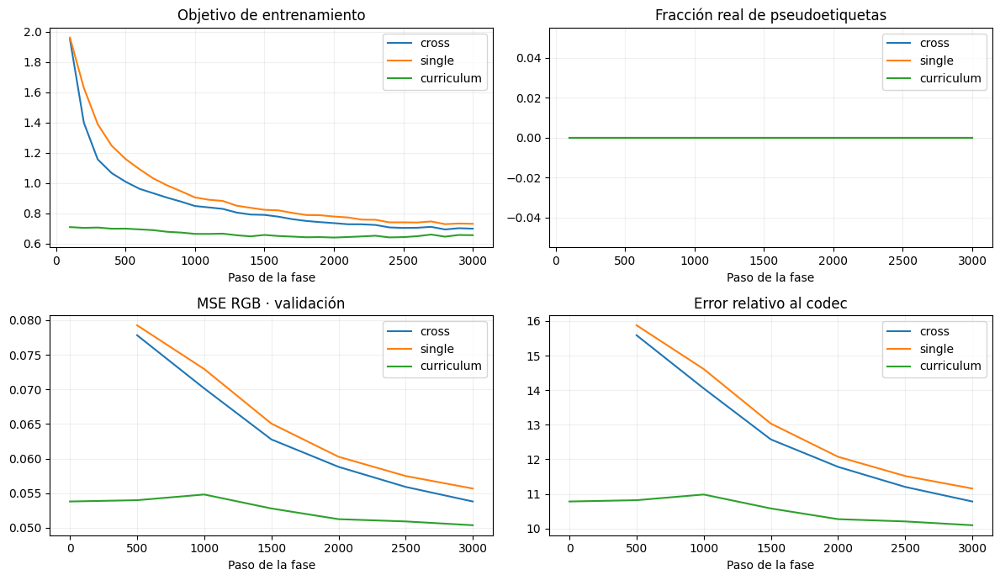

In [10]:
MODELS={};HIST={};VAL_HISTORY={};SUMMARY=[]
for arch in CONFIG['ARQUITECTURAS']:
 model,h,v,info=train_run(arch,'clean');MODELS[arch]=model;HIST[arch]=h;VAL_HISTORY[arch]=v;SUMMARY.append(info)
clean_comparison=pd.DataFrame(SUMMARY).sort_values('best_score')
display(clean_comparison);clean_comparison.to_csv(RUN/'comparacion_arquitecturas_validacion.csv',index=False)
WINNER=clean_comparison.iloc[0].arch
print('Arquitectura elegida con validación limpia:',WINNER)
best_clean=cpu_weights(MODELS[WINNER]);clean_hist=VAL_HISTORY[WINNER].mse.to_list()
ADAPTED,hc,vc,adapt_info=train_run(WINNER,'curriculum',initial=best_clean,clean_hist=clean_hist)
HIST['curriculum']=hc;VAL_HISTORY['curriculum']=vc
# El best de curriculum incluye también el punto de partida sin modificar, evaluado con el mismo criterio.
FINAL=ADAPTED
print('Referencia limpia y adaptación conservadas; el test no elige pesos.')

cfg_scores=[];FINAL.to(DEVICE)
for w in tqdm(CONFIG['CFG_GRID'],desc='Seleccionando CFG · validación',unit='valor'):
 d,_=evaluate2(FINAL,VAL_FIXED,w=w);cfg_scores.append(dict(w=w,mse=macro(d)))
CFG_BEST=float(min(cfg_scores,key=lambda q:q['mse'])['w']);FINAL.cpu()
pd.DataFrame(cfg_scores).to_csv(RUN/'cfg_validacion.csv',index=False)
print('CFG elegido antes del test:',CFG_BEST)
fig,axes=plt.subplots(2,2,figsize=(12,7))
for key,h in HIST.items():
 if len(h):axes[0,0].plot(h.step,h.loss,label=key);axes[0,1].plot(h.step,h.pred_fraction,label=key)
for key,v in VAL_HISTORY.items():
 axes[1,0].plot(v.step,v.mse,label=key);axes[1,1].plot(v.step,v.ratio_codec,label=key)
for ax,title in zip(axes.flat,['Objetivo de entrenamiento','Fracción real de pseudoetiquetas','MSE RGB · validación','Error relativo al codec']):
 ax.set_title(title);ax.set_xlabel('Paso de la fase');ax.grid(alpha=.2);ax.legend()
fig.tight_layout();fig.savefig(RUN/'curvas.png',dpi=140);plt.show();plt.close(fig)

## 11. Test e imágenes en pantalla
Hasta 100 fotos. Las métricas RGB con máscara real son comparables; la intersección con máscaras generadas es un proxy espacial, no una correspondencia semántica. El amarillo es el material de piel de visualización.

Evaluando real:   0%|          | 0/13 [00:00<?, ?lote/s]

Evaluando real:   0%|          | 0/13 [00:00<?, ?lote/s]

Evaluando real:   0%|          | 0/13 [00:00<?, ?lote/s]

Evaluando generada:   0%|          | 0/13 [00:00<?, ?lote/s]

,modelo,mse,psnr,deltaE76
0,cross,0.058249,13.137922,22.775571
1,single,0.066307,12.557687,25.360610
2,curriculum,0.053617,13.589302,21.008250


Panel: 100 fotos. Proxies sobre máscara generada no equivalen a color con GT alineado.


Mostrando ejemplos en pantalla:   0%|          | 0/13 [00:00<?, ?página/s]

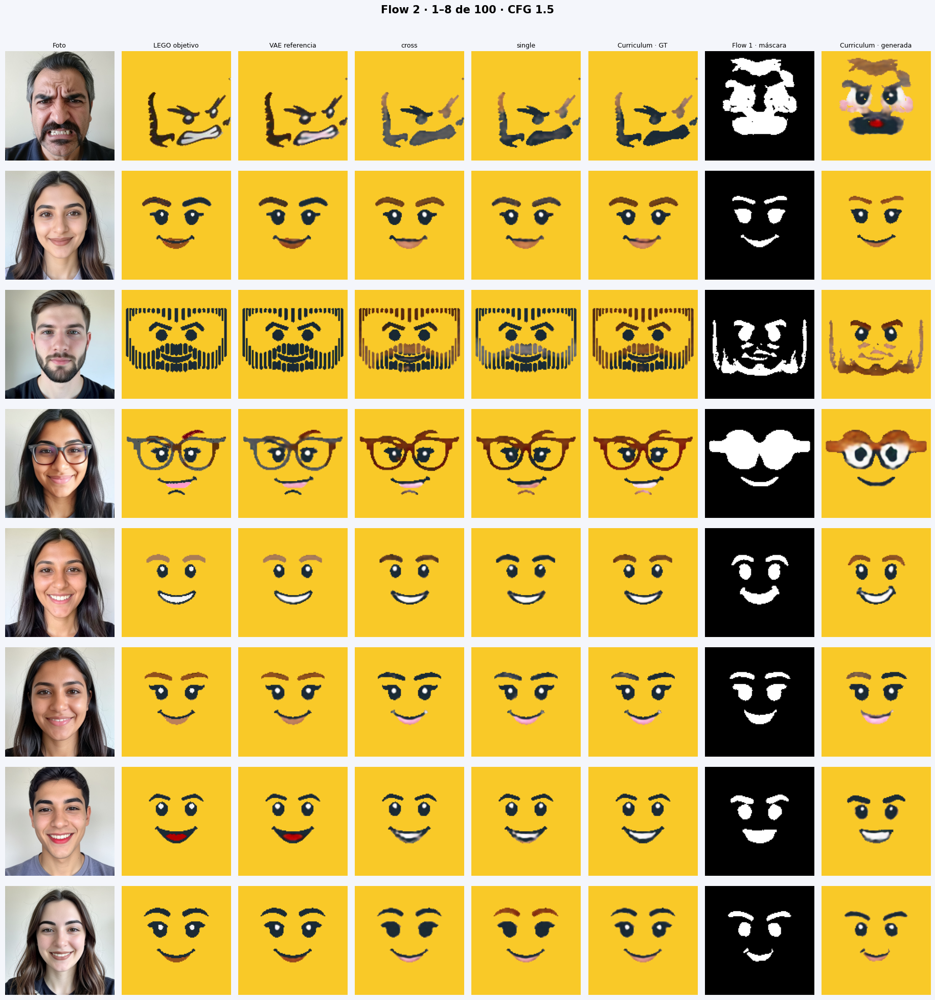

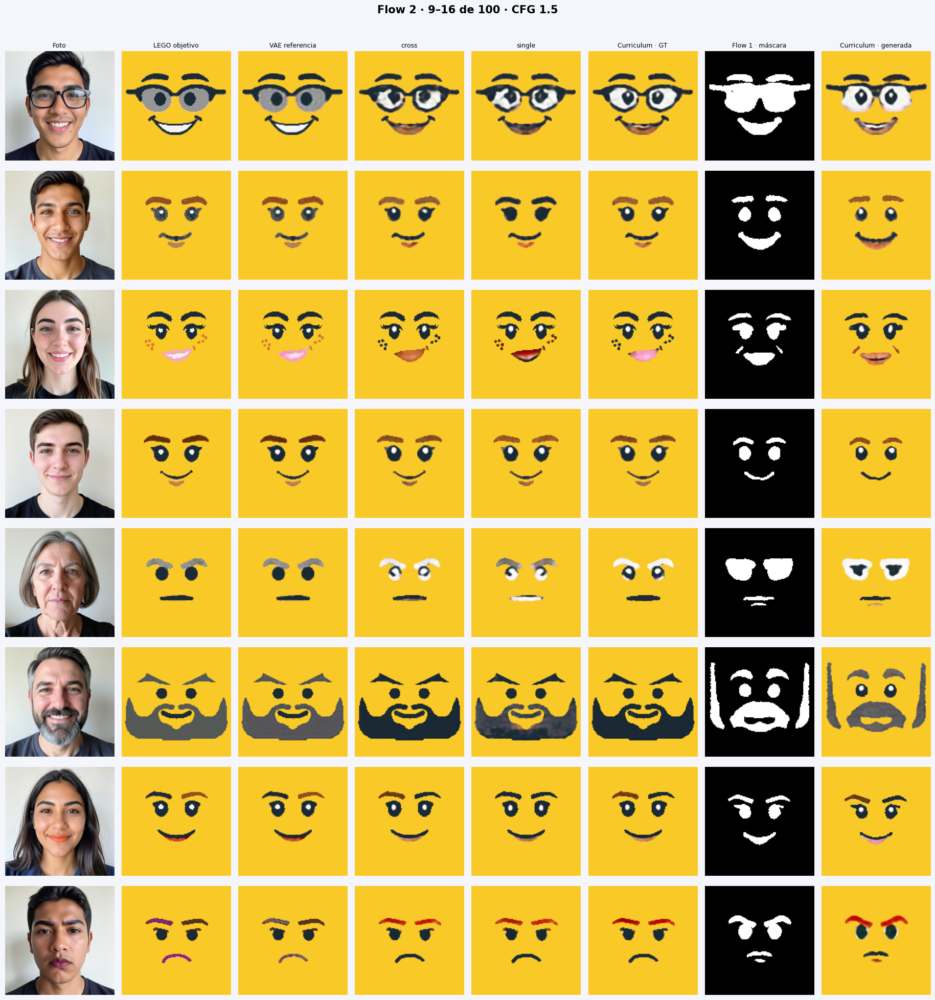

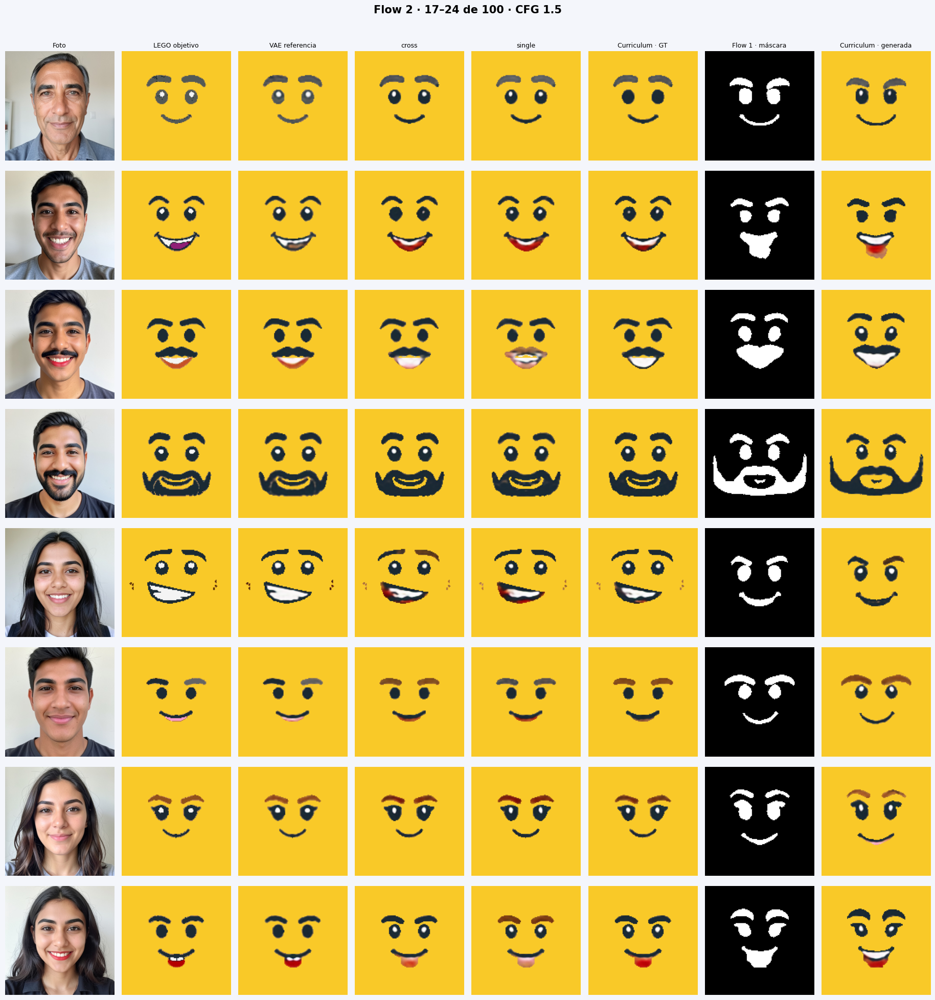

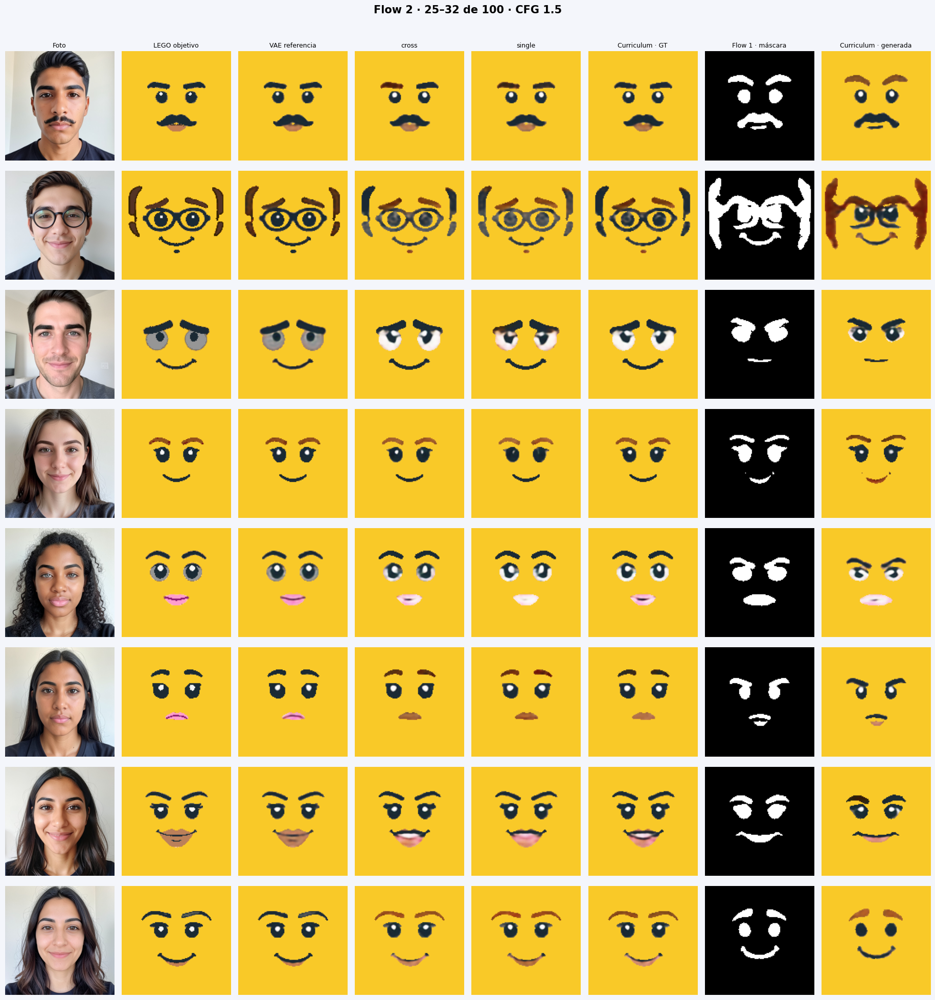

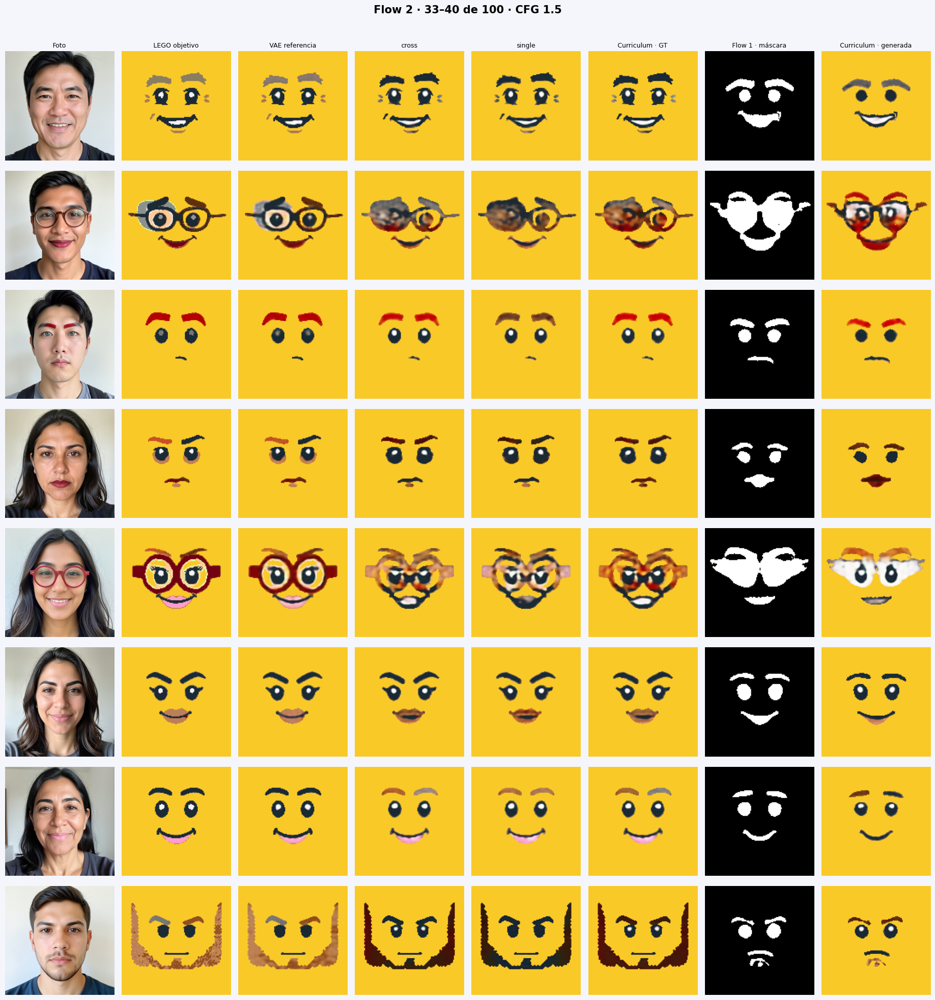

...

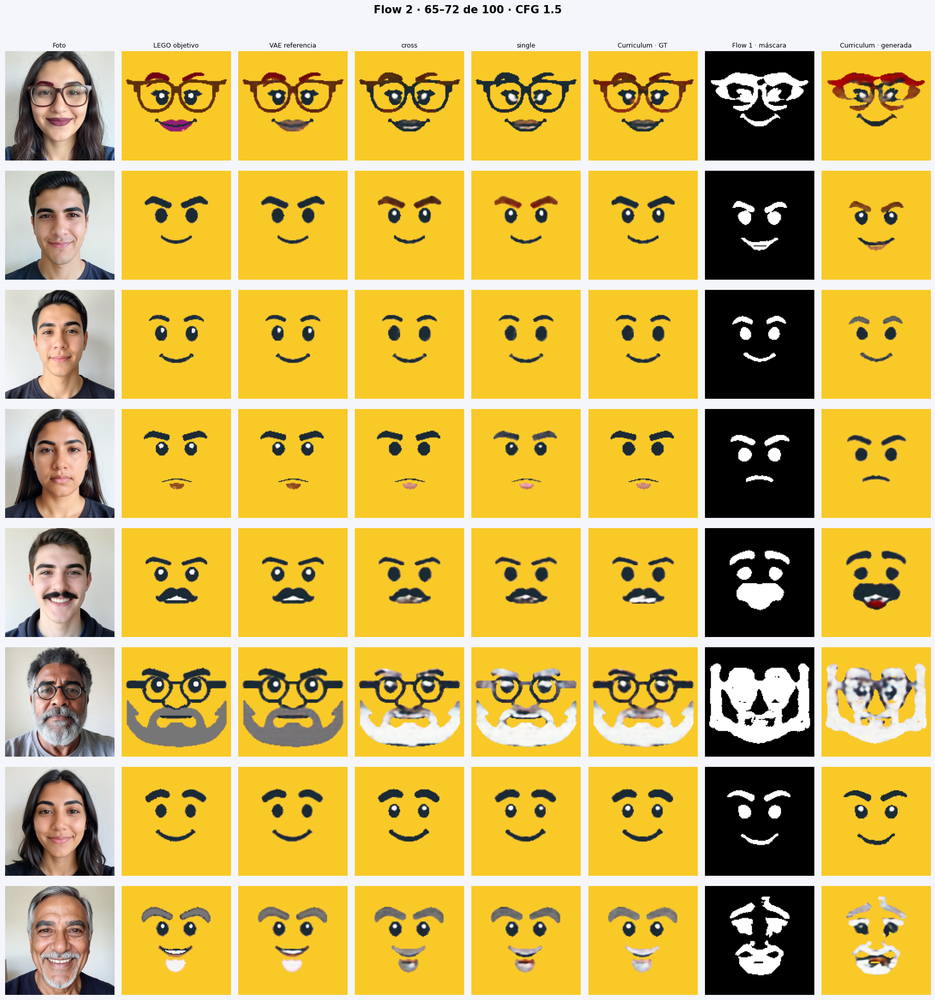

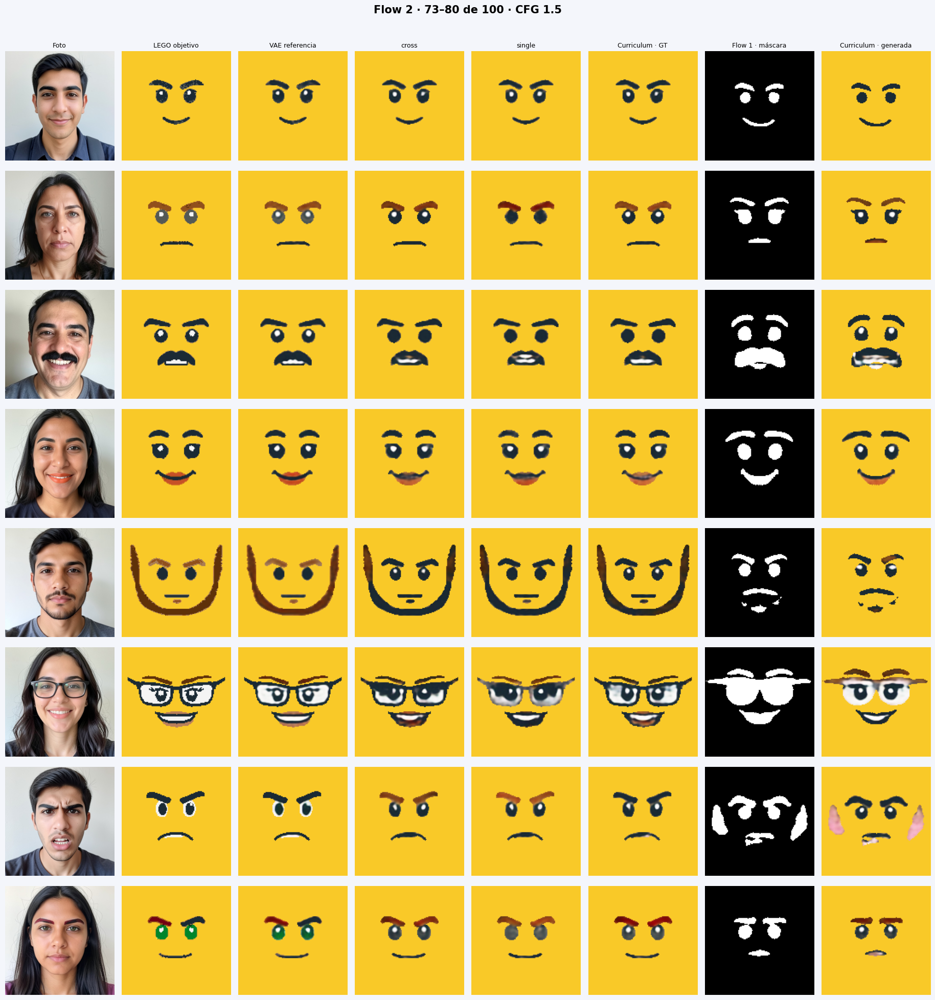

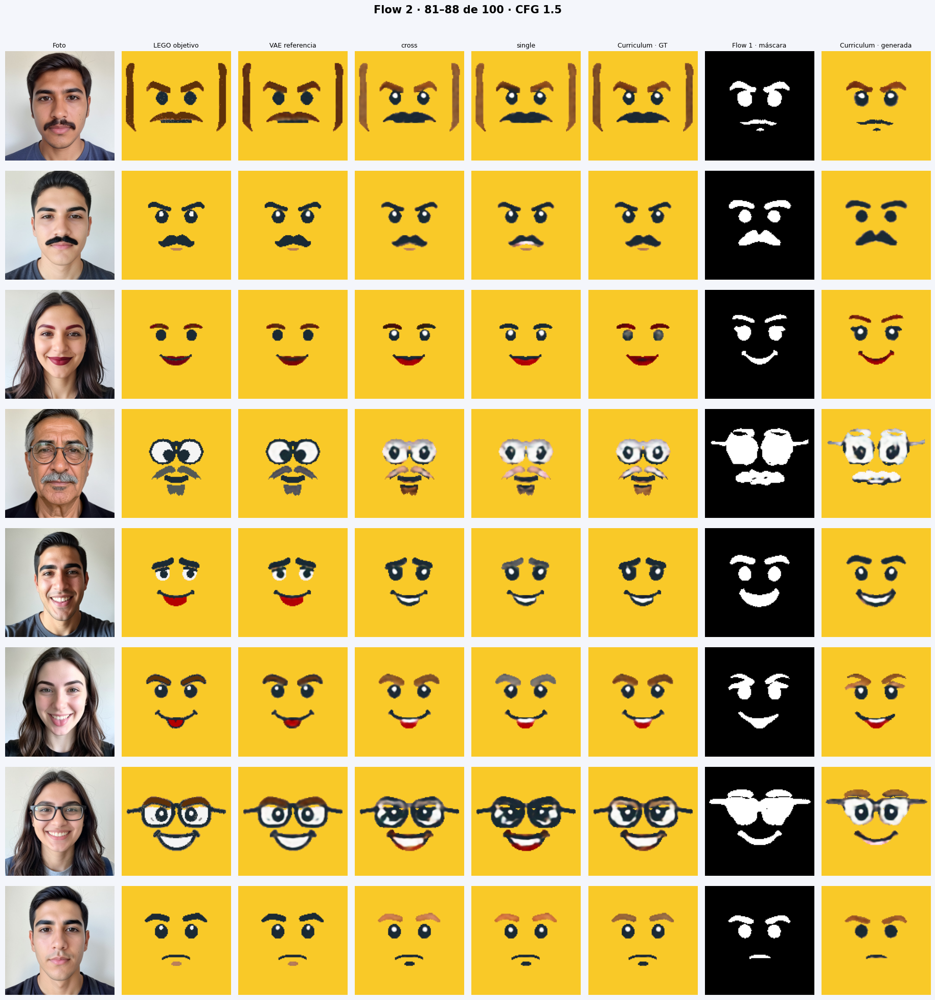

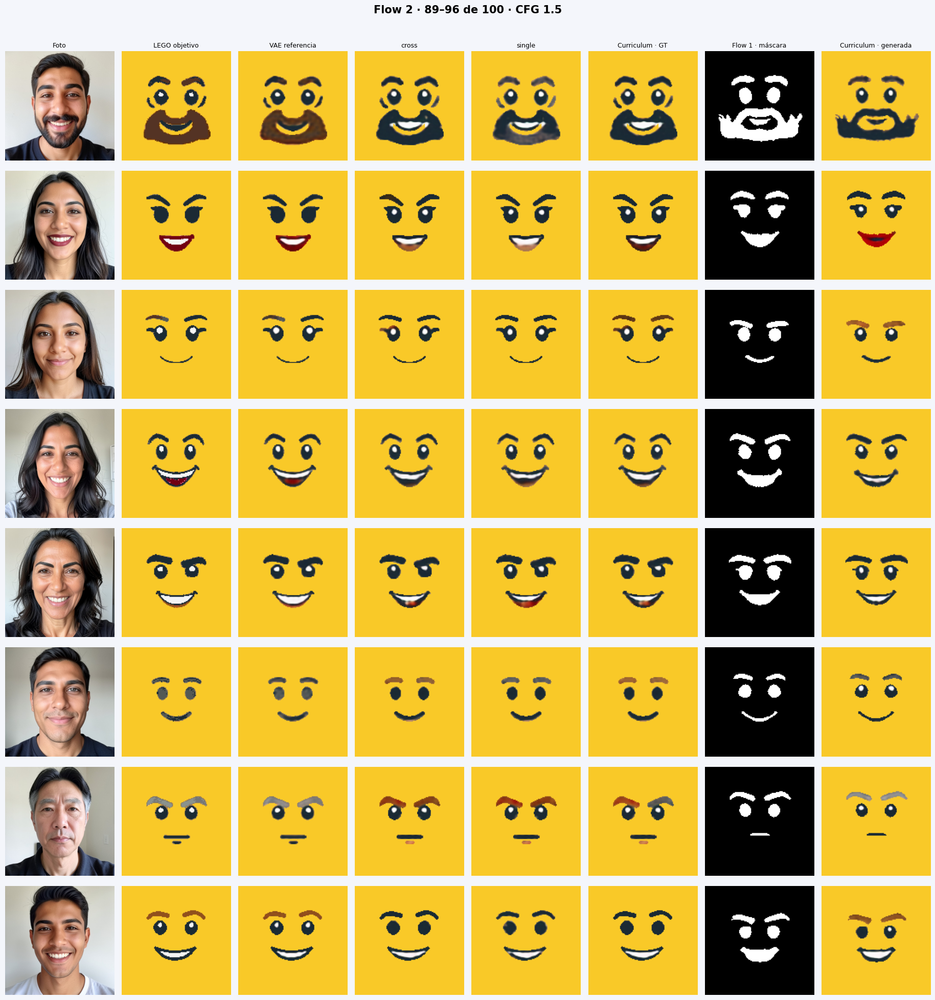

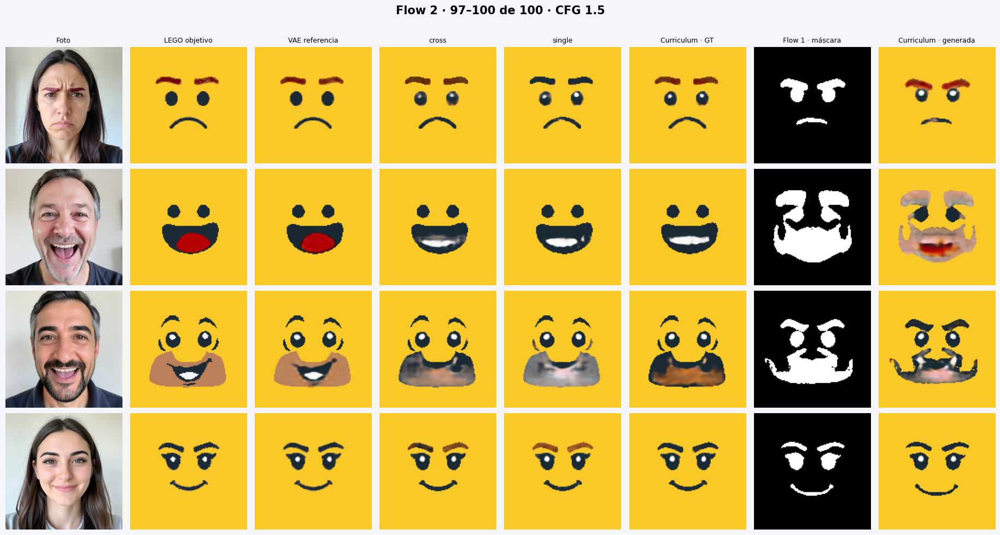

In [11]:
TEST_SCORES={};TEST_IMAGES={}
for name,model in list(MODELS.items())+[('curriculum',FINAL)]:
 model.to(DEVICE)
 w=CFG_BEST if name=='curriculum' else 1.
 scores,images=evaluate2(model,TEST_FIXED,w=w,keep=True,progress=True)
 TEST_SCORES[name]=scores;TEST_IMAGES[name]=images
 scores.to_csv(RUN/f'test_mascara_real_{name}.csv',index=False);model.cpu()
FINAL.to(DEVICE)
generated,GENERATED_IMAGES=evaluate2(FINAL,TEST_FIXED,mode='generada',w=CFG_BEST,keep=True,progress=True)
generated.to_csv(RUN/'test_mascara_generada_proxies.csv',index=False);FINAL.cpu()
comparison=pd.DataFrame([dict(modelo=name,mse=macro(df),psnr=macro(df,'psnr'),deltaE76=macro(df,'deltaE76')) for name,df in TEST_SCORES.items()])
display(comparison);comparison.to_csv(RUN/'comparacion_test.csv',index=False)
for name,df in TEST_SCORES.items():
 by_codec=df.groupby(['codec_color_vio_objetivo','color_i'])[['mse','deltaE76']].mean().groupby('codec_color_vio_objetivo').mean()
 by_codec.to_csv(RUN/f'test_codec_visto_{name}.csv')
print('Panel:',len(TEST_FIXED),'fotos. Proxies sobre máscara generada no equivalen a color con GT alineado.')

def composite(rgb,m):
 rgb=np.asarray(rgb);m=np.asarray(m)
 return np.clip((rgb*m+np.array([.98,.79,.16])[:,None,None]*(1-m)).transpose(1,2,0),0,1)
figdir=RUN/'test_imagenes';figdir.mkdir(exist_ok=True)
for start in tqdm(range(0,len(TEST_FIXED),CONFIG['POR_PAGINA']),desc='Mostrando ejemplos en pantalla',unit='página'):
 end=min(len(TEST_FIXED),start+CONFIG['POR_PAGINA']);ii=TEST_FIXED[start:end];ci=pairs.iloc[ii].color_i.to_numpy()
 c=rgba_batch(ci);m=c[:,3:4]
 with torch.no_grad(),amp_ctx():oracle=color_decode(to_tokens(Z[torch.as_tensor(ci)].to(DEVICE)),m).cpu()
 c=c.cpu();columns=6+len(MODELS)
 fig,axes=plt.subplots(len(ii),columns,figsize=(2.3*columns,2.5*len(ii)),squeeze=False,facecolor='#f4f6fb')
 titles=['Foto','LEGO objetivo','VAE referencia']+list(MODELS)+['Curriculum · GT','Flow 1 · máscara','Curriculum · generada']
 for row,idx in enumerate(ii):
  j=start+row;mask=c[row,3:4].numpy()
  panels=[FOTOS[idx].permute(1,2,0).numpy(),composite(c[row,:3],mask),composite(oracle[row],mask)]
  panels += [composite(TEST_IMAGES[name][j],mask) for name in MODELS]
  panels += [composite(TEST_IMAGES['curriculum'][j],mask),PRED_MASKS[int(idx)][0].numpy(),
             composite(GENERATED_IMAGES[j],PRED_MASKS[int(idx)].numpy())]
  for col,panel in enumerate(panels):
   axes[row,col].imshow(panel,cmap='gray' if panel.ndim==2 else None,vmin=0,vmax=1 if panel.ndim==2 else None)
   axes[row,col].axis('off')
   if row==0:axes[row,col].set_title(titles[col],fontsize=9)
  axes[row,0].set_ylabel(pairs.iloc[idx].id,fontsize=7)
 fig.suptitle(f'Flow 2 · {start+1}–{end} de {len(TEST_FIXED)} · CFG {CFG_BEST:g}',fontsize=15,fontweight='bold')
 fig.tight_layout(rect=[0,0,1,.97]);fig.savefig(figdir/f'test_{start+1:03d}_{end:03d}.png',dpi=120)
 plt.show();plt.close(fig)

## 12. Exportación y UN ZIP completo
Incluye inferencia independiente. La prueba de recarga usa un recorte y una máscara explícita; la generación libre también exige Flow 1 y DINO locales. La integridad CRC del ZIP se comprueba al final.

In [12]:
EXPORT=RUN/'inferencia';EXPORT.mkdir(exist_ok=True)
atomic_save(dict(ema=cpu_weights(FINAL),arch=WINNER,config=CONFIG,dino_dim=DINO_DIM,cfg_w=CFG_BEST,
 data_sha=DATA_SHA,code_sha=CODE_SHA,artifact_role='flow2_color',smoke=CONFIG['SMOKE']),EXPORT/'flow2_color.pt')
(EXPORT/'model.py').write_text('import math\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\n'+MODEL_SOURCE)
(EXPORT/'runtime_constants.json').write_text(json.dumps(dict(flow1_model=FLOW1_MODEL_SOURCE,mask_codec=MASK_CODEC_SOURCE,
 flow1_generate=FLOW1_GENERATE_SOURCE,smoke_vae=SMOKE_VAE_SOURCE,crop=CROP_SOURCE,generate2=GENERATE2_SOURCE)))
(EXPORT/'pipeline.py').write_text(INFERENCE_SOURCE)
manifest=dict(ganador_arquitectura=WINNER,cfg_w=CFG_BEST,smoke=CONFIG['SMOKE'],data_sha=DATA_SHA,
 n_train=len(TRAIN),n_val=len(VAL_FIXED),n_test=len(TEST_FIXED),
 pred_train_aceptadas=len(PRED_TRAIN),colores_pred_aceptados=int(accepted_colors),
 curriculum_llego_a_C=bool((VAL_HISTORY['curriculum'].stage=='C').any()),
 pseudobjetivo='extension_local_uniforme_no_GT_independiente',
 metricas_generadas='proxies_interseccion_sin_correspondencia_semantica',
 eleccion='validacion; test no usado para elegir pesos')
(RUN/'resumen.json').write_text(json.dumps(manifest,indent=2))
(RUN/'config.json').write_text(json.dumps(CONFIG,indent=2))
(RUN/'Flow2_Color_LEGO_Arquitectura_y_Curriculum.md').write_text(RESEARCH_TEXT)

# Script y notebook reproducibles, con las mismas fuentes ejecutadas.
bootstrap=bootstrap_source()
(RUN/'entrenar_flow2.py').write_text(bootstrap+'\n\n'+'\n\n'.join(RUNTIME_SOURCES.values()))
notebook=dict(nbformat=4,nbformat_minor=5,metadata=dict(kernelspec=dict(name='python3',display_name='Python 3',language='python')),
 cells=[dict(cell_type='code',id='bootstrap',metadata={},execution_count=None,outputs=[],source=bootstrap)]+
 [dict(cell_type='code',id=name,metadata={},execution_count=None,outputs=[],source=source) for name,source in RUNTIME_SOURCES.items()])
(RUN/'flow2_completo.ipynb').write_text(json.dumps(notebook,ensure_ascii=False,indent=1))
(RUN/'LEEME.txt').write_text('Flow 2 LEGO color. Entrenamiento solo del flow y adaptadores; VAE y Flow 1 congelados.\n'
 'Reanudar: añade este ZIP y fija CONFIG[REANUDAR_DE] a su ruta, conservando VERSION y el plan.\n'
 'Inferencia: importar inferencia/pipeline.py y usar cargar_pipeline(RAIZ_DE_LA_CARPETA).\n'
 'Incluye modelos best/last, optimizador, RNG, cachés, fotos recortadas, RGBA, métricas y fuentes.\n'
 'Las pseudoetiquetas de máscaras generadas son aproximaciones locales conservadoras.\n')

# Recarga independiente: no depende de los objetos del notebook ni de TOK/FOTOS globales.
pipeline_mod=load_module('flow2_exported_pipeline',EXPORT/'pipeline.py')
pipeline=pipeline_mod.cargar_pipeline(RUN,device=str(DEVICE))
idx=int(TEST_FIXED[0]);mh=PRED_MASKS[idx].numpy()[0]
answer=pipeline.inferir_array(FOTOS[idx].permute(1,2,0).numpy(),mascara=mh,seed=CONFIG['SEMILLA']+idx,mostrar=False)
assert answer['rgba'].shape==(128,128,4) and np.array_equal(answer['rgba'][:,:,3],mh.astype(np.uint8)*255)
assert np.isfinite(answer['rgb']).all()
del pipeline
print('Export independiente comprobado.')

# UN SOLO ZIP: absolutamente todos los archivos de RUN. Se guarda fuera de RUN para evitar incluirse.
full=RUN.parent/(RUN.name+'_TODO.zip')
files=sorted(p for p in RUN.rglob('*') if p.is_file())
with zipfile.ZipFile(full,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=4,allowZip64=True) as z:
 for p in tqdm(files,desc='UN ZIP · toda la salida',unit='archivo'):z.write(p,Path(RUN.name)/p.relative_to(RUN))
with zipfile.ZipFile(full) as z:
 for member in tqdm(z.infolist(),desc='Verificando CRC del ZIP completo',unit='archivo'):
  if member.is_dir():continue
  with z.open(member) as stream:
   for _ in iter(lambda:stream.read(2**20),b''):pass
print('Descargar este único ZIP:',full,'| MiB:',round(full.stat().st_size/2**20,1))
display(FileLink(str(full)))

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Export independiente comprobado.


UN ZIP · toda la salida:   0%|          | 0/95 [00:00<?, ?archivo/s]

Verificando CRC del ZIP completo:   0%|          | 0/95 [00:00<?, ?archivo/s]

Descargar este único ZIP: /kaggle/working/flow2_color/flow2_v1_TODO.zip | MiB: 3793.3


/kaggle/working/flow2_color/flow2_v1_TODO.zip

## Usar el resultado

Descarga únicamente `<VERSION>_TODO.zip`. Para una foto nueva:

```python
import importlib.util
from pathlib import Path
base = Path('/kaggle/input/mi-flow2/flow2_v1')
spec = importlib.util.spec_from_file_location('lego_pipeline', base/'inferencia/pipeline.py')
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)
pipeline = module.cargar_pipeline(base)
resultado = pipeline.inferir_foto('/kaggle/input/mis-fotos/persona.jpg')
Image.fromarray(resultado['rgba']).save('/kaggle/working/cara_generada.png')
```

También se acepta una máscara canónica explícita con `mascara=array_128x128`. El tono de piel
se elige aparte en el material 3D: el RGBA contiene únicamente la estampa.
